# Proyecto SLT — Cuaderno inicial

Este cuaderno es el punto de partida del proyecto de **Traducción de Lengua de Señas (SLT)**.
La idea es entender, con pocos videos y pasos claros, cómo se conectan las piezas:
video → números (características) → modelo → glosa y texto.

## ¿Qué hace este cuaderno?

1. **Carga el modelo base** del repositorio `slt` (sin entrenar).
2. **Prueba 5 videos** de `Data/RawVideos`, cada uno en su propia celda, mostrando el
   *ground truth* (lo que realmente significa el video) y la salida del modelo.
3. **Crea un dataset simple** con esos mismos 5 videos, en el formato que entiende `slt`.
4. **Prueba cada video del dataset** en celdas independientes, comprobando que el dataset
   puede alimentar al modelo.

> **Muy importante:** el modelo se crea con **pesos aleatorios** (estado base). No está
> entrenado, así que sus predicciones todavía no tienen sentido. El objetivo de este
> cuaderno es demostrar que el flujo funciona, no obtener buenos resultados.

## Cómo usar el cuaderno

- Ejecuta las celdas **en orden** con `Shift + Enter`.
- Las celdas de prueba de video son independientes entre sí: puedes volver a ejecutar
  una sin ejecutar las demás.
- Al final hay un resumen con las limitaciones y los siguientes pasos.

## 0. Preparación del entorno

Antes de ejecutar, asegúrate de tener instalado lo que usa el proyecto:

```bash
python -m pip install numpy opencv-python matplotlib mediapipe torch torchtext tensorflow pyyaml
```

- `numpy`: matrices y operaciones numéricas.
- `opencv-python` (`cv2`): leer los cuadros (frames) de los videos `.avi`.
- `matplotlib`: mostrar videos y resultados.
- `mediapipe`: detectar cuerpo y manos en cada frame.
- `torch`: el modelo del repositorio está hecho en PyTorch.
- `torchtext`: el repositorio lo usa para manejar los datos.
- `tensorflow`: el repositorio lo usa **por dentro** para decodificar las glosas (CTC).
  No necesitas saber TensorFlow para este cuaderno.
- `pyyaml`: leer el archivo de configuración `slt/configs/sign.yaml`.

La primera vez que ejecutes las celdas verás mensajes de TensorFlow/MediaPipe en la
consola (por ejemplo, avisos de CUDA). Son normales: este equipo no tiene GPU NVIDIA y
todo se ejecuta en CPU.

> El entorno de este equipo ya está preparado. No actualices `torchtext` sin revisar el repo: la versión validada es 0.6.0 y `slt` usa su API legacy. Si ya está todo instalado, puedes pasar directo a la siguiente celda.


In [7]:
import gzip
import os
import pickle
import sys
import urllib.request
from pathlib import Path
from types import SimpleNamespace

# TensorFlow (usado dentro del repo) y MediaPipe escriben muchos avisos.
# Los bajamos al mínimo para que la salida sea más fácil de leer.
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")
os.environ.setdefault("GLOG_minloglevel", "2")

import cv2
import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import torch
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision

# La raíz del proyecto es la carpeta que contiene Data/, slt/, Investigacion/.
ROOT = Path.cwd()
if not (ROOT / "Data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "slt"))


# Métodos del repositorio `slt` (signjoey) que vamos a usar.
from signjoey.batch import Batch
from signjoey.dataset import load_dataset_file
from signjoey.helpers import load_config
from signjoey.model import build_model
from signjoey.vocabulary import GlossVocabulary, TextVocabulary

RAW = ROOT / "Data" / "RawVideos"
MODELOS_MP = ROOT / "mediapipe_models"
DATASET_DIR = ROOT / "dataset_simple"
DATASET_DIR.mkdir(exist_ok=True)

# Semilla para que los pesos aleatorios del modelo sean reproducibles.
torch.manual_seed(42)
np.random.seed(42)

print("Raíz del proyecto:", ROOT)
print("PyTorch:", torch.__version__)
print("MediaPipe:", mp.__version__)

Raíz del proyecto: c:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador
PyTorch: 2.15.0+cpu
MediaPipe: 1.2.0


### ¿Qué hace cada import?

| Elemento | Para qué se usa |
|---|---|
| `Path` | Construir rutas de archivos de forma segura. |
| `gzip`, `pickle` | Guardar y leer el dataset simple (formato del repo). |
| `urllib.request` | Descargar los modelos de MediaPipe si no existen. |
| `SimpleNamespace` | Crear un objeto pequeño que imita el lote que espera `Batch`. |
| `cv2` | Leer los videos y dibujar puntos sobre los frames. |
| `matplotlib.pyplot` | Mostrar frames y la comparación GT vs. predicción. |
| `mediapipe` | Detectar pose y manos. |
| `numpy` (`np`) | Trabajar con vectores y matrices. |
| `torch` | Crear tensores y ejecutar el modelo. |
| `GlossVocabulary`, `TextVocabulary` | Vocabularios de glosas y palabras. |
| `load_config` | Leer la configuración YAML del modelo. |
| `build_model` | Construir el modelo con la configuración. |
| `Batch` | Adaptar nuestros datos al formato que usa `run_batch`. |
| `load_dataset_file` | Leer un dataset `.test` (gzip + pickle) del repo. |

## Paso 1 — Elegir 5 videos y su *ground truth*

En `Data/RawVideos` los videos están organizados así:

```
Videos <Categoría>/<Señalante>/<Categoría>/<Seña>/<número>.avi
```

El **ground truth** (la respuesta correcta) es el nombre de la carpeta de la seña.
Por ejemplo, `.../Colores/amarillo/1.avi` tiene glosa `amarillo`.

Elegimos estos 5 videos porque tienen:

- 5 glosas diferentes y de una sola palabra,
- 5 señalantes diferentes,
- 3 categorías diferentes (Colores, Cordialidad, Números).

Así el vocabulario queda pequeño y fácil de entender. En este dataset **no hay
traducciones al español**: usaremos la misma glosa como texto real. Es una limitación
del material disponible.

In [8]:
VIDEOS = [
    "Videos Colors/9/Colores/amarillo/1.avi",
    "Videos Colors/8/Colores/azul/1.avi",
    "Videos Courtesy/3/Cordialidad/Apoyar/1.avi",
    "Videos Courtesy/31/Cordialidad/Hola/1.avi",
    "Videos Numbers/30/Numeros/uno/1.avi",
]

GLOSAS_REALES = [Path(v).parent.name for v in VIDEOS]
TEXTOS_REALES = [g.lower() for g in GLOSAS_REALES]

print(f"{'#':<2} {'video':<45} {'categoría':<18} {'señalante':<10} glosa")
print("-" * 95)
for i, video in enumerate(VIDEOS, start=1):
    partes = Path(video).parts
    categoria = partes[0].replace("Videos ", "")
    senalante = partes[1]
    ruta = RAW / video
    print(f"{i:<2} {video:<45} {categoria:<18} {senalante:<10} {GLOSAS_REALES[i-1]}")

assert all((RAW / v).is_file() for v in VIDEOS), "Falta algún video de la lista"
print("\nTodos los videos existen.")

#  video                                         categoría          señalante  glosa
-----------------------------------------------------------------------------------------------
1  Videos Colors/9/Colores/amarillo/1.avi        Colors             9          amarillo
2  Videos Colors/8/Colores/azul/1.avi            Colors             8          azul
3  Videos Courtesy/3/Cordialidad/Apoyar/1.avi    Courtesy           3          Apoyar
4  Videos Courtesy/31/Cordialidad/Hola/1.avi     Courtesy           31         Hola
5  Videos Numbers/30/Numeros/uno/1.avi           Numbers            30         uno



KeyboardInterrupt



**¿Qué acaba de pasar?**

- `VIDEOS` guarda las rutas relativas (sin `Data/RawVideos`), para no escribir rutas
  largas en cada celda.
- `Path(v).parent.name` toma la carpeta que contiene al video: esa es la glosa real.
- `TEXTOS_REALES` pasa la glosa a minúsculas; el vocabulario de texto del repo trabaja
  en minúsculas.
- `assert` detiene la ejecución si algún archivo no existe, para detectar errores pronto.

---

## Paso 2 — Cargar el modelo base

El modelo de `slt` tiene dos salidas:

1. **Reconocimiento (glosas):** una secuencia de glosas, por ejemplo `amarillo`.
2. **Traducción (texto):** una frase en español, por ejemplo `amarillo`.

Para construirlo necesitamos dos vocabularios:

- **Glosas:** las palabras que el modelo puede reconocer. `GlossVocabulary` añade
  automáticamente los símbolos especiales `<si>` (inicio), `<unk>` (desconocido) y
  `<pad>` (relleno).
- **Texto:** las palabras que puede escribir. `TextVocabulary` añade `<unk>`, `<pad>`,
  `<s>` (inicio) y `</s>` (fin).

`load_config` lee `slt/configs/sign.yaml`, que define el tamaño del modelo
(transformer con 3 capas de encoder y 3 de decoder). `build_model` construye el modelo
y lo inicializa con pesos aleatorios (inicialización Xavier). `modelo.eval()` lo pone en
modo inferencia: desactiva dropout, igual que `training=False` en Keras.

In [ ]:
# Vocabulario de glosas: palabras únicas, ordenadas alfabéticamente.
glosas = sorted(set(GLOSAS_REALES))
gls_vocab = GlossVocabulary(tokens=glosas)

# Vocabulario de texto: palabras únicas en minúsculas.
palabras = sorted({p for g in GLOSAS_REALES for p in g.lower().split()})
txt_vocab = TextVocabulary(tokens=palabras)

print("Glosas (", len(gls_vocab), "):", gls_vocab.itos)
print("Palabras (", len(txt_vocab), "):", txt_vocab.itos)

# Configuración del modelo (arquitectura, capas, tamaño de embeddings...).
cfg = load_config(str(ROOT / "slt" / "configs" / "sign.yaml"))

# Construimos el modelo. sgn_dim=225 es el tamaño del vector de cada frame
# (33 puntos de pose + 21 de mano izquierda + 21 de mano derecha, todos con x,y,z).
torch.manual_seed(42)
modelo = build_model(
    cfg["model"],
    sgn_dim=225,
    gls_vocab=gls_vocab,
    txt_vocab=txt_vocab,
    do_recognition=True,
    do_translation=True,
)
modelo.eval()

n_parametros = sum(p.numel() for p in modelo.parameters())
print(f"\nParámetros del modelo: {n_parametros:,}")
print("Dispositivo:", next(modelo.parameters()).device)

Glosas ( 8 ): ['<si>', '<unk>', '<pad>', 'Apoyar', 'Hola', 'amarillo', 'azul', 'uno']
Palabras ( 9 ): ['<unk>', '<pad>', '<s>', '</s>', 'amarillo', 'apoyar', 'azul', 'hola', 'uno']

Parámetros del modelo: 22,202,376
Dispositivo: cpu


**¿Qué significan estos números?**

- El vocabulario de glosas tiene 8 elementos: 3 especiales + 5 glosas.
- El vocabulario de texto tiene 9 elementos: 4 especiales + 5 palabras.
- El modelo tiene ~22.2 millones de parámetros. Son valores aleatorios: todavía no ha
  aprendido nada. En un proyecto real se cargaría un *checkpoint* entrenado con
  `torch.load(...)` y `modelo.load_state_dict(...)`.

---

## Paso 3 — Convertir un video en números (MediaPipe)

El modelo **no** recibe píxeles: recibe un vector de **225 números por frame**.

MediaPipe detecta en cada frame:

- **Pose:** 33 puntos del cuerpo × 3 coordenadas (`x`, `y`, `z`) = **99** números.
- **Mano izquierda:** 21 puntos × 3 = **63** números.
- **Mano derecha:** 21 puntos × 3 = **63** números.

Total: `99 + 63 + 63 = 225`.

Cuando MediaPipe no detecta una parte, rellenamos con ceros. Es una simplificación: en
un proyecto más serio se podría interpolar con el frame anterior (imputación).

Primero descargamos los dos modelos de MediaPipe (solo si no existen). Son los mismos
que usa el repositorio [SignCapture](https://github.com/juanesmz/SignCapture).

In [ ]:
URLS_MODELOS = {
    "pose_landmarker_full.task":
        "https://raw.githubusercontent.com/juanesmz/SignCapture/main/models/pose_landmarker_full.task",
    "hand_landmarker.task":
        "https://raw.githubusercontent.com/juanesmz/SignCapture/main/models/hand_landmarker.task",
}

def descargar_modelos():
    MODELOS_MP.mkdir(exist_ok=True)
    for nombre, url in URLS_MODELOS.items():
        destino = MODELOS_MP / nombre
        if destino.is_file() and destino.stat().st_size > 0:
            print(f"Ya existe: {destino.name}")
            continue
        print(f"Descargando {nombre} ...")
        urllib.request.urlretrieve(url, destino)
        print(f"  guardado en {destino} ({destino.stat().st_size / 1e6:.1f} MB)")

descargar_modelos()

Ya existe: pose_landmarker_full.task
Ya existe: hand_landmarker.task


### Las funciones de extracción

`landmarks_a_matriz` convierte la lista de puntos de MediaPipe en una matriz de
`(n_puntos, 3)`. `vector_frame` une pose + mano izquierda + mano derecha en un solo
vector de 225 números. Para saber qué mano es cuál, compara la muñeca de cada mano
detectada con las muñecas de la pose (puntos 15 y 16).

`extraer_features` recorre el video frame por frame:

1. Lee un frame con OpenCV (`cap.read()`).
2. Lo pasa de BGR (formato de OpenCV) a RGB (formato de MediaPipe).
3. Detecta pose y manos con `detect_for_video`.
4. Convierte las detecciones a un vector de 225 números.
5. Guarda el vector y el frame (para poder visualizarlo después).

Devuelve `sgn` con forma `(n_frames, 225)` y la lista de frames RGB.

In [ ]:
def landmarks_a_matriz(landmarks):
    """Convierte puntos de MediaPipe a una matriz (n_puntos, 3)."""
    return np.array([[p.x, p.y, p.z] for p in landmarks], dtype=np.float32)


def vector_frame(pose, manos):
    """Une pose + mano izquierda + mano derecha en un vector de 225 números."""
    pose = landmarks_a_matriz(pose) if pose is not None else np.zeros((33, 3), np.float32)
    izquierda = np.zeros((21, 3), np.float32)
    derecha = np.zeros((21, 3), np.float32)

    if manos:
        munecas = {"izquierda": pose[15, :2], "derecha": pose[16, :2]}
        usadas = set()
        for mano in manos:
            mano = landmarks_a_matriz(mano)
            muneca = mano[0, :2]
            if np.allclose(munecas["izquierda"], 0) and np.allclose(munecas["derecha"], 0):
                lado = "izquierda"
            else:
                dist_izq = np.linalg.norm(muneca - munecas["izquierda"])
                dist_der = np.linalg.norm(muneca - munecas["derecha"])
                lado = "izquierda" if dist_izq <= dist_der else "derecha"
            if lado in usadas:
                lado = "derecha" if lado == "izquierda" else "izquierda"
            usadas.add(lado)
            if lado == "izquierda":
                izquierda = mano
            else:
                derecha = mano

    return np.concatenate([pose.reshape(-1), izquierda.reshape(-1), derecha.reshape(-1)])


def extraer_features(ruta_video):
    """Convierte un video .avi en (sgn, frames)."""
    opciones_pose = vision.PoseLandmarkerOptions(
        base_options=mp_python.BaseOptions(
            model_asset_path=str(MODELOS_MP / "pose_landmarker_full.task")
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_poses=1,
    )
    opciones_mano = vision.HandLandmarkerOptions(
        base_options=mp_python.BaseOptions(
            model_asset_path=str(MODELOS_MP / "hand_landmarker.task")
        ),
        running_mode=vision.RunningMode.VIDEO,
        num_hands=2,
    )
    pose_lm = vision.PoseLandmarker.create_from_options(opciones_pose)
    mano_lm = vision.HandLandmarker.create_from_options(opciones_mano)

    cap = cv2.VideoCapture(str(ruta_video))
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 30.0

    sgn = []
    frames = []
    i = 0
    try:
        while True:
            ok, frame_bgr = cap.read()
            if not ok:
                break
            frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
            imagen = mp.Image(image_format=mp.ImageFormat.SRGB, data=frame_rgb)
            marca_tiempo = int(i * 1000 / fps)

            resultado_pose = pose_lm.detect_for_video(imagen, marca_tiempo)
            resultado_mano = mano_lm.detect_for_video(imagen, marca_tiempo)

            pose = resultado_pose.pose_landmarks[0] if resultado_pose.pose_landmarks else None
            manos = resultado_mano.hand_landmarks if resultado_mano.hand_landmarks else None

            sgn.append(vector_frame(pose, manos))
            frames.append(frame_rgb)
            i += 1
    finally:
        cap.release()
        pose_lm.close()
        mano_lm.close()

    return np.asarray(sgn, dtype=np.float32), frames

### Probamos la extracción con el primer video

Comprobamos que la matriz tiene forma `(frames, 225)` y que los frames se ven bien.
Los puntos se dibujan así: **verde** = pose, **azul** = mano izquierda, **rojo** = mano
derecha. Si una mano no se detectó, sus puntos son cero y no se dibujan.

INFO: Created TensorFlow Lite XNNPACK delegate for CPU.
W0000 00:00:1792950046.164303  233680 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950046.185633  233679 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950046.199974  233687 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950046.209714  233688 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950046.246765  233680 landmark_projection_calculator.cc:81] Using NORM_RECT without IMAGE_DIMENSIONS is only supported for the square ROI. Provide IMAGE_DIMENSIONS or use PROJECTION_MATRIX.


Forma de sgn: (30, 225) (frames, 225)
Cantidad de frames: 30
Rango x: 0.0 a 0.815819263458252
Rango y: 0.0 a 1.9379138946533203
Frames sin pose: 0 | sin mano izquierda: 11 | sin mano derecha: 28


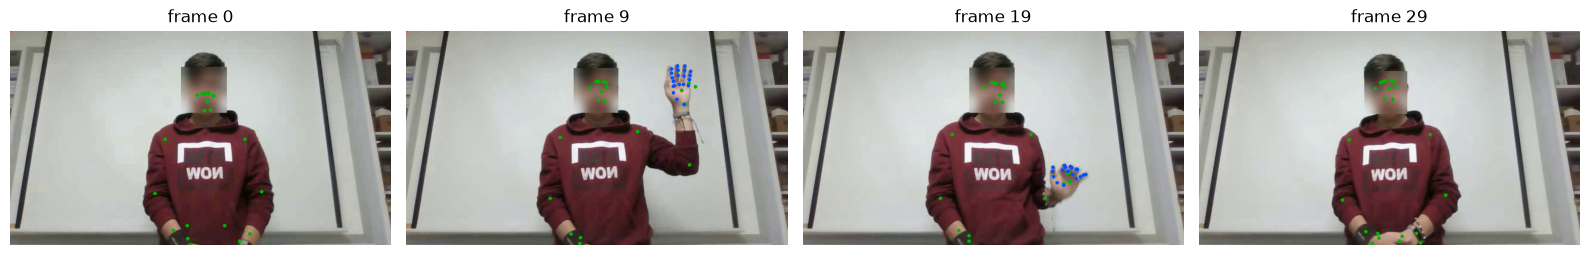

In [ ]:
def dibujar_landmarks(frame, fila):
    """Dibuja pose y manos sobre una copia del frame."""
    imagen = frame.copy()
    alto, ancho = imagen.shape[:2]
    pose = fila[0:99].reshape(33, 3)
    izquierda = fila[99:162].reshape(21, 3)
    derecha = fila[162:225].reshape(21, 3)

    for puntos, color in [(pose, (0, 180, 0)), (izquierda, (0, 80, 255)), (derecha, (255, 60, 60))]:
        for x, y, _ in puntos:
            if 0.0 <= x <= 1.0 and 0.0 <= y <= 1.0:
                cv2.circle(imagen, (int(x * ancho), int(y * alto)), 3, color, -1)
    return imagen


def mostrar_frames_con_landmarks(frames, sgn, n=4):
    """Muestra n frames repartidos a lo largo del video."""
    n = min(n, len(frames))
    indices = np.linspace(0, len(frames) - 1, n).astype(int)
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 3))
    if n == 1:
        axes = [axes]
    for ax, i in zip(axes, indices):
        ax.imshow(dibujar_landmarks(frames[i], sgn[i]))
        ax.set_title(f"frame {i}")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


sgn_ejemplo, frames_ejemplo = extraer_features(RAW / VIDEOS[0])
print("Forma de sgn:", sgn_ejemplo.shape, "(frames, 225)")
print("Cantidad de frames:", len(frames_ejemplo))
print("Rango x:", float(sgn_ejemplo[:, 0::3].min()), "a", float(sgn_ejemplo[:, 0::3].max()))
print("Rango y:", float(sgn_ejemplo[:, 1::3].min()), "a", float(sgn_ejemplo[:, 1::3].max()))

pose_vacia = int(np.all(sgn_ejemplo[:, 0:99] == 0, axis=1).sum())
izq_vacia = int(np.all(sgn_ejemplo[:, 99:162] == 0, axis=1).sum())
der_vacia = int(np.all(sgn_ejemplo[:, 162:225] == 0, axis=1).sum())
print(f"Frames sin pose: {pose_vacia} | sin mano izquierda: {izq_vacia} | sin mano derecha: {der_vacia}")

mostrar_frames_con_landmarks(frames_ejemplo, sgn_ejemplo)

**Interpretación:** cada frame quedó resumido en 225 números. Las coordenadas están
normalizadas entre 0 y 1 (MediaPipe las entrega así), por eso los rangos son pequeños.
Los frames sin mano son normales: MediaPipe no siempre detecta las manos, y en este
cuaderno las rellenamos con ceros.

---

## Paso 4 — Predecir con el modelo

El repositorio no recibe directamente una matriz `(frames, 225)`. Espera un objeto
`Batch` con:

- `sgn`: el tensor de características y su longitud,
- `sequence` y `signer`: nombres de identificación (aquí usamos `"demo"`).

Para no tener que crear todo el sistema de datos de `torchtext`, usamos
`SimpleNamespace`: un objeto vacío al que le podemos añadir atributos. Es como un
"diccionario con puntos": `lote.sgn` en vez de `lote["sgn"]`.

`modelo.run_batch(...)` hace el trabajo pesado:

1. Pasa las características por el **encoder**.
2. Para las glosas, usa **CTC** (Connectionist Temporal Classification) para decidir
   qué glosas aparecen y en qué orden.
3. Para el texto, usa **decodificación greedy**: en cada paso elige la palabra más
   probable.

Con `recognition_beam_size=1` y `translation_beam_size=1` usamos la versión greedy.
Valores mayores activan *beam search* (explora varias opciones), pero tardan más.

> El repo usa TensorFlow **por dentro** para el CTC. No necesitas aprender TensorFlow:
> nosotros solo llamamos a `run_batch` y recibimos los índices de las palabras.

### Mini-glosario de PyTorch (si vienes de Keras)

| PyTorch | Equivalente mental en Keras | Para qué lo usamos |
|---|---|---|
| `torch.from_numpy(sgn)` | `tf.convert_to_tensor(...)` | Convertir la matriz de NumPy en tensor. |
| `tensor.unsqueeze(0)` | añadir una dimensión al inicio | Pasar de `(frames, 225)` a `(1, frames, 225)`: un lote de un solo video. |
| `torch.tensor([T])` | un vector de longitudes | Decirle a `Batch` cuántos frames tiene el video. |
| `modelo.eval()` | `training=False` | Desactivar dropout para inferencia. |
| `torch.no_grad()` | `model.predict(...)` | No calcular gradientes: solo predecir. |

> Si la **predicción de texto** aparece vacía, no es un error: el modelo aleatorio pudo
> haber elegido `</s>` (fin de frase) en el primer paso. Con un modelo entrenado esto
> cambiaría.

In [ ]:
def predecir(sgn):
    """Ejecuta el modelo sobre una matriz (frames, 225) y devuelve glosa y texto."""
    sgn = np.asarray(sgn, dtype=np.float32)
    tensor = torch.from_numpy(sgn)

    # Objeto mínimo que imita lo que Batch espera de torchtext.
    lote_falso = SimpleNamespace(
        sequence=["demo"],
        signer=["demo"],
        sgn=(tensor.unsqueeze(0), torch.tensor([tensor.shape[0]])),
    )
    batch = Batch(
        torch_batch=lote_falso,
        txt_pad_index=txt_vocab.stoi["<pad>"],
        sgn_dim=225,
        is_train=False,
    )

    with torch.no_grad():  # no necesitamos gradientes para predecir
        gls_hyp, txt_hyp, _ = modelo.run_batch(
            batch,
            recognition_beam_size=1,
            translation_beam_size=1,
            translation_max_output_length=10,
        )

    # gls_hyp[0] es una lista de índices; los convertimos a palabras.
    glosa = [gls_vocab.itos[i] for i in gls_hyp[0]]
    # txt_hyp es un arreglo de índices; el repo tiene un método para volver a palabras.
    texto = txt_vocab.arrays_to_sentences(np.asarray(txt_hyp))[0]
    return {"glosa": glosa, "texto": texto}


def mostrar_resultado(ruta_video, frames, sgn, gt_glosa, gt_texto, pred):
    """Muestra 5 frames y compara ground truth con la predicción."""
    n = min(5, len(frames), len(sgn))
    indices = np.linspace(0, len(frames) - 1, n).astype(int)
    fig, axes = plt.subplots(1, n, figsize=(15, 3.2))
    if n == 1:
        axes = [axes]
    for ax, i in zip(axes, indices):
        ax.imshow(dibujar_landmarks(frames[i], sgn[i]))
        ax.set_title(f"frame {i}")
        ax.axis("off")

    glosa_pred = " ".join(pred["glosa"]) if pred["glosa"] else "(vacía)"
    texto_pred = " ".join(pred["texto"]) if pred["texto"] else "(vacío)"
    info = (
        f"VIDEO: {ruta_video.name}    frames: {len(frames)}\n"
        f"GT glosa   : {gt_glosa}\n"
        f"GT texto   : {gt_texto}\n"
        f"Pred glosa : {glosa_pred}\n"
        f"Pred texto : {texto_pred}"
    )
    fig.subplots_adjust(bottom=0.32)
    fig.text(
        0.5, 0.02, info, ha="center", va="bottom", family="monospace", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="#f2f2f2", edgecolor="#999999"),
    )
    plt.show()

### Paso 4.1 — Video 1/5: `amarillo`

Señalante `9` · categoría `Colors`.
Esta celda es independiente de las otras celdas de video: extrae las características,
predice y muestra el resultado.

W0000 00:00:1792950048.666615  233740 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950048.686698  233740 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950048.699831  233747 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950048.709226  233747 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: Videos Colors/9/Colores/amarillo/1.avi
GT glosa: amarillo
Predicción glosa: Hola amarillo Hola amarillo Hola amarillo


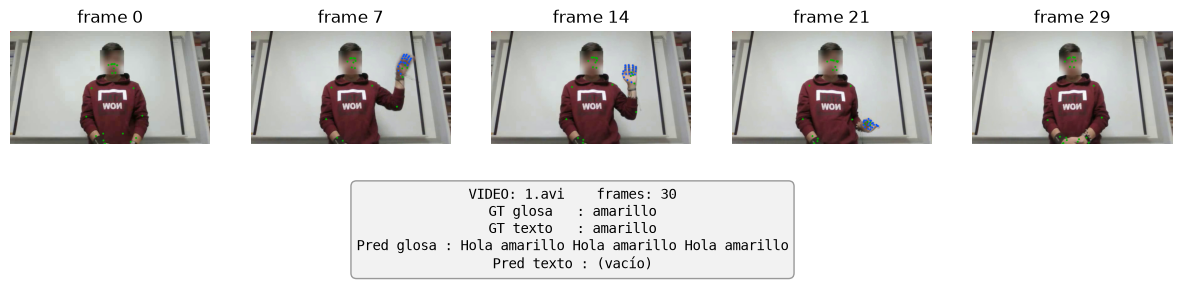

In [ ]:
indice = 0
video = VIDEOS[indice]
gt_glosa = GLOSAS_REALES[indice]
gt_texto = TEXTOS_REALES[indice]

sgn, frames = extraer_features(RAW / video)
pred = predecir(sgn)

print("Video:", video)
print("GT glosa:", gt_glosa)
print("Predicción glosa:", " ".join(pred["glosa"]) or "(vacía)")
mostrar_resultado(RAW / video, frames, sgn, gt_glosa, gt_texto, pred)

### Paso 4.2 — Video 2/5: `azul`

Señalante `8` · categoría `Colors`.
Esta celda es independiente de las otras celdas de video: extrae las características,
predice y muestra el resultado.

W0000 00:00:1792950051.274432  233805 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950051.293167  233805 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950051.306659  233812 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950051.315739  233812 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: Videos Colors/8/Colores/azul/1.avi
GT glosa: azul
Predicción glosa: Hola amarillo Hola amarillo Hola amarillo


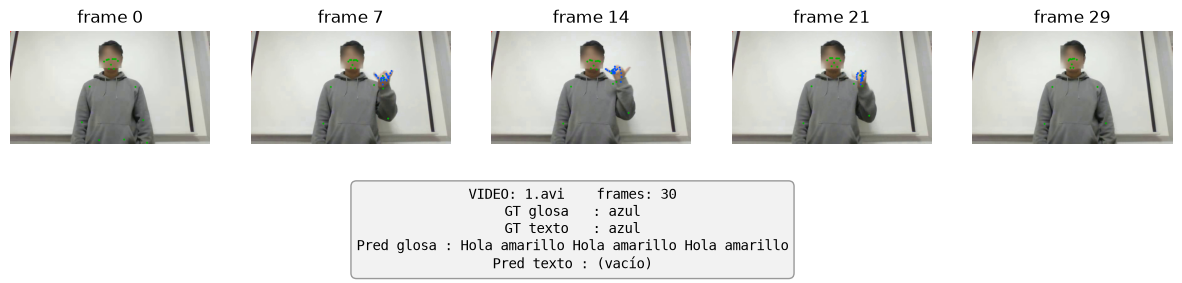

In [ ]:
indice = 1
video = VIDEOS[indice]
gt_glosa = GLOSAS_REALES[indice]
gt_texto = TEXTOS_REALES[indice]

sgn, frames = extraer_features(RAW / video)
pred = predecir(sgn)

print("Video:", video)
print("GT glosa:", gt_glosa)
print("Predicción glosa:", " ".join(pred["glosa"]) or "(vacía)")
mostrar_resultado(RAW / video, frames, sgn, gt_glosa, gt_texto, pred)

### Paso 4.3 — Video 3/5: `Apoyar`

Señalante `3` · categoría `Courtesy`.
Esta celda es independiente de las otras celdas de video: extrae las características,
predice y muestra el resultado.

W0000 00:00:1792950053.351946  233847 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950053.369404  233847 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950053.383560  233852 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950053.392497  233852 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: Videos Courtesy/3/Cordialidad/Apoyar/1.avi
GT glosa: Apoyar
Predicción glosa: Hola amarillo Hola amarillo


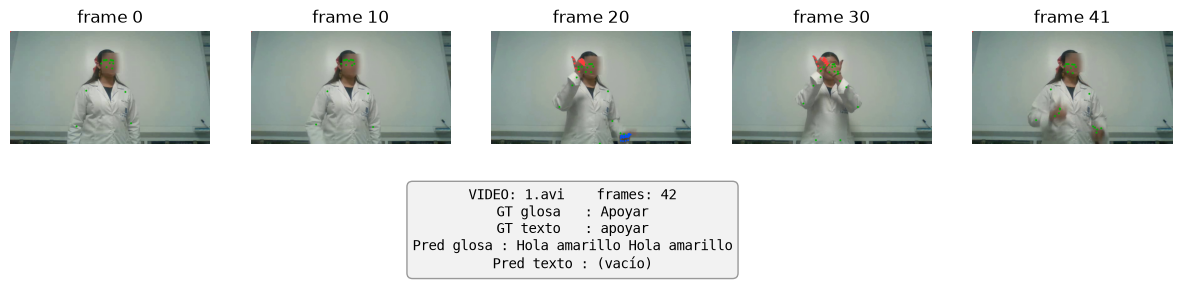

In [ ]:
indice = 2
video = VIDEOS[indice]
gt_glosa = GLOSAS_REALES[indice]
gt_texto = TEXTOS_REALES[indice]

sgn, frames = extraer_features(RAW / video)
pred = predecir(sgn)

print("Video:", video)
print("GT glosa:", gt_glosa)
print("Predicción glosa:", " ".join(pred["glosa"]) or "(vacía)")
mostrar_resultado(RAW / video, frames, sgn, gt_glosa, gt_texto, pred)

### Paso 4.4 — Video 4/5: `Hola`

Señalante `31` · categoría `Courtesy`.
Esta celda es independiente de las otras celdas de video: extrae las características,
predice y muestra el resultado.

W0000 00:00:1792950056.068206  233890 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950056.086040  233890 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950056.097373  233894 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950056.105846  233894 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: Videos Courtesy/31/Cordialidad/Hola/1.avi
GT glosa: Hola
Predicción glosa: Hola amarillo Hola amarillo Hola


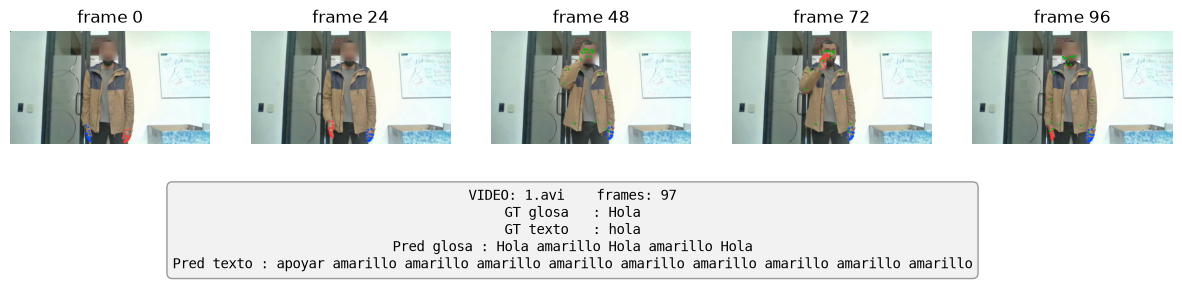

In [ ]:
indice = 3
video = VIDEOS[indice]
gt_glosa = GLOSAS_REALES[indice]
gt_texto = TEXTOS_REALES[indice]

sgn, frames = extraer_features(RAW / video)
pred = predecir(sgn)

print("Video:", video)
print("GT glosa:", gt_glosa)
print("Predicción glosa:", " ".join(pred["glosa"]) or "(vacía)")
mostrar_resultado(RAW / video, frames, sgn, gt_glosa, gt_texto, pred)

### Paso 4.5 — Video 5/5: `uno`

Señalante `30` · categoría `Numbers`.
Esta celda es independiente de las otras celdas de video: extrae las características,
predice y muestra el resultado.

W0000 00:00:1792950061.365527  233943 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950061.383551  233943 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950061.397539  233949 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950061.408355  233949 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


Video: Videos Numbers/30/Numeros/uno/1.avi
GT glosa: uno
Predicción glosa: Hola amarillo Hola amarillo Hola


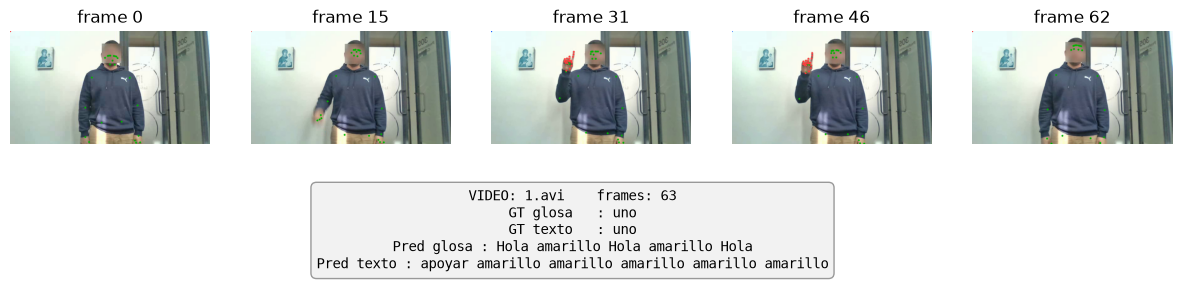

In [ ]:
indice = 4
video = VIDEOS[indice]
gt_glosa = GLOSAS_REALES[indice]
gt_texto = TEXTOS_REALES[indice]

sgn, frames = extraer_features(RAW / video)
pred = predecir(sgn)

print("Video:", video)
print("GT glosa:", gt_glosa)
print("Predicción glosa:", " ".join(pred["glosa"]) or "(vacía)")
mostrar_resultado(RAW / video, frames, sgn, gt_glosa, gt_texto, pred)

**¿Por qué la predicción no coincide con el ground truth?**

Porque el modelo tiene pesos aleatorios. Lo importante aquí es que el flujo
`video → MediaPipe → sgn (frames, 225) → Batch → run_batch → glosa/texto` funciona.
Después de entrenar, las predicciones deberían acercarse al ground truth.

---

## Paso 5 — Crear un dataset simple

Un dataset de `slt` es una **lista de diccionarios**. Cada diccionario tiene:

| Clave | Contenido |
|---|---|
| `name` | Identificador único del ejemplo. |
| `signer` | Número o nombre del señalante. |
| `gloss` | Glosa real (texto). |
| `text` | Traducción real (aquí usamos la glosa en minúsculas). |
| `sign` | Tensor de forma `(frames, 225)` con las características. |

El repo guarda estos datasets con `gzip` + `pickle` y los lee con
`load_dataset_file`. Es el mismo formato que usa para sus archivos `.train`, `.dev` y
`.test`.

En este cuaderno creamos un único archivo `.test` con los 5 videos. **No es un split
real de entrenamiento/prueba**: es un dataset de demostración para comprobar que los
datos pueden pasar por el modelo. En un proyecto real se separan los videos por
señalante para evitar que el modelo memorice personas.

In [ ]:
def senalante(video):
    """El señalante está en la segunda parte de la ruta."""
    return Path(video).parts[1]


ejemplos = []
for i, video in enumerate(VIDEOS):
    print(f"Extrayendo características de {video} ...")
    sgn, _ = extraer_features(RAW / video)
    ejemplos.append(
        {
            "name": f"demo_{i:02d}_{GLOSAS_REALES[i]}",
            "signer": senalante(video),
            "gloss": GLOSAS_REALES[i],
            "text": TEXTOS_REALES[i],
            "sign": torch.from_numpy(sgn),
        }
    )
    print(f"  -> {ejemplos[-1]['name']} | sign {tuple(ejemplos[-1]['sign'].shape)}")

ruta_dataset = DATASET_DIR / "lsc_demo.test"
with gzip.open(ruta_dataset, "wb") as f:
    pickle.dump(ejemplos, f)
print(f"\nDataset guardado en: {ruta_dataset}")
print(f"Tamaño: {ruta_dataset.stat().st_size / 1e6:.2f} MB")

# Verificamos que el repo puede leerlo.
dataset = load_dataset_file(ruta_dataset)
print("\nEjemplos cargados:", len(dataset))
print("Claves:", list(dataset[0].keys()))
print("Forma del primer sign:", tuple(dataset[0]["sign"].shape))
print("Primer ejemplo:", dataset[0]["name"], "|", dataset[0]["gloss"], "|", dataset[0]["text"])

Extrayendo características de Videos Colors/9/Colores/amarillo/1.avi ...


W0000 00:00:1792950064.770738  233989 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950064.789766  233989 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950064.797256  233993 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950064.803119  233993 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  -> demo_00_amarillo | sign (30, 225)
Extrayendo características de Videos Colors/8/Colores/azul/1.avi ...


W0000 00:00:1792950066.801424  234032 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950066.818765  234032 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950066.829179  234038 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950066.834930  234039 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  -> demo_01_azul | sign (30, 225)
Extrayendo características de Videos Courtesy/3/Cordialidad/Apoyar/1.avi ...


W0000 00:00:1792950069.088736  234070 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950069.102805  234071 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950069.111021  234076 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950069.116206  234076 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  -> demo_02_Apoyar | sign (42, 225)
Extrayendo características de Videos Courtesy/31/Cordialidad/Hola/1.avi ...


W0000 00:00:1792950071.478142  234112 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950071.494590  234112 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950071.508637  234116 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950071.517101  234117 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  -> demo_03_Hola | sign (97, 225)
Extrayendo características de Videos Numbers/30/Numeros/uno/1.avi ...


W0000 00:00:1792950076.166749  234157 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950076.184568  234157 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950076.195291  234163 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.
W0000 00:00:1792950076.203518  234163 inference_feedback_manager.cc:121] Feedback manager requires a model with a single signature inference. Disabling support for feedback tensors.


  -> demo_04_uno | sign (63, 225)

Dataset guardado en: /home/Buckminster/Documentos/IA2/Proyecto/dataset_simple/lsc_demo.test
Tamaño: 0.15 MB

Ejemplos cargados: 5
Claves: ['name', 'signer', 'gloss', 'text', 'sign']
Forma del primer sign: (30, 225)
Primer ejemplo: demo_00_amarillo | amarillo | amarillo


**¿Qué hace `gzip.open` + `pickle.dump`?**

- `pickle` convierte objetos de Python (listas, diccionarios, tensores) en bytes.
- `gzip` comprime esos bytes para que el archivo ocupe menos.
- `load_dataset_file` hace el proceso inverso y devuelve la lista de diccionarios.

> Solo debes abrir con `pickle` archivos de tu propio proyecto. Nunca abras un `.pkl`
> descargado de internet sin saber qué contiene.

---

## Paso 6 — Probar cada video del dataset

Ahora usamos el dataset que acabamos de crear. La diferencia con el Paso 4 es que
**no volvemos a ejecutar MediaPipe**: las características ya están guardadas en
`dataset[i]["sign"]`. Solo leemos los frames del video para poder visualizarlo.

Si comparas con el Paso 4, la glosa predicha debe ser la misma: es el mismo video y las
mismas características, solo que ahora vienen del dataset. Esto demuestra que el
dataset es compatible con el modelo.

In [ ]:
def leer_frames(ruta_video):
    """Lee un video y devuelve sus frames en RGB (sin MediaPipe)."""
    cap = cv2.VideoCapture(str(ruta_video))
    frames = []
    while True:
        ok, frame_bgr = cap.read()
        if not ok:
            break
        frames.append(cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB))
    cap.release()
    return frames


def probar_desde_dataset(i):
    """Toma el ejemplo i del dataset, predice y muestra el resultado."""
    ejemplo = dataset[i]
    sgn = ejemplo["sign"].numpy() if hasattr(ejemplo["sign"], "numpy") else np.asarray(ejemplo["sign"])
    pred = predecir(sgn)
    frames = leer_frames(RAW / VIDEOS[i])
    assert len(frames) == sgn.shape[0], "El video y las características no coinciden"

    print(f"[{i}] {ejemplo['name']}")
    print(f"    GT glosa: {ejemplo['gloss']}")
    print(f"    Pred glosa: {' '.join(pred['glosa']) or '(vacía)'}")
    mostrar_resultado(RAW / VIDEOS[i], frames, sgn, ejemplo["gloss"], ejemplo["text"], pred)


for i, ejemplo in enumerate(dataset):
    print(f"{i}: {ejemplo['name']:<28} sign={tuple(ejemplo['sign'].shape)} glosa={ejemplo['gloss']!r}")

0: demo_00_amarillo             sign=(30, 225) glosa='amarillo'
1: demo_01_azul                 sign=(30, 225) glosa='azul'
2: demo_02_Apoyar               sign=(42, 225) glosa='Apoyar'
3: demo_03_Hola                 sign=(97, 225) glosa='Hola'
4: demo_04_uno                  sign=(63, 225) glosa='uno'


### Paso 6.1 — Ejemplo 1/5 del dataset: `amarillo`

Celda independiente: usa `dataset[0]` y no vuelve a extraer características.

[0] demo_00_amarillo
    GT glosa: amarillo
    Pred glosa: Hola amarillo Hola amarillo Hola amarillo


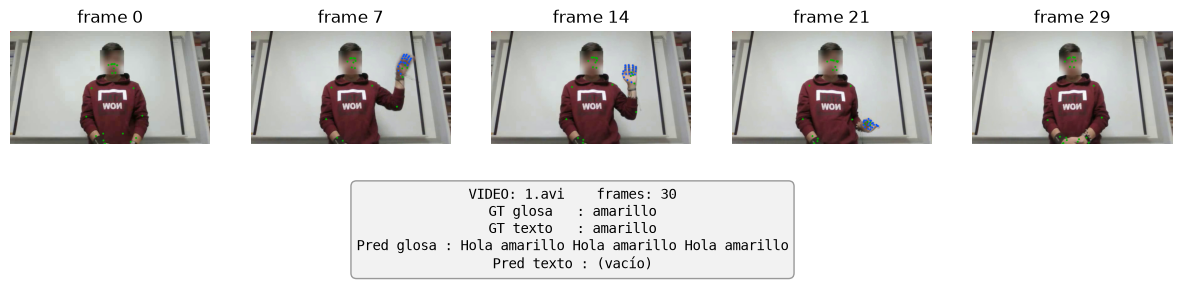

In [ ]:
indice = 0
probar_desde_dataset(indice)

### Paso 6.2 — Ejemplo 2/5 del dataset: `azul`

Celda independiente: usa `dataset[1]` y no vuelve a extraer características.

[1] demo_01_azul
    GT glosa: azul
    Pred glosa: Hola amarillo Hola amarillo Hola amarillo


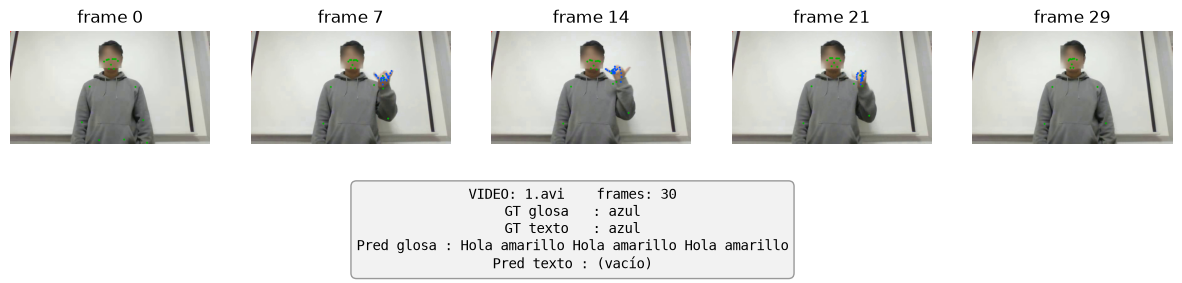

In [ ]:
indice = 1
probar_desde_dataset(indice)

### Paso 6.3 — Ejemplo 3/5 del dataset: `Apoyar`

Celda independiente: usa `dataset[2]` y no vuelve a extraer características.

[2] demo_02_Apoyar
    GT glosa: Apoyar
    Pred glosa: Hola amarillo Hola amarillo


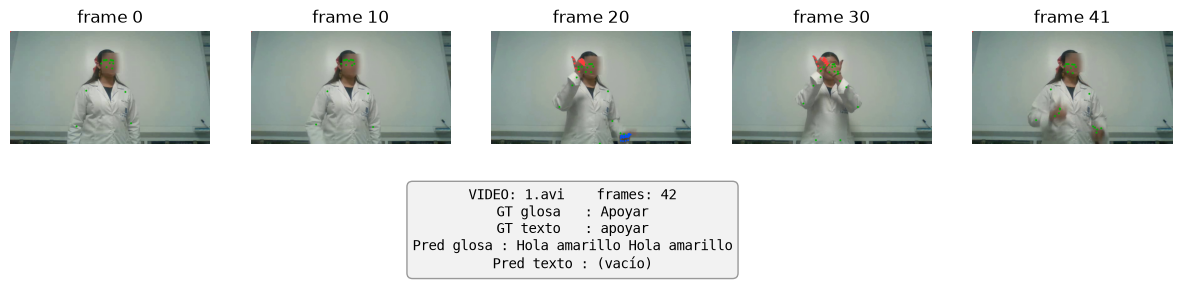

In [ ]:
indice = 2
probar_desde_dataset(indice)

### Paso 6.4 — Ejemplo 4/5 del dataset: `Hola`

Celda independiente: usa `dataset[3]` y no vuelve a extraer características.

[3] demo_03_Hola
    GT glosa: Hola
    Pred glosa: Hola amarillo Hola amarillo Hola


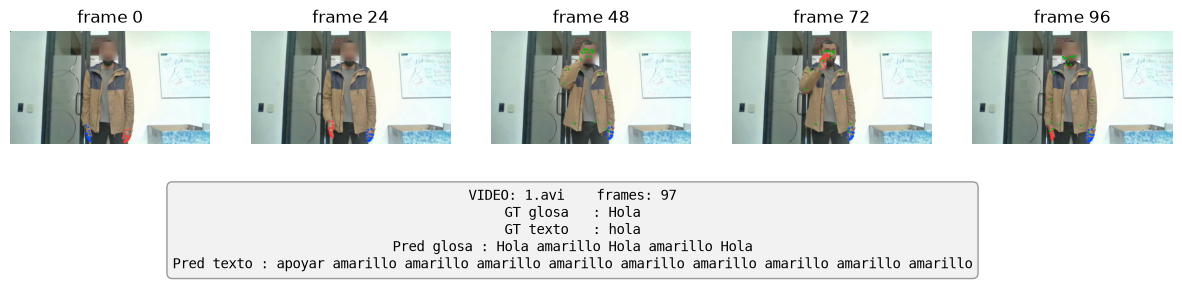

In [ ]:
indice = 3
probar_desde_dataset(indice)

### Paso 6.5 — Ejemplo 5/5 del dataset: `uno`

Celda independiente: usa `dataset[4]` y no vuelve a extraer características.

[4] demo_04_uno
    GT glosa: uno
    Pred glosa: Hola amarillo Hola amarillo Hola


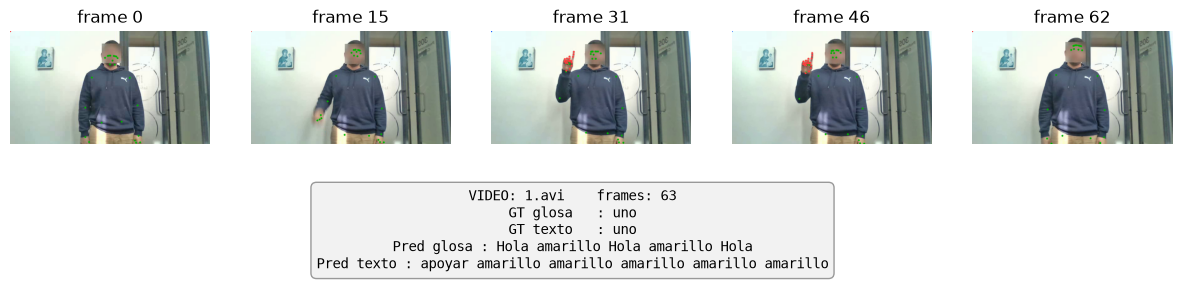

In [ ]:
indice = 4
probar_desde_dataset(indice)

## Glosario de funciones y métodos usados

### Funciones que definimos en este cuaderno

| Función | Qué hace |
|---|---|
| `descargar_modelos()` | Descarga los modelos `.task` de MediaPipe si no existen. |
| `landmarks_a_matriz(...)` | Convierte los puntos de MediaPipe en una matriz `(n_puntos, 3)`. |
| `vector_frame(pose, manos)` | Une pose y manos en un vector de 225 números. |
| `extraer_features(ruta_video)` | Recorre un video y devuelve `sgn (frames, 225)` y los frames RGB. |
| `dibujar_landmarks(frame, fila)` | Dibuja pose (verde), mano izquierda (azul) y derecha (rojo). |
| `mostrar_frames_con_landmarks(...)` | Muestra varios frames con sus puntos. |
| `predecir(sgn)` | Crea el `Batch`, llama a `run_batch` y traduce los índices a glosa/texto. |
| `mostrar_resultado(...)` | Muestra frames y compara GT con la predicción. |
| `senalante(video)` | Extrae el número de señalante de la ruta del video. |
| `leer_frames(ruta_video)` | Lee un video sin MediaPipe, solo para visualizarlo. |
| `probar_desde_dataset(i)` | Toma el ejemplo `i` del dataset, predice y muestra el resultado. |

### Métodos del repositorio `slt` (signjoey)

| Método | Qué hace |
|---|---|
| `load_config(...)` | Lee el YAML con la arquitectura del modelo. |
| `GlossVocabulary(tokens=...)` | Crea el vocabulario de glosas y añade `<si>`, `<unk>`, `<pad>`. |
| `TextVocabulary(tokens=...)` | Crea el vocabulario de texto y añade `<unk>`, `<pad>`, `<s>`, `</s>`. |
| `build_model(...)` | Construye el transformer encoder-decoder y lo inicializa. |
| `Batch(...)` | Prepara características, máscaras y longitudes para el modelo. |
| `modelo.run_batch(...)` | Ejecuta el encoder, el CTC de glosas y el decoder de texto. |
| `txt_vocab.arrays_to_sentences(...)` | Convierte índices de texto en palabras. |
| `load_dataset_file(...)` | Lee un dataset `.test` guardado con gzip + pickle. |

---

## Resumen

En este cuaderno comprobamos el flujo completo con 5 videos:

- [x] Se cargó el modelo base de `slt` con vocabularios pequeños.
- [x] Se convirtieron videos `.avi` en matrices `(frames, 225)` con MediaPipe.
- [x] Se probó el modelo con los 5 videos, mostrando GT y predicción.
- [x] Se creó un dataset simple en formato `slt` (`dataset_simple/lsc_demo.test`).
- [x] Se probó cada ejemplo del dataset en una celda independiente.

### Limitaciones (importantes)

1. **El modelo no está entrenado:** sus pesos son aleatorios y sus predicciones no
   significan nada todavía. El cuaderno demuestra la *tubería*, no la calidad.
2. **No hay traducciones al español:** usamos la glosa como texto real.
3. **La extracción es simplificada:** si MediaPipe no detecta una mano, se rellena con
   ceros. El pipeline original usaba imputación.
4. **El dataset no tiene split real:** los 5 videos son solo una demostración.
5. **Vocabulario mínimo:** el modelo solo conoce 5 glosas y 5 palabras. Con un
   vocabulario mayor y un checkpoint entrenado, las salidas serían distintas.

### Siguientes pasos

1. Reemplazar los pesos aleatorios por un **checkpoint entrenado**.
2. Construir un dataset con **todos** los videos y separar train/dev/test **por
   señalante**.
3. Agregar traducciones reales al español y ampliar los vocabularios.
4. Calcular métricas (WER para glosas, BLEU para texto) y comparar configuraciones.
5. Probar *beam search* (`recognition_beam_size > 1`) y guardar los resultados.

In [ ]:
# Comprobación final: todo está conectado y sin valores inválidos.
print("Videos:", len(VIDEOS))
print("Ejemplos en el dataset:", len(dataset))
print("Vocabulario de glosas:", len(gls_vocab))
print("Vocabulario de texto:", len(txt_vocab))
print("Parámetros del modelo:", f"{sum(p.numel() for p in modelo.parameters()):,}")

for i, ejemplo in enumerate(dataset):
    sgn = ejemplo["sign"]
    assert torch.isfinite(sgn).all(), f"Valores no finitos en el ejemplo {i}"
    assert sgn.shape[1] == 225, f"Dimensión incorrecta en el ejemplo {i}: {sgn.shape}"
    print(f"  OK {i}: {ejemplo['name']:<28} {tuple(sgn.shape)}")

print("\nTodo listo: el dataset puede alimentar al modelo.")

Videos: 5
Ejemplos en el dataset: 5
Vocabulario de glosas: 8
Vocabulario de texto: 9
Parámetros del modelo: 22,202,376
  OK 0: demo_00_amarillo             (30, 225)
  OK 1: demo_01_azul                 (30, 225)
  OK 2: demo_02_Apoyar               (42, 225)
  OK 3: demo_03_Hola                 (97, 225)
  OK 4: demo_04_uno                  (63, 225)

Todo listo: el dataset puede alimentar al modelo.


---
# Parte 2 — Dataset completo, split y entrenamiento

La Parte 1 validó el flujo con 5 videos y un modelo sin entrenar. Esta segunda
parte construye el dataset con los **2.880 videos** de `Data/RawVideos`, hace la
división **60/20/20 por señalante** y entrena el modelo con signjoey.

> El código pesado de extracción, caché, split y entrenamiento vive en
> `lsc_pipeline.py`. Aquí explicamos y ejecutamos cada etapa; el módulo se puede
> leer en paralelo para ver los detalles de implementación.


## Paso 7 — Inventario y extracción de los 2.880 videos

Antes de extraer características verificamos la estructura real de
`Data/RawVideos`:

`Videos <Categoría>/<Señalante>/<Categoría>/<Glosa>/<n>.avi`

La glosa es el nombre de la carpeta de la seña. Como el material no tiene
traducciones al español, `text` será la glosa en minúsculas.


In [ ]:
import sys
from pathlib import Path

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import lsc_pipeline as lp

videos = lp.scan_videos()
assert len(videos) == 2880, f"Se esperaban 2880 videos, hay {len(videos)}"

print(f"Videos: {len(videos):,}")
print(f"Señalantes: {len({v.signer for v in videos})}")
print(f"Glosas: {len({v.gloss for v in videos})}")

for categoria in sorted({v.category for v in videos}):
    del_categoria = [v for v in videos if v.category == categoria]
    print(
        f"  {categoria:8s}: {len(del_categoria):4d} videos, "
        f"{len({v.gloss for v in del_categoria}):2d} glosas"
    )

print("\nPrimeros 3 videos:")
for video in videos[:3]:
    print(f"  {video.name} | señalante={video.signer} | glosa={video.gloss}")

Videos: 2,880
Señalantes: 34
Glosas: 54
  Colors  : 1110 videos, 11 glosas
  Courtesy: 1228 videos, 43 glosas
  Numbers :  542 videos, 10 glosas

Primeros 3 videos:
  Videos Colors/1/Colores/amarillo/1.avi | señalante=1 | glosa=amarillo
  Videos Colors/1/Colores/amarillo/2.avi | señalante=1 | glosa=amarillo
  Videos Colors/1/Colores/amarillo/3.avi | señalante=1 | glosa=amarillo


### Caché reanudable

`lp.build_dataset` guarda un `.npz` por video en
`dataset_completo/features/`. Si el proceso se interrumpe, al volver a
ejecutarlo se reutilizan los archivos que ya existen y son válidos.

Desde una terminal, la corrida completa se puede lanzar con:

```bash
python lsc_pipeline.py dataset --workers 4
```

En el notebook, `LIMITE_VIDEOS` permite probar con pocos videos y
`RECONSTRUIR_DATASET=True` obliga a extraer todo de nuevo. La extracción
completa tarda aproximadamente **1 hora** con 4 procesos en CPU (en esta
máquina: 61,9 minutos para los 2.880 videos); el tiempo depende de la
duración de los videos y del hardware.


In [ ]:
RECONSTRUIR_DATASET = False
LIMITE_VIDEOS = None
N_PROCESOS = 4

ruta_all = lp.DATASET_DIR / "lsc.all"

if ruta_all.is_file() and not RECONSTRUIR_DATASET:
    dataset_full = lp.load_gzip_pickle(ruta_all)
    print(f"Dataset ya existe: {ruta_all}")
else:
    dataset_full = lp.build_dataset(
        videos,
        workers=N_PROCESOS,
        limit=LIMITE_VIDEOS,
        force=RECONSTRUIR_DATASET,
    )

print(f"Ejemplos: {len(dataset_full):,}")
print(f"Forma del primer sign: {tuple(dataset_full[0]['sign'].shape)}")
print(f"Glosas: {len({e['gloss'] for e in dataset_full})}")
print(f"Señalantes: {len({e['signer'] for e in dataset_full})}")

assert all(tuple(e["sign"].shape[1:]) == (225,) for e in dataset_full)
assert all(torch.isfinite(e["sign"]).all() for e in dataset_full)
print("Todas las features tienen 225 columnas y son finitas.")

Dataset ya existe: /home/Buckminster/Documentos/IA2/Proyecto/dataset_completo/lsc.all
Ejemplos: 2,880
Forma del primer sign: (30, 225)
Glosas: 54
Señalantes: 34
Todas las features tienen 225 columnas y son finitas.


## Paso 8 — División 60/20/20 por señalante

La división se hace por **señalante**, no por video: todos los videos de una
persona van al mismo conjunto. Así se evita que el modelo vea en test a alguien
que ya vio en train.

> **Nota sobre Keras:** `validation_split` de Keras no se puede usar aquí porque
> signjoey es PyTorch y espera tres archivos (`train`, `dev`, `test`). El
> equivalente sería reservar 20 % para test y usar `validation_split=0.25`
> sobre el 80 % restante, lo que deja 60 % train + 20 % validación + 20 % test.
> Aquí lo hacemos explícito para que el split sea reproducible y por señalante.

El split fijo produce 1.733 / 579 / 568 videos (60,17 / 20,10 / 19,72 %) y las
54 glosas aparecen en los tres conjuntos.


In [ ]:
if len(dataset_full) != 2880:
    raise RuntimeError(
        "El split 60/20/20 requiere el dataset completo. "
        "Ejecuta esta parte con LIMITE_VIDEOS=None."
    )

splits = lp.split_dataset(dataset_full)

print()
for nombre in ("train", "dev", "test"):
    parte = splits[nombre]
    print(
        f"{nombre:5s}: {len(parte):4d} ejemplos, "
        f"{len({e['gloss'] for e in parte})} glosas"
    )

# Verificamos que los archivos que leerá signjoey existen y tienen el tamaño correcto.
for nombre in ("train", "dev", "test"):
    ruta = lp.DATASET_DIR / f"lsc.{nombre}"
    parte = load_dataset_file(ruta)
    assert len(parte) == len(splits[nombre])
    print(f"  {ruta.name}: {len(parte)} ejemplos")

assert not (lp.TRAIN_SIGNERS & lp.VAL_SIGNERS)
assert not (lp.TRAIN_SIGNERS & lp.TEST_SIGNERS)
assert not (lp.VAL_SIGNERS & lp.TEST_SIGNERS)
print("\nSplit por señalante verificado: no hay solapamiento.")

train: 1733 videos (60.17 %)
dev  :  579 videos (20.10 %)
test :  568 videos (19.72 %)


  guardado /home/Buckminster/Documentos/IA2/Proyecto/dataset_completo/lsc.train


  guardado /home/Buckminster/Documentos/IA2/Proyecto/dataset_completo/lsc.dev


  guardado /home/Buckminster/Documentos/IA2/Proyecto/dataset_completo/lsc.test
Split guardado en /home/Buckminster/Documentos/IA2/Proyecto/dataset_completo/split.json

train: 1733 ejemplos, 54 glosas
dev  :  579 ejemplos, 54 glosas
test :  568 ejemplos, 54 glosas


  lsc.train: 1733 ejemplos
  lsc.dev: 579 ejemplos


  lsc.test: 568 ejemplos

Split por señalante verificado: no hay solapamiento.


## Paso 9 — Configuración de entrenamiento

Generamos `slt/configs/lsc_full.yaml` a partir de `sign.yaml`, pero con:

- `feature_size: 225` (pose + manos, no las 1.024 características de Phoenix).
- `data_path: ./dataset_completo/`.
- `model_dir: ./modelos/lsc_full`.
- CPU (`use_cuda: false`), semilla 42 y batch de 32.
- 100 épocas, LR 3e-4 y validación cada 50 pasos.
- Selección del mejor checkpoint por **WER** de reconocimiento: con textos
  de una sola palabra, BLEU-4 siempre vale 0 y no sirve como criterio.
- Beam size 1 para que la evaluación sea rápida en CPU.

No usamos `validation_split` de Keras: signjoey lee los tres archivos del split
y usa `dev` para validar.


In [ ]:
cfg_full = lp.write_config(epochs=100)

print("data_path:", cfg_full["data"]["data_path"])
print("feature_size:", cfg_full["data"]["feature_size"])
print("train/dev/test:", cfg_full["data"]["train"], "/",
      cfg_full["data"]["dev"], "/", cfg_full["data"]["test"])
print("model_dir:", cfg_full["training"]["model_dir"])
print("use_cuda:", cfg_full["training"]["use_cuda"])
print("batch_size:", cfg_full["training"]["batch_size"])
print("epochs:", cfg_full["training"]["epochs"])
print("early_stopping_metric:", cfg_full["training"]["early_stopping_metric"])
print("config:", lp.CONFIG_PATH)

Configuración guardada en /home/Buckminster/Documentos/IA2/Proyecto/slt/configs/lsc_full.yaml
data_path: ./dataset_completo/
feature_size: 225
train/dev/test: lsc.train / lsc.dev / lsc.test
model_dir: modelos/lsc_full
use_cuda: False
batch_size: 32
epochs: 100
early_stopping_metric: eval_metric
config: /home/Buckminster/Documentos/IA2/Proyecto/slt/configs/lsc_full.yaml


## Paso 10 — Entrenamiento desde cero

No hay un checkpoint preentrenado en el repositorio. Por eso este paso es un
**entrenamiento desde cero**, no un fine-tuning real. Si más adelante se
consigue un checkpoint, se puede agregar `training.load_model` al YAML y
reanudar desde esos pesos.

El comando equivalente desde la raíz es:

```bash
PYTHONPATH=slt python -m signjoey train slt/configs/lsc_full.yaml
```

El entrenamiento guarda en `modelos/lsc_full/` el `best.ckpt`, la configuración,
los vocabularios, los logs y las predicciones de test. Se entrena durante 100
épocas con LR 3e-4 y se guarda el checkpoint con mejor WER de validación. En esta
máquina tardó **2 h 41 min** (100 épocas, validación incluida).

> Con textos de una sola palabra, BLEU-4 es siempre 0 (no hay 4-gramas). Por eso
> la métrica principal es el **WER de reconocimiento** y, para texto, la
> coincidencia exacta o BLEU-1.

In [ ]:
FORZAR_ENTRENAMIENTO = False
ENTRENAR = FORZAR_ENTRENAMIENTO or not (lp.MODEL_DIR / "best.ckpt").is_file()

if ENTRENAR:
    mejor_ckpt = lp.train_model(force=FORZAR_ENTRENAMIENTO)
else:
    mejor_ckpt = lp.MODEL_DIR / "best.ckpt"
    print(f"Checkpoint existente: {mejor_ckpt}")

print(f"Mejor checkpoint: {mejor_ckpt}")

Checkpoint existente: /home/Buckminster/Documentos/IA2/Proyecto/modelos/lsc_full/best.ckpt
Mejor checkpoint: /home/Buckminster/Documentos/IA2/Proyecto/modelos/lsc_full/best.ckpt


In [ ]:
resumen = lp.training_summary(tail=30)
print(resumen if resumen else "Todavía no hay logs de entrenamiento.")

--- validations.txt (últimas 30 líneas) ---
Steps: 4050	Recognition Loss: 43.11162	Translation Loss: 1011.98590	PPL: 2.24990	Eval Metric: wer	WER 45.74	(DEL: 0.60,	INS: 4.04,	SUB: 41.11)	BLEU-4 0.00	(BLEU-1: 58.49,	BLEU-2: 58.79,	BLEU-3: 0.00,	BLEU-4: 0.00)	CHRF 66.89	ROUGE 58.38	LR: 0.00030000	
Steps: 4100	Recognition Loss: 42.57714	Translation Loss: 1244.11597	PPL: 2.70984	Eval Metric: wer	WER 47.83	(DEL: 2.84,	INS: 1.64,	SUB: 43.35)	BLEU-4 0.00	(BLEU-1: 54.81,	BLEU-2: 59.98,	BLEU-3: 0.00,	BLEU-4: 0.00)	CHRF 65.62	ROUGE 52.94	LR: 0.00030000	
Steps: 4150	Recognition Loss: 42.27654	Translation Loss: 1284.98572	PPL: 2.80005	Eval Metric: wer	WER 49.48	(DEL: 2.84,	INS: 1.05,	SUB: 45.59)	BLEU-4 0.00	(BLEU-1: 52.16,	BLEU-2: 57.84,	BLEU-3: 0.00,	BLEU-4: 0.00)	CHRF 61.47	ROUGE 50.17	LR: 0.00030000	
Steps: 4200	Recognition Loss: 39.65177	Translation Loss: 1255.92322	PPL: 2.73559	Eval Metric: wer	WER 46.04	(DEL: 4.63,	INS: 1.35,	SUB: 40.06)	BLEU-4 0.00	(BLEU-1: 51.61,	BLEU-2: 50.07,	BLEU-3: 0.0

## Paso 11 — Evaluación y guardado

Cargamos `modelos/lsc_full/best.ckpt` y probamos el modelo con ejemplos del
conjunto de test. También mostramos las métricas que signjoey escribió durante
la validación y el test.

El checkpoint es un `.ckpt` de PyTorch (no un `.h5` de Keras). Para reutilizarlo
hay que reconstruir el modelo con `build_model`, cargar `model_state` y usar los
vocabularios guardados en la misma carpeta.


In [ ]:
modelo_full, gls_vocab_full, txt_vocab_full = lp.load_trained_model()

n_parametros_full = sum(p.numel() for p in modelo_full.parameters())
print(f"Modelo cargado desde: {lp.MODEL_DIR / 'best.ckpt'}")
print(f"Parámetros: {n_parametros_full:,}")
print(f"Glosas en vocabulario: {len(gls_vocab_full)}")
print(f"Palabras en vocabulario: {len(txt_vocab_full)}")

Modelo cargado desde: /home/Buckminster/Documentos/IA2/Proyecto/modelos/lsc_full/best.ckpt
Parámetros: 22,287,424
Glosas en vocabulario: 64
Palabras en vocabulario: 64


[55] Videos Colors/2/Colores/amarillo/0.avi
    GT glosa: amarillo
    Pred glosa: Baño


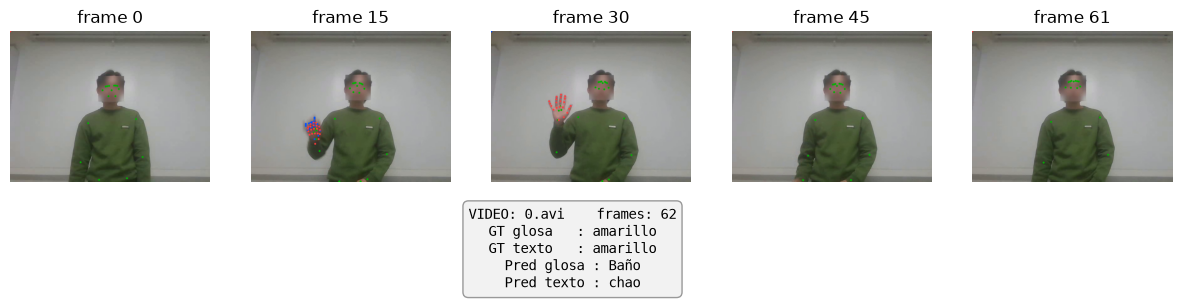

[0] Videos Colors/12/Colores/amarillo/1.avi
    GT glosa: amarillo
    Pred glosa: amarillo


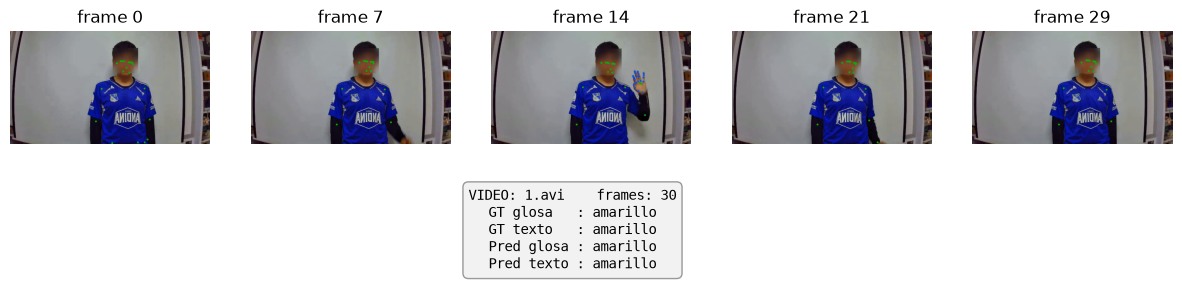

[120] Videos Courtesy/21/Cordialidad/Apoyar/0.avi
    GT glosa: Apoyar
    Pred glosa: Apoyar


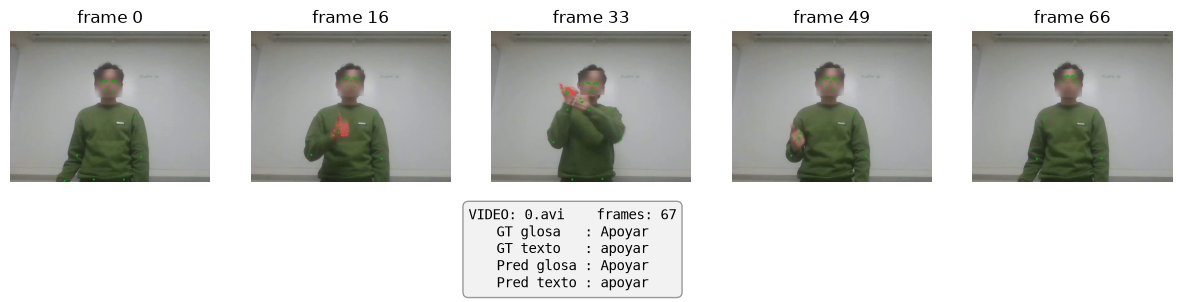

[219] Videos Courtesy/22/Cordialidad/Apoyar/0.avi
    GT glosa: Apoyar
    Pred glosa: Apoyar


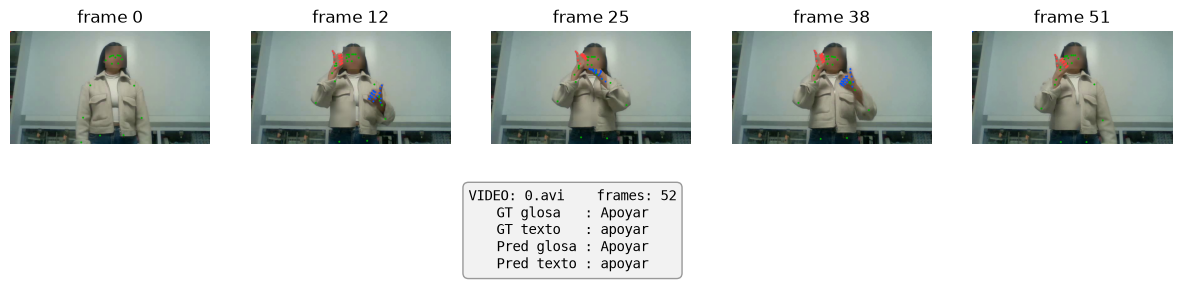

[318] Videos Courtesy/28/Cordialidad/Ayudar/0.avi
    GT glosa: Ayudar
    Pred glosa: Ayudar


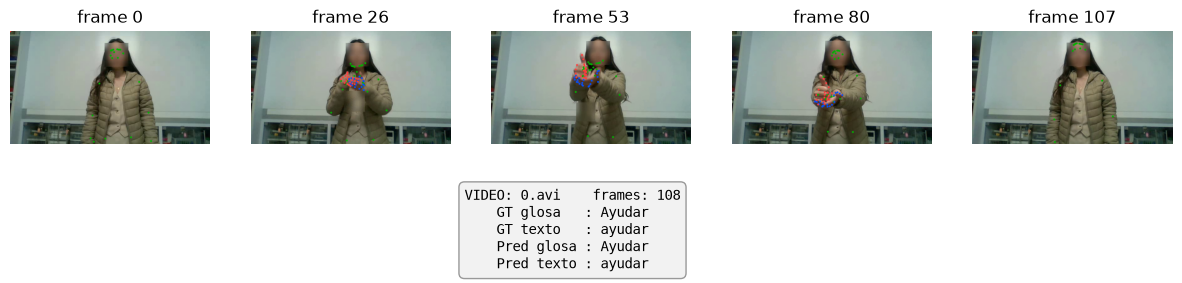

In [ ]:
test_full = load_dataset_file(lp.DATASET_DIR / "lsc.test")

# Un ejemplo por señalante de test, hasta 5 ejemplos.
indices = []
for senalante in sorted(lp.TEST_SIGNERS, key=int):
    for i, ejemplo in enumerate(test_full):
        if ejemplo["signer"] == senalante:
            indices.append(i)
            break
indices = indices[:5]

for i in indices:
    ejemplo = test_full[i]
    sgn = ejemplo["sign"].numpy()
    pred = lp.predict(modelo_full, gls_vocab_full, txt_vocab_full, sgn)
    frames = leer_frames(RAW / ejemplo["name"])
    assert len(frames) == sgn.shape[0], "El video y las features no coinciden"

    print(f"[{i}] {ejemplo['name']}")
    print(f"    GT glosa: {ejemplo['gloss']}")
    print(f"    Pred glosa: {' '.join(pred['glosa']) or '(vacía)'}")
    mostrar_resultado(
        RAW / ejemplo["name"], frames, sgn,
        ejemplo["gloss"], ejemplo["text"], pred,
    )

## Cierre de la Parte 2

Con esto quedan creados:

- `dataset_completo/` con la caché de features, `manifest.json`, `lsc.all` y
  los archivos `lsc.train`, `lsc.dev`, `lsc.test`.
- `slt/configs/lsc_full.yaml` con la configuración del entrenamiento.
- `modelos/lsc_full/` con `best.ckpt`, `config.yaml`, `gls.vocab`,
  `txt.vocab`, `train.log`, `validations.txt` y las predicciones de test.

### Resultados reales (checkpoint del paso 5.500, época 100)

- Validación (dev): **WER 39,61 %**, BLEU-1 61,73, CHRF 68,29.
- Test: **WER 47,31 %** (DEL 2,84, INS 2,99, SUB 41,49).
- Coincidencia exacta en test: **51,23 %** en glosa (291/568) y **51,94 %**
  en texto (295/568).
- BLEU-1 test: 54,33; CHRF 62,53; ROUGE 52,44.
- El modelo reconoce bien los colores (≈90 %) y algunas cortesías; los números
  son débiles (0–33 %).

> BLEU-4 vale 0,00 por construcción: cada referencia tiene una sola palabra y
> no hay 4-gramas. Por eso reportamos WER, coincidencia exacta y BLEU-1.

Limitaciones que siguen vigentes: `text` es la glosa en minúsculas (no hay
traducciones reales), el modelo se entrenó desde cero y en CPU con 1.733
ejemplos, y el split por señalante deja personas no vistas en test. Las
métricas validan la tubería, no una calidad lingüística alta.

Los artefactos generados (`dataset_completo/`, `modelos/`,
`mediapipe_models/`) se pueden borrar y reconstruir; no son código fuente.

In [ ]:
assert len(dataset_full) == 2880
assert len(splits["train"]) + len(splits["dev"]) + len(splits["test"]) == 2880
assert not (lp.TRAIN_SIGNERS & lp.VAL_SIGNERS)
assert not (lp.TRAIN_SIGNERS & lp.TEST_SIGNERS)
assert not (lp.VAL_SIGNERS & lp.TEST_SIGNERS)
assert (lp.MODEL_DIR / "best.ckpt").is_file()

for nombre in ("config.yaml", "gls.vocab", "txt.vocab",
               "train.log", "validations.txt"):
    assert (lp.MODEL_DIR / nombre).is_file(), f"Falta {nombre}"

print("Parte 2 OK")
print(f"Dataset: {len(dataset_full):,} ejemplos")
print(f"Split: {len(splits['train'])} / {len(splits['dev'])} / {len(splits['test'])}")
print(f"Modelo: {lp.MODEL_DIR / 'best.ckpt'}")

# Métricas agregadas de test (el pkl lo genera signjoey al final del entrenamiento).
import pickle

resultados = sorted(lp.MODEL_DIR.glob("best.IT_*.test_results.pkl"))
assert resultados, "No hay resultados de test en modelos/lsc_full/"
with open(resultados[-1], "rb") as f:
    metricas_test = pickle.load(f)

gls_ref = metricas_test["gls_ref"]
gls_hyp = metricas_test["gls_hyp"]
txt_ref = metricas_test["txt_ref"]
txt_hyp = [" ".join(h) if isinstance(h, list) else h
           for h in metricas_test["txt_hyp"]]

aciertos_gls = sum(r == h for r, h in zip(gls_ref, gls_hyp)) / len(gls_ref)
aciertos_txt = sum(r == h for r, h in zip(txt_ref, txt_hyp)) / len(txt_ref)
print(f"Test: {len(gls_ref)} ejemplos")
print(f"WER reconocimiento: {metricas_test['valid_scores']['wer']:.2f}")
print(f"Coincidencia exacta glosa: {aciertos_gls:.2%}")
print(f"Coincidencia exacta texto: {aciertos_txt:.2%}")
print(f"BLEU-1 texto: {metricas_test['valid_scores']['bleu_scores']['bleu1']:.2f}")
print("BLEU-4: 0.00 por construcción (referencias de una sola palabra)")


Parte 2 OK
Dataset: 2,880 ejemplos
Split: 1733 / 579 / 568
Modelo: /home/Buckminster/Documentos/IA2/Proyecto/modelos/lsc_full/best.ckpt
Test: 568 ejemplos
WER reconocimiento: 47.31
Coincidencia exacta glosa: 51.23%
Coincidencia exacta texto: 51.94%
BLEU-1 texto: 54.33
BLEU-4: 0.00 por construcción (referencias de una sola palabra)


---
# Parte 3 — Análisis de errores y mejoras

Las Partes 1 y 2 construyeron la tubería y entrenaron el modelo. Esta tercera
parte **no reentrena nada**: carga el modelo ya entrenado, analiza en qué señas
falla y prueba mejoras concretas sobre las características.

> Esta parte funciona sin la carpeta `Data/RawVideos`. Las características ya
> extraídas viven en `dataset_completo/`, y el modelo en `modelos/lsc_full/`.

## Paso 12 — Preparación: cargar el modelo entrenado

Esta celda es independiente de las Partes 1 y 2: define la raíz del proyecto,
verifica que los archivos necesarios existan y carga `best.ckpt`. Sirve también
como diagnóstico del entorno: si las cuatro comprobaciones salen `OK`, el
proyecto está completo en esta máquina.

In [9]:
from pathlib import Path
import sys, gzip, pickle

# Raíz del proyecto: la carpeta que contiene lsc_pipeline.py.
# No dependemos de Data/ porque los videos no son necesarios en esta parte.
ROOT = Path.cwd()
if not (ROOT / "lsc_pipeline.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Proyecto en:", ROOT, "\n")

import torch
print("OK     torch", torch.__version__)

with gzip.open(ROOT / "dataset_completo" / "lsc.test", "rb") as f:
    test_set = pickle.load(f)
print(f"OK     lsc.test -> {len(test_set)} ejemplos")

ckpt = ROOT / "modelos" / "lsc_full" / "best.ckpt"
print(f"OK     best.ckpt -> {ckpt.stat().st_size / 1e6:.0f} MB")

import lsc_pipeline as lp
modelo, gls_vocab, txt_vocab = lp.load_trained_model()
n_parametros = sum(p.numel() for p in modelo.parameters())
print(f"OK     modelo cargado -> {n_parametros:,} parámetros")

Proyecto en: c:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador 

OK     torch 2.15.0+cpu
OK     lsc.test -> 568 ejemplos
OK     best.ckpt -> 288 MB
OK     modelo cargado -> 22,287,424 parámetros


Todas las secuencias tienen la misma longitud: **30 fotogramas**. Las grabaciones
de LSC-54 fueron estandarizadas, así que no hace falta rellenar ni recortar.

---

## Paso 13 — ¿En qué señas falla el modelo?

El 51,23 % de coincidencia exacta es un promedio, y los promedios esconden la
información útil. Esta celda desglosa ese número por seña usando las predicciones
que signjoey guardó al terminar el entrenamiento (`best.IT_*.test_results.pkl`),
así que **no hay que volver a ejecutar el modelo**.

Buscamos tres cosas:

| Qué miramos | Qué nos dice |
|---|---|
| Exactitud por seña | Si el problema es de categoría o de cantidad de ejemplos. |
| Confusiones frecuentes | Si confunde señas parecidas (problema del modelo) o al azar (problema de datos). |
| Predicciones vacías | Si el CTC está colapsando y no predice nada. |

In [10]:
from collections import Counter, defaultdict

resultados = sorted((ROOT / "modelos" / "lsc_full").glob("best.IT_*.test_results.pkl"))
with open(resultados[-1], "rb") as f:
    metricas = pickle.load(f)

def normalizar(x):
    """Las predicciones pueden venir como lista de tokens o como texto."""
    return " ".join(x) if isinstance(x, (list, tuple)) else str(x)

referencias = [normalizar(r) for r in metricas["gls_ref"]]
predicciones = [normalizar(h) for h in metricas["gls_hyp"]]

aciertos = sum(r == h for r, h in zip(referencias, predicciones))
print(f"Exactitud global: {aciertos}/{len(referencias)} = {aciertos/len(referencias):.1%}\n")

por_clase = defaultdict(lambda: [0, 0])   # glosa -> [aciertos, total]
confusiones = Counter()
for r, h in zip(referencias, predicciones):
    por_clase[r][1] += 1
    if r == h:
        por_clase[r][0] += 1
    else:
        confusiones[(r, h)] += 1

filas = sorted((ok / tot, r, ok, tot) for r, (ok, tot) in por_clase.items())

print("LAS 15 PEORES")
for exactitud, glosa, ok, tot in filas[:15]:
    print(f"  {glosa:<25} {exactitud:6.1%}  ({ok}/{tot})")

print("\nLAS 10 MEJORES")
for exactitud, glosa, ok, tot in filas[-10:][::-1]:
    print(f"  {glosa:<25} {exactitud:6.1%}  ({ok}/{tot})")

print("\nCONFUSIONES MÁS FRECUENTES")
for (real, predicha), veces in confusiones.most_common(12):
    print(f"  {real:<22} -> {predicha if predicha else '(vacío)':<22} {veces}x")

Exactitud global: 291/568 = 51.2%

LAS 15 PEORES
  Maso Menos                  0.0%  (0/6)
  Necesitar                   0.0%  (0/6)
  Tranquilo                   0.0%  (0/6)
  ocho                        0.0%  (0/15)
  seis                        0.0%  (0/15)
  siete                       0.0%  (0/15)
  dies                        6.2%  (1/16)
  cinco                       6.7%  (1/15)
  dos                         6.7%  (1/15)
  cuatro                     13.3%  (2/15)
  Excelente                  16.7%  (1/6)
  Permiso                    16.7%  (1/6)
  Hola                       20.0%  (3/15)
  uno                        20.0%  (3/15)
  Baño                       33.3%  (2/6)

LAS 10 MEJORES
  gris                      100.0%  (11/11)
  blanco                    100.0%  (10/10)
  Perfecto                  100.0%  (6/6)
  Muy mal                   100.0%  (6/6)
  Bienvenido                100.0%  (6/6)
  Buenos dias                93.3%  (14/15)
  verde                      90.9%  (1

## Paso 14 — Por qué fallan los números

El Paso 13 mostró que los números casi nunca se aciertan y que, cuando fallan,
el modelo responde con señas de cortesía (`Bien`, `Mal`, `Chao`) y no con otros
números. Antes de proponer una solución verificamos dos hipótesis:

1. **¿Es un problema de cantidad de datos?** Si las señas con pocos ejemplos
   fallan y las que tienen muchos aciertan, el problema es el desbalance.
2. **¿Hay glosas repetidas entre categorías?** El inventario da 11 + 43 + 10 = 64
   pares categoría-glosa pero solo 54 glosas únicas, así que 10 nombres aparecen
   en dos carpetas distintas. Si fueran señas diferentes con el mismo nombre, el
   modelo estaría recibiendo etiquetas contradictorias.

Ambas se pueden comprobar con `manifest.json`, sin necesidad de los videos.

In [11]:
import json

manifest = json.loads(
    (ROOT / "dataset_completo" / "manifest.json").read_text(encoding="utf-8")
)

videos_por_glosa = Counter(e["gloss"] for e in manifest)
categorias_por_glosa = defaultdict(set)
for e in manifest:
    categorias_por_glosa[e["gloss"]].add(e["category"])

# --- Hipótesis 2: glosas en más de una categoría ---
duplicadas = {g: sorted(c) for g, c in categorias_por_glosa.items() if len(c) > 1}
print(f"Glosas presentes en más de una categoría: {len(duplicadas)}")
for glosa, cats in sorted(duplicadas.items()):
    print(f"  {glosa:<18} {cats}")

# --- Exactitud agregada por categoría ---
agregado = defaultdict(lambda: [0, 0])
for glosa, (ok, tot) in por_clase.items():
    cat = "/".join(sorted(categorias_por_glosa.get(glosa, {"?"})))
    agregado[cat][0] += ok
    agregado[cat][1] += tot

print("\nEXACTITUD POR CATEGORÍA")
for cat, (ok, tot) in sorted(agregado.items()):
    print(f"  {cat:<24} {ok/tot:6.1%}  ({ok}/{tot})")

# --- Hipótesis 1: ¿más datos = más acierto? ---
print("\nCANTIDAD DE VIDEOS vs ACIERTO (de peor a mejor)")
print(f"  {'glosa':<20} {'videos':>7} {'acierto':>9}  categoría")
for glosa, (ok, tot) in sorted(por_clase.items(), key=lambda kv: kv[1][0] / kv[1][1]):
    cat = "/".join(sorted(categorias_por_glosa.get(glosa, {"?"})))
    print(f"  {glosa:<20} {videos_por_glosa.get(glosa, 0):>7} {ok/tot:>8.1%}  {cat}")

Glosas presentes en más de una categoría: 10
  cinco              ['Courtesy', 'Numbers']
  cuatro             ['Courtesy', 'Numbers']
  dies               ['Courtesy', 'Numbers']
  dos                ['Courtesy', 'Numbers']
  nueve              ['Courtesy', 'Numbers']
  ocho               ['Courtesy', 'Numbers']
  seis               ['Courtesy', 'Numbers']
  siete              ['Courtesy', 'Numbers']
  tres               ['Courtesy', 'Numbers']
  uno                ['Courtesy', 'Numbers']

EXACTITUD POR CATEGORÍA
  Colors                    87.5%  (105/120)
  Courtesy                  56.6%  (168/297)
  Courtesy/Numbers          11.9%  (18/151)

CANTIDAD DE VIDEOS vs ACIERTO (de peor a mejor)
  glosa                 videos   acierto  categoría
  Maso Menos                28     0.0%  Courtesy
  Necesitar                 26     0.0%  Courtesy
  Tranquilo                 26     0.0%  Courtesy
  ocho                      54     0.0%  Courtesy/Numbers
  seis                      57     0.

## Paso 15 — Comparación: características crudas vs. normalizadas

El Paso 14 descartó el desbalance de datos. La hipótesis restante es que las
características no conservan la información que distingue a los números: la
configuración de los dedos.

Para comprobarlo entrenamos un modelo pequeño (una LSTM, inspirada en la del
artículo de Mora-Zarate et al.) **dos veces**: con las características tal como
están y con las mismas características normalizadas. Lo que importa no es su
exactitud absoluta, sino la diferencia entre ambas corridas.

**Qué hace la normalización:**

| Parte | Antes | Después |
|---|---|---|
| Cuerpo | Coordenadas respecto a la imagen | Centradas entre los hombros, escaladas por su separación |
| Cada mano | Coordenadas respecto a la imagen | Centradas en su propia muñeca, escaladas por el tamaño de la mano |

La posición de las manos no se pierde: sigue estando en los puntos 15 y 16 de la
pose. Lo que se añade es la **forma** de la mano, independiente de dónde esté.

> Corrección respecto a una versión anterior de este paso: las secuencias **no**
> miden todas 30 fotogramas (hay de 30, 40, 42 y otras). Recortarlas a 30 perdía
> el final de casi la mitad de los videos. Ahora se rellenan hasta la longitud
> máxima y el modelo promedia solo los fotogramas reales.

In [14]:
# import torch.nn as nn
# from torch.utils.data import TensorDataset, DataLoader

# def cargar_split(nombre):
#     with gzip.open(ROOT / "dataset_completo" / f"lsc.{nombre}", "rb") as f:
#         return pickle.load(f)

# train_raw, dev_raw, test_raw = cargar_split("train"), cargar_split("dev"), cargar_split("test")

# longitudes = sorted(e["sign"].shape[0] for e in train_raw)
# T_MAX = longitudes[int(0.95 * len(longitudes))]   # cubre el 95% de los videos
# # T_MAX = max(e["sign"].shape[0] for e in train_raw + dev_raw + test_raw)
# CLASES = sorted({e["gloss"] for e in train_raw})
# A_INDICE = {g: i for i, g in enumerate(CLASES)}
# print(f"Longitud máxima: {T_MAX} fotogramas | Clases: {len(CLASES)}")


# def normalizar(secuencia):
#     """Centra el cuerpo entre los hombros y cada mano en su propia muñeca."""
#     s = secuencia.clone()
#     pose = s[:, 0:99].reshape(-1, 33, 3)
#     izquierda = s[:, 99:162].reshape(-1, 21, 3)
#     derecha = s[:, 162:225].reshape(-1, 21, 3)

#     # Cuerpo: puntos 11 y 12 de MediaPipe son los hombros.
#     hombro_izq, hombro_der = pose[:, 11, :], pose[:, 12, :]
#     centro = ((hombro_izq + hombro_der) / 2).unsqueeze(1)
#     ancho = torch.norm(hombro_izq[:, :2] - hombro_der[:, :2], dim=1)
#     ancho = torch.clamp(ancho, min=1e-3).view(-1, 1, 1)
#     hay_pose = (pose.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
#     pose = torch.where(hay_pose, (pose - centro) / ancho, pose)

#     def normalizar_mano(mano):
#         hay_mano = (mano.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
#         centrada = mano - mano[:, 0:1, :]                      # muñeca al origen
#         escala = centrada.norm(dim=2).max(dim=1).values
#         escala = torch.clamp(escala, min=1e-3).view(-1, 1, 1)
#         return torch.where(hay_mano, centrada / escala, mano)

#     izquierda = normalizar_mano(izquierda)
#     derecha = normalizar_mano(derecha)
#     return torch.cat(
#         [pose.reshape(-1, 99), izquierda.reshape(-1, 63), derecha.reshape(-1, 63)],
#         dim=1,
#     )


# def a_tensores(datos, transformar=None):
#     """Rellena hasta T_MAX y devuelve datos, longitudes reales y etiquetas."""
#     X = torch.zeros(len(datos), T_MAX, 225)
#     L = torch.zeros(len(datos), dtype=torch.long)
#     y = torch.zeros(len(datos), dtype=torch.long)
#     for i, ejemplo in enumerate(datos):
#         secuencia = ejemplo["sign"].float()
#         if transformar is not None:
#             secuencia = transformar(secuencia)
#         X[i, : secuencia.shape[0]] = secuencia
#         L[i] = secuencia.shape[0]
#         y[i] = A_INDICE[ejemplo["gloss"]]
#     return X, L, y


# class ClasificadorLSTM(nn.Module):
#     def __init__(self, n_clases, dim_entrada=225):
#         super().__init__()
#         self.lstm1 = nn.LSTM(dim_entrada, 256, batch_first=True)
#         self.lstm2 = nn.LSTM(256, 128, batch_first=True)
#         self.lstm3 = nn.LSTM(128, 64, batch_first=True)
#         self.dropout = nn.Dropout(0.5)
#         self.densas = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_clases))

#     def forward(self, x, longitudes):
#         x, _ = self.lstm1(x); x = torch.relu(x)
#         x, _ = self.lstm2(x); x = torch.relu(x)
#         x, _ = self.lstm3(x)
#         # Promediar solo los fotogramas reales, ignorando el relleno.
#         pasos = torch.arange(x.shape[1], device=x.device)[None, :]
#         mascara = (pasos < longitudes[:, None]).float().unsqueeze(-1)
#         x = (x * mascara).sum(1) / mascara.sum(1)
#         return self.densas(self.dropout(x))


# def entrenar(transformar, etiqueta, epocas=120, semilla=42):
#     torch.manual_seed(semilla)
#     Xtr, Ltr, ytr = a_tensores(train_raw, transformar)
#     Xdv, Ldv, ydv = a_tensores(dev_raw, transformar)
#     Xte, Lte, yte = a_tensores(test_raw, transformar)

#     modelo = ClasificadorLSTM(len(CLASES))
#     optim = torch.optim.Adam(modelo.parameters(), lr=1e-3)
#     criterio = nn.CrossEntropyLoss()
#     cargador = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=32, shuffle=True)

#     def exactitud(X, L, y):
#         modelo.eval()
#         with torch.no_grad():
#             return (modelo(X, L).argmax(1) == y).float().mean().item()

#     mejor, mejores_pesos = 0.0, None
#     for epoca in range(1, epocas + 1):
#         modelo.train()
#         for xb, lb, yb in cargador:
#             optim.zero_grad()
#             criterio(modelo(xb, lb), yb).backward()
#             optim.step()
#         acc = exactitud(Xdv, Ldv, ydv)
#         if acc > mejor:
#             mejor, mejores_pesos = acc, {k: v.clone() for k, v in modelo.state_dict().items()}
#         if epoca % 20 == 0:
#             print(f"  época {epoca:3d}  dev {acc:.1%}")

#     modelo.load_state_dict(mejores_pesos)
#     modelo.eval()
#     with torch.no_grad():
#         predicciones = modelo(Xte, Lte).argmax(1)
#     acc_test = (predicciones == yte).float().mean().item()
#     print(f"{etiqueta}: mejor dev {mejor:.1%} | test {acc_test:.1%}\n")
#     return predicciones, acc_test


# print("\n=== 1) CARACTERÍSTICAS CRUDAS ===")
# pred_crudas, acc_crudas = entrenar(None, "CRUDAS")

# print("=== 2) CARACTERÍSTICAS NORMALIZADAS ===")
# pred_norm, acc_norm = entrenar(normalizar, "NORMALIZADAS")






import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

def cargar_split(nombre):
    with gzip.open(ROOT / "dataset_completo" / f"lsc.{nombre}", "rb") as f:
        return pickle.load(f)

train_raw, dev_raw, test_raw = cargar_split("train"), cargar_split("dev"), cargar_split("test")

# longitudes = sorted(e["sign"].shape[0] for e in train_raw)
# T_MAX = longitudes[int(0.95 * len(longitudes))]   # cubre el 95% de los videos
# (Con el percentil 95, a_tensores falla en los videos más largos porque no los recorta.)
T_MAX = max(e["sign"].shape[0] for e in train_raw + dev_raw + test_raw)
CLASES = sorted({e["gloss"] for e in train_raw})
A_INDICE = {g: i for i, g in enumerate(CLASES)}
print(f"Longitud máxima: {T_MAX} fotogramas | Clases: {len(CLASES)}")


def normalizar(secuencia):
    """Centra el cuerpo entre los hombros y cada mano en su propia muñeca."""
    s = secuencia.clone()
    pose = s[:, 0:99].reshape(-1, 33, 3)
    izquierda = s[:, 99:162].reshape(-1, 21, 3)
    derecha = s[:, 162:225].reshape(-1, 21, 3)

    # Cuerpo: puntos 11 y 12 de MediaPipe son los hombros.
    hombro_izq, hombro_der = pose[:, 11, :], pose[:, 12, :]
    centro = ((hombro_izq + hombro_der) / 2).unsqueeze(1)
    ancho = torch.norm(hombro_izq[:, :2] - hombro_der[:, :2], dim=1)
    ancho = torch.clamp(ancho, min=1e-3).view(-1, 1, 1)
    hay_pose = (pose.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
    pose = torch.where(hay_pose, (pose - centro) / ancho, pose)

    def normalizar_mano(mano):
        hay_mano = (mano.abs().sum(dim=(1, 2)) > 0).view(-1, 1, 1)
        centrada = mano - mano[:, 0:1, :]                      # muñeca al origen
        escala = centrada.norm(dim=2).max(dim=1).values
        escala = torch.clamp(escala, min=1e-3).view(-1, 1, 1)
        return torch.where(hay_mano, centrada / escala, mano)

    izquierda = normalizar_mano(izquierda)
    derecha = normalizar_mano(derecha)
    return torch.cat(
        [pose.reshape(-1, 99), izquierda.reshape(-1, 63), derecha.reshape(-1, 63)],
        dim=1,
    )


def a_tensores(datos, transformar=None):
    """Rellena hasta T_MAX y devuelve datos, longitudes reales y etiquetas."""
    X = torch.zeros(len(datos), T_MAX, 225)
    L = torch.zeros(len(datos), dtype=torch.long)
    y = torch.zeros(len(datos), dtype=torch.long)
    for i, ejemplo in enumerate(datos):
        secuencia = ejemplo["sign"].float()
        if transformar is not None:
            secuencia = transformar(secuencia)
        X[i, : secuencia.shape[0]] = secuencia
        L[i] = secuencia.shape[0]
        y[i] = A_INDICE[ejemplo["gloss"]]
    return X, L, y


class ClasificadorLSTM(nn.Module):
    def __init__(self, n_clases, dim_entrada=225):
        super().__init__()
        self.lstm1 = nn.LSTM(dim_entrada, 256, batch_first=True)
        self.lstm2 = nn.LSTM(256, 128, batch_first=True)
        self.lstm3 = nn.LSTM(128, 64, batch_first=True)
        self.dropout = nn.Dropout(0.5)
        self.densas = nn.Sequential(nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, n_clases))

    def forward(self, x, longitudes):
        x, _ = self.lstm1(x); x = torch.relu(x)
        x, _ = self.lstm2(x); x = torch.relu(x)
        x, _ = self.lstm3(x)
        # Promediar solo los fotogramas reales, ignorando el relleno.
        pasos = torch.arange(x.shape[1], device=x.device)[None, :]
        mascara = (pasos < longitudes[:, None]).float().unsqueeze(-1)
        x = (x * mascara).sum(1) / mascara.sum(1)
        return self.densas(self.dropout(x))


def entrenar(transformar, etiqueta, epocas=120, semilla=42, ruta=None):
    torch.manual_seed(semilla)
    Xtr, Ltr, ytr = a_tensores(train_raw, transformar)
    Xdv, Ldv, ydv = a_tensores(dev_raw, transformar)
    Xte, Lte, yte = a_tensores(test_raw, transformar)

    modelo = ClasificadorLSTM(len(CLASES))
    optim = torch.optim.Adam(modelo.parameters(), lr=1e-3)
    criterio = nn.CrossEntropyLoss()
    cargador = DataLoader(TensorDataset(Xtr, Ltr, ytr), batch_size=32, shuffle=True)

    def exactitud(X, L, y):
        modelo.eval()
        with torch.no_grad():
            return (modelo(X, L).argmax(1) == y).float().mean().item()

    mejor, mejores_pesos = 0.0, None
    historial = []
    for epoca in range(1, epocas + 1):
        modelo.train()
        for xb, lb, yb in cargador:
            optim.zero_grad()
            criterio(modelo(xb, lb), yb).backward()
            optim.step()
        acc = exactitud(Xdv, Ldv, ydv)
        if acc > mejor:
            mejor, mejores_pesos = acc, {k: v.clone() for k, v in modelo.state_dict().items()}
        if epoca % 20 == 0:
            print(f"  época {epoca:3d}  dev {acc:.1%}")
            historial.append((epoca, acc))

    modelo.load_state_dict(mejores_pesos)
    modelo.eval()
    with torch.no_grad():
        predicciones = modelo(Xte, Lte).argmax(1)
    acc_test = (predicciones == yte).float().mean().item()
    print(f"{etiqueta}: mejor dev {mejor:.1%} | test {acc_test:.1%}\n")

    # Guardar el modelo para no tener que reentrenarlo la próxima vez.
    if ruta is not None:
        ruta.parent.mkdir(parents=True, exist_ok=True)
        torch.save({"model_state": mejores_pesos, "clases": CLASES,
                    "mejor_dev": mejor, "acc_test": acc_test,
                    "historial": historial}, ruta)
    return predicciones, acc_test


def cargar_lstm(transformar, etiqueta, ruta):
    """Carga una LSTM ya entrenada y recalcula sus predicciones de test."""
    guardado = torch.load(ruta, map_location="cpu")
    assert guardado["clases"] == CLASES, "Las clases del modelo guardado no coinciden"

    modelo = ClasificadorLSTM(len(CLASES))
    modelo.load_state_dict(guardado["model_state"])
    modelo.eval()

    Xte, Lte, yte = a_tensores(test_raw, transformar)
    with torch.no_grad():
        predicciones = modelo(Xte, Lte).argmax(1)
    acc_test = (predicciones == yte).float().mean().item()

    print(f"  (modelo ya entrenado, cargado desde {ruta.name})")
    for epoca, acc in guardado["historial"]:
        print(f"  época {epoca:3d}  dev {acc:.1%}")
    print(f"{etiqueta}: mejor dev {guardado['mejor_dev']:.1%} | test {acc_test:.1%}\n")
    return predicciones, acc_test


DIR_LSTM = ROOT / "modelos" / "lstm"
RUTA_CRUDAS = DIR_LSTM / "lstm_crudas.pt"
RUTA_NORM = DIR_LSTM / "lstm_normalizadas.pt"

print("\n=== 1) CARACTERÍSTICAS CRUDAS ===")
if RUTA_CRUDAS.is_file():
    pred_crudas, acc_crudas = cargar_lstm(None, "CRUDAS", RUTA_CRUDAS)
else:
    pred_crudas, acc_crudas = entrenar(None, "CRUDAS", ruta=RUTA_CRUDAS)

print("=== 2) CARACTERÍSTICAS NORMALIZADAS ===")
if RUTA_NORM.is_file():
    pred_norm, acc_norm = cargar_lstm(normalizar, "NORMALIZADAS", RUTA_NORM)
else:
    pred_norm, acc_norm = entrenar(normalizar, "NORMALIZADAS", ruta=RUTA_NORM)


Longitud máxima: 335 fotogramas | Clases: 54

=== 1) CARACTERÍSTICAS CRUDAS ===
  época  20  dev 6.4%
  época  40  dev 16.8%
  época  60  dev 20.9%
  época  80  dev 22.5%
  época 100  dev 25.9%
  época 120  dev 26.9%
CRUDAS: mejor dev 29.4% | test 25.4%

=== 2) CARACTERÍSTICAS NORMALIZADAS ===
  época  20  dev 18.1%
  época  40  dev 31.4%
  época  60  dev 45.3%
  época  80  dev 48.2%
  época 100  dev 50.1%
  época 120  dev 51.3%
NORMALIZADAS: mejor dev 54.2% | test 50.0%



In [15]:
# Comparación lado a lado: ¿mejoraron los números?
_, _, y_test = a_tensores(test_raw)
numeros = sorted(g for g, c in categorias_por_glosa.items() if len(c) > 1)

def desglose(predicciones):
    cat = defaultdict(lambda: [0, 0])
    glo = defaultdict(lambda: [0, 0])
    for ejemplo, real, pred in zip(test_raw, y_test.tolist(), predicciones.tolist()):
        c = "/".join(sorted(categorias_por_glosa[ejemplo["gloss"]]))
        acierto = int(real == pred)
        cat[c][0] += acierto; cat[c][1] += 1
        glo[ejemplo["gloss"]][0] += acierto; glo[ejemplo["gloss"]][1] += 1
    return cat, glo

cat_c, glo_c = desglose(pred_crudas)
cat_n, glo_n = desglose(pred_norm)

print(f"{'CATEGORÍA':<24} {'crudas':>9} {'normaliz.':>10} {'cambio':>9}")
for c in sorted(cat_c):
    a = cat_c[c][0] / cat_c[c][1]
    b = cat_n[c][0] / cat_n[c][1]
    print(f"{c:<24} {a:>8.1%} {b:>10.1%} {b-a:>+8.1%}")

print(f"\n{'NÚMERO':<12} {'crudas':>9} {'normaliz.':>10} {'cambio':>9}")
for g in numeros:
    a = glo_c[g][0] / glo_c[g][1]
    b = glo_n[g][0] / glo_n[g][1]
    print(f"{g:<12} {a:>8.1%} {b:>10.1%} {b-a:>+8.1%}")

CATEGORÍA                   crudas  normaliz.    cambio
Colors                      61.7%      83.3%   +21.7%
Courtesy                    19.5%      48.1%   +28.6%
Courtesy/Numbers             7.9%      27.2%   +19.2%

NÚMERO          crudas  normaliz.    cambio
cinco            0.0%       0.0%    +0.0%
cuatro           0.0%      33.3%   +33.3%
dies            18.8%      62.5%   +43.8%
dos              0.0%      26.7%   +26.7%
nueve            6.7%      20.0%   +13.3%
ocho            26.7%      26.7%    +0.0%
seis             0.0%      40.0%   +40.0%
siete           13.3%      20.0%    +6.7%
tres            13.3%      13.3%    +0.0%
uno              0.0%      26.7%   +26.7%


## Paso 16 — Reentrenar el Transformer con características normalizadas

El Paso 15 mostró que la normalización casi duplica la exactitud de un modelo
pequeño (25,4 % → 50,0 % en test) y que mejora las tres categorías. Aplicamos
ahora la misma transformación a los datos que consume signjoey.

No hace falta volver a procesar los videos: se normalizan las características ya
extraídas y se guardan como un conjunto nuevo (`lsc_norm.*`). El conjunto
original se conserva intacto para poder comparar ambos entrenamientos.

| | Conjunto | Modelo |
|---|---|---|
| Original | `lsc.train/dev/test` | `modelos/lsc_full` |
| Normalizado | `lsc_norm.train/dev/test` | `modelos/lsc_norm` |

In [16]:
# 1) Generar los conjuntos normalizados
for nombre in ("train", "dev", "test"):
    with gzip.open(ROOT / "dataset_completo" / f"lsc.{nombre}", "rb") as f:
        datos = pickle.load(f)

    datos_norm = []
    for ejemplo in datos:
        copia = dict(ejemplo)
        copia["sign"] = normalizar(ejemplo["sign"].float())
        datos_norm.append(copia)

    destino = ROOT / "dataset_completo" / f"lsc_norm.{nombre}"
    with gzip.open(destino, "wb") as f:
        pickle.dump(datos_norm, f, protocol=pickle.HIGHEST_PROTOCOL)
    print(f"{destino.name}: {len(datos_norm)} ejemplos")

print("\nConjuntos normalizados listos.")

lsc_norm.train: 1733 ejemplos
lsc_norm.dev: 579 ejemplos
lsc_norm.test: 568 ejemplos

Conjuntos normalizados listos.


In [17]:
# 2) Configuración nueva, apuntando a los datos normalizados
import copy, yaml

cfg_norm = copy.deepcopy(lp.write_config(epochs=100))
cfg_norm["name"] = "lsc_norm"
cfg_norm["data"]["train"] = "lsc_norm.train"
cfg_norm["data"]["dev"] = "lsc_norm.dev"
cfg_norm["data"]["test"] = "lsc_norm.test"
cfg_norm["training"]["model_dir"] = "modelos/lsc_norm"

RUTA_CFG_NORM = ROOT / "slt" / "configs" / "lsc_norm.yaml"
RUTA_CFG_NORM.write_text(
    yaml.safe_dump(cfg_norm, sort_keys=False, allow_unicode=True), encoding="utf-8"
)

print("Configuración:", RUTA_CFG_NORM)
print("  datos:  ", cfg_norm["data"]["train"], "/", cfg_norm["data"]["dev"], "/", cfg_norm["data"]["test"])
print("  modelo: ", cfg_norm["training"]["model_dir"])

Configuración guardada en C:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador\slt\configs\lsc_full.yaml
Configuración: c:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador\slt\configs\lsc_norm.yaml
  datos:   lsc_norm.train / lsc_norm.dev / lsc_norm.test
  modelo:  modelos/lsc_norm


In [25]:
# --- Parche de compatibilidad con Windows ---
# signjoey usa os.symlink para crear best.ckpt. En Windows eso exige permisos
# de administrador, así que lo sustituimos por una copia del archivo.
import re, shutil

ruta_helpers = ROOT / "slt" / "signjoey" / "helpers.py"
texto = ruta_helpers.read_text(encoding="utf-8")

respaldo = ruta_helpers.with_name("helpers.py.original")
if not respaldo.is_file():
    shutil.copy(ruta_helpers, respaldo)
    print("Respaldo del original:", respaldo.name)

NUEVA_FUNCION = '''def symlink_update(target, link_name):
    """Enlaza (o copia) el checkpoint marcado como mejor.

    En Windows os.symlink exige permisos de administrador, por eso se
    recurre a copiar el archivo cuando el enlace no se puede crear.
    """
    import shutil as _shutil

    if os.path.islink(link_name) or os.path.isfile(link_name):
        os.remove(link_name)
    try:
        os.symlink(target, link_name)
    except (OSError, NotImplementedError, AttributeError):
        origen = os.path.join(os.path.dirname(link_name), target)
        _shutil.copyfile(origen, link_name)
'''

if "exige permisos de administrador" in texto:
    print("El parche ya estaba aplicado.")
else:
    patron = re.compile(r"^def symlink_update\(.*?(?=^def |\Z)", re.M | re.S)
    if patron.search(texto):
        ruta_helpers.write_text(patron.sub(NUEVA_FUNCION + "\n\n", texto, count=1),
                                encoding="utf-8")
        print("Parche aplicado en", ruta_helpers.name)
    else:
        print("No encontré symlink_update; habría que editarlo a mano.")

Respaldo del original: helpers.py.original
Parche aplicado en helpers.py


In [50]:
# import os, subprocess, sys

# DIR_NORM = ROOT / "modelos" / "lsc_norm"

# entorno = os.environ.copy()
# entorno["PYTHONPATH"] = str(ROOT / "slt") + os.pathsep + entorno.get("PYTHONPATH", "")

# proceso = subprocess.Popen(
#     [sys.executable, "-m", "signjoey", "train", str(RUTA_CFG_NORM)],
#     cwd=ROOT, env=entorno,
#     stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
#     text=True, bufsize=1,
# )
# for linea in proceso.stdout:
#     print(linea, end="")
# proceso.wait()
# print("\ncódigo de salida:", proceso.returncode)




import os, subprocess, sys

DIR_NORM = ROOT / "modelos" / "lsc_norm"

entorno = os.environ.copy()
entorno["PYTHONPATH"] = str(ROOT / "slt") + os.pathsep + entorno.get("PYTHONPATH", "")

if (DIR_NORM / "best.ckpt").is_file():
    # Ya hay un modelo entrenado: no se reentrena. Se muestra el resumen final
    # que signjoey dejó en train.log al terminar el entrenamiento.
    print(f"Modelo ya entrenado, no se reentrena: {DIR_NORM / 'best.ckpt'}\n")
    lineas = (DIR_NORM / "train.log").read_text(encoding="utf-8", errors="replace").splitlines()
    inicio = next((i for i, l in enumerate(lineas) if "Training ended" in l),
                  max(0, len(lineas) - 40))
    print("\n".join(lineas[inicio:]))
else:
    proceso = subprocess.Popen(
        [sys.executable, "-m", "signjoey", "train", str(RUTA_CFG_NORM)],
        cwd=ROOT, env=entorno,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1,
    )
    for linea in proceso.stdout:
        print(linea, end="")
    proceso.wait()
    print("\ncódigo de salida:", proceso.returncode)


Modelo ya entrenado, no se reentrena: c:\Users\Delga\Desktop\Semestre7 2026-2\Inteligencia Artificial II\Proyecto\Archivador\modelos\lsc_norm\best.ckpt

2026-11-02 05:18:51,571 Training ended after 100 epochs.
2026-11-02 05:18:51,571 Best validation result at step     5000:  19.73 eval_metric.
2026-11-02 05:18:59,388 ------------------------------------------------------------
2026-11-02 05:18:59,389 [DEV] partition [RECOGNITION] experiment [BW]: 1
2026-11-02 05:20:06,826 finished in 67.4372s 
2026-11-02 05:20:06,827 ************************************************************
2026-11-02 05:20:06,827 [DEV] partition [RECOGNITION] results:
	New Best CTC Decode Beam Size: 1
	WER 19.73	(DEL: 0.60,	INS: 0.60,	SUB: 18.54)
2026-11-02 05:20:06,827 ************************************************************
2026-11-02 05:20:06,827 ============================================================
2026-11-02 05:21:12,615 [DEV] partition [Translation] results:
	New Best Translation Beam Size: 1 and A

### Resultados del Paso 16

Comparamos los dos entrenamientos del Transformer. Son idénticos en todo
(arquitectura, épocas, semilla, split) salvo en una cosa: las características de
entrada. Cualquier diferencia es atribuible a la normalización.

| | Datos | Modelo |
|---|---|---|
| Original | `lsc.*` | `modelos/lsc_full` |
| Normalizado | `lsc_norm.*` | `modelos/lsc_norm` |

In [27]:
def leer_resultados(carpeta):
    """Lee las predicciones de test que signjoey guardó al terminar."""
    archivos = sorted((ROOT / "modelos" / carpeta).glob("best.IT_*.test_results.pkl"))
    if not archivos:
        return None
    with open(archivos[-1], "rb") as f:
        m = pickle.load(f)

    def norm(x):
        return " ".join(x) if isinstance(x, (list, tuple)) else str(x)

    return {
        "ref": [norm(r) for r in m["gls_ref"]],
        "hyp": [norm(h) for h in m["gls_hyp"]],
        "scores": m["valid_scores"],
        "archivo": archivos[-1].name,
    }


def mejor_wer_validacion(carpeta):
    ruta = ROOT / "modelos" / carpeta / "validations.txt"
    if not ruta.is_file():
        return None
    valores = []
    for linea in ruta.read_text(encoding="utf-8").splitlines():
        if "WER" in linea:
            try:
                valores.append(float(linea.split("WER")[1].split()[0]))
            except (IndexError, ValueError):
                pass
    return min(valores) if valores else None


original = leer_resultados("lsc_full")
normalizado = leer_resultados("lsc_norm")

if normalizado is None:
    print("No encontré resultados de test en modelos/lsc_norm/")
else:
    print(f"{'':<28} {'original':>10} {'normaliz.':>11} {'cambio':>10}")
    print("-" * 62)

    for etiqueta, clave in [("Exactitud (test)", "acc"), ("WER test (menos=mejor)", "wer")]:
        if clave == "acc":
            a = sum(r == h for r, h in zip(original["ref"], original["hyp"])) / len(original["ref"])
            b = sum(r == h for r, h in zip(normalizado["ref"], normalizado["hyp"])) / len(normalizado["ref"])
            print(f"{etiqueta:<28} {a:>9.1%} {b:>10.1%} {b-a:>+9.1%}")
        else:
            a = original["scores"]["wer"]; b = normalizado["scores"]["wer"]
            print(f"{etiqueta:<28} {a:>9.2f} {b:>10.2f} {b-a:>+9.2f}")

    a = mejor_wer_validacion("lsc_full"); b = mejor_wer_validacion("lsc_norm")
    if a and b:
        print(f"{'Mejor WER dev':<28} {a:>9.2f} {b:>10.2f} {b-a:>+9.2f}")

    a = original["scores"]["bleu_scores"]["bleu1"]; b = normalizado["scores"]["bleu_scores"]["bleu1"]
    print(f"{'BLEU-1 texto':<28} {a:>9.2f} {b:>10.2f} {b-a:>+9.2f}")

                               original   normaliz.     cambio
--------------------------------------------------------------
Exactitud (test)                 51.2%      65.1%    +13.9%
WER test (menos=mejor)           47.31      32.99    -14.33
Mejor WER dev                    39.61      19.73    -19.88
BLEU-1 texto                     54.33      66.43    +12.10


In [28]:
# Desglose por categoría y por número, para ver dónde se ganó.
def desglosar(res):
    cat = defaultdict(lambda: [0, 0])
    glo = defaultdict(lambda: [0, 0])
    for r, h in zip(res["ref"], res["hyp"]):
        c = "/".join(sorted(categorias_por_glosa.get(r, {"?"})))
        acierto = int(r == h)
        cat[c][0] += acierto; cat[c][1] += 1
        glo[r][0] += acierto; glo[r][1] += 1
    return cat, glo

cat_o, glo_o = desglosar(original)
cat_n, glo_n = desglosar(normalizado)

print(f"{'CATEGORÍA':<24} {'original':>10} {'normaliz.':>11} {'cambio':>10}")
print("-" * 58)
for c in sorted(cat_o):
    a = cat_o[c][0] / cat_o[c][1]
    b = cat_n[c][0] / cat_n[c][1]
    print(f"{c:<24} {a:>9.1%} {b:>10.1%} {b-a:>+9.1%}")

numeros = sorted(g for g, c in categorias_por_glosa.items() if len(c) > 1)
print(f"\n{'NÚMERO':<12} {'original':>10} {'normaliz.':>11} {'cambio':>10}")
print("-" * 46)
for g in numeros:
    a = glo_o[g][0] / glo_o[g][1] if glo_o[g][1] else 0
    b = glo_n[g][0] / glo_n[g][1] if glo_n[g][1] else 0
    print(f"{g:<12} {a:>9.1%} {b:>10.1%} {b-a:>+9.1%}")

CATEGORÍA                  original   normaliz.     cambio
----------------------------------------------------------
Colors                       87.5%      90.0%     +2.5%
Courtesy                     56.6%      70.7%    +14.1%
Courtesy/Numbers             11.9%      34.4%    +22.5%

NÚMERO         original   normaliz.     cambio
----------------------------------------------
cinco             6.7%      20.0%    +13.3%
cuatro           13.3%      26.7%    +13.3%
dies              6.2%      50.0%    +43.8%
dos               6.7%      53.3%    +46.7%
nueve            33.3%      40.0%     +6.7%
ocho              0.0%      20.0%    +20.0%
seis              0.0%      26.7%    +26.7%
siete             0.0%       0.0%     +0.0%
tres             33.3%      46.7%    +13.3%
uno              20.0%      60.0%    +40.0%


---
# Parte 4 — Segundo modelo: SL-TSSI-DenseNet

Reimplementamos la propuesta de Laines et al. (CVPRW 2023), que presentamos en el
estado del arte. La idea: convertir la secuencia de landmarks en una **imagen RGB**
y clasificarla con una red convolucional preentrenada.

| Eje de la imagen | Qué representa |
|---|---|
| Alto (filas) | El tiempo: un fotograma por fila |
| Ancho (columnas) | Las articulaciones |
| Canales (R, G, B) | Las coordenadas x, y, z |

Así el problema temporal se convierte en un problema de imágenes, y se puede usar
cualquier CNN preentrenada en ImageNet sin necesidad de convoluciones 3D ni redes
recurrentes.

## Paso 17 — Construir las imágenes TSSI

Dos decisiones de diseño:

**Qué articulaciones conservar.** De los 33 puntos de pose de MediaPipe, la mayoría
no participan en una seña (piernas, pies, ojos). Conservamos nariz, hombros, codos,
muñecas y caderas. Las 42 de las manos se conservan completas: ahí está la
información fina que el Paso 15 demostró que es crítica.

**En qué orden ponerlas.** No en cualquiera. Se recorre el esqueleto como un árbol,
de ida y vuelta por cada rama, para que articulaciones conectadas en el cuerpo
queden como columnas vecinas en la imagen. Así los filtros de la CNN, que miran
regiones pequeñas, ven partes del cuerpo que realmente están relacionadas.

El recorrido resultante tiene **100 columnas**.

> Las imágenes se construyen sobre las características **normalizadas**, no sobre
> las crudas. El Paso 15 mostró que la normalización casi duplica el rendimiento.

In [29]:
import matplotlib.pyplot as plt

# --- Puntos de MediaPipe Pose que participan en una seña ---
NARIZ = 0
HOMBRO_IZQ, HOMBRO_DER = 11, 12
CODO_IZQ,   CODO_DER   = 13, 14
MUNECA_IZQ, MUNECA_DER = 15, 16
CADERA_IZQ, CADERA_DER = 23, 24

# --- Recorrido de una mano (21 puntos; el 0 es la muñeca) ---
# Cada dedo se recorre de ida y de vuelta, volviendo siempre a la muñeca.
MANO = [0]
for dedo in ([1, 2, 3, 4], [5, 6, 7, 8], [9, 10, 11, 12],
             [13, 14, 15, 16], [17, 18, 19, 20]):
    MANO += dedo + dedo[-2::-1] + [0]     # p.ej. 1,2,3,4,3,2,1,0

# En el vector de 225 números: pose = puntos 0-32, mano izq = 33-53, mano der = 54-74
BASE_IZQ, BASE_DER = 33, 54

ORDEN_TSSI = (
      [NARIZ]
    + [HOMBRO_IZQ, CODO_IZQ, MUNECA_IZQ]
    + [BASE_IZQ + i for i in MANO]
    + [MUNECA_IZQ, CODO_IZQ, HOMBRO_IZQ]
    + [NARIZ]
    + [HOMBRO_DER, CODO_DER, MUNECA_DER]
    + [BASE_DER + i for i in MANO]
    + [MUNECA_DER, CODO_DER, HOMBRO_DER]
    + [NARIZ, CADERA_IZQ, NARIZ, CADERA_DER]
)
print(f"Columnas de la imagen TSSI: {len(ORDEN_TSSI)}")
print(f"  (una mano aporta {len(MANO)} columnas)")


def a_imagen_tssi(secuencia, aplicar_normalizacion=True):
    """(T, 225) -> (3, T, 100). Tiempo en el alto, articulaciones en el ancho."""
    s = normalizar(secuencia.float()) if aplicar_normalizacion else secuencia.float()
    puntos = s.reshape(-1, 75, 3)        # (T, 75, 3)
    imagen = puntos[:, ORDEN_TSSI, :]    # (T, 100, 3)
    return imagen.permute(2, 0, 1)       # (3, T, 100), el orden que usa PyTorch


# --- Rango de valores, calculado sobre una muestra del entrenamiento ---
# Las coordenadas normalizadas no van de 0 a 1, así que hay que reescalarlas.
muestra = torch.cat(
    [a_imagen_tssi(e["sign"]).reshape(3, -1) for e in train_raw[:300]], dim=1
)
P_BAJO = torch.quantile(muestra, 0.01, dim=1).view(3, 1, 1)
P_ALTO = torch.quantile(muestra, 0.99, dim=1).view(3, 1, 1)

print("\nRango por canal (percentiles 1 y 99):")
for canal, nombre in enumerate("xyz"):
    print(f"  {nombre}: {P_BAJO[canal].item():7.3f}  a  {P_ALTO[canal].item():7.3f}")


def escalar_a_imagen(imagen):
    """Lleva los valores al rango 0-1 recortando los extremos."""
    return ((imagen - P_BAJO) / (P_ALTO - P_BAJO)).clamp(0, 1)

Columnas de la imagen TSSI: 100
  (una mano aporta 41 columnas)

Rango por canal (percentiles 1 y 99):
  x:  -0.674  a    0.772
  y:  -1.201  a    2.762
  z:  -2.453  a    1.386


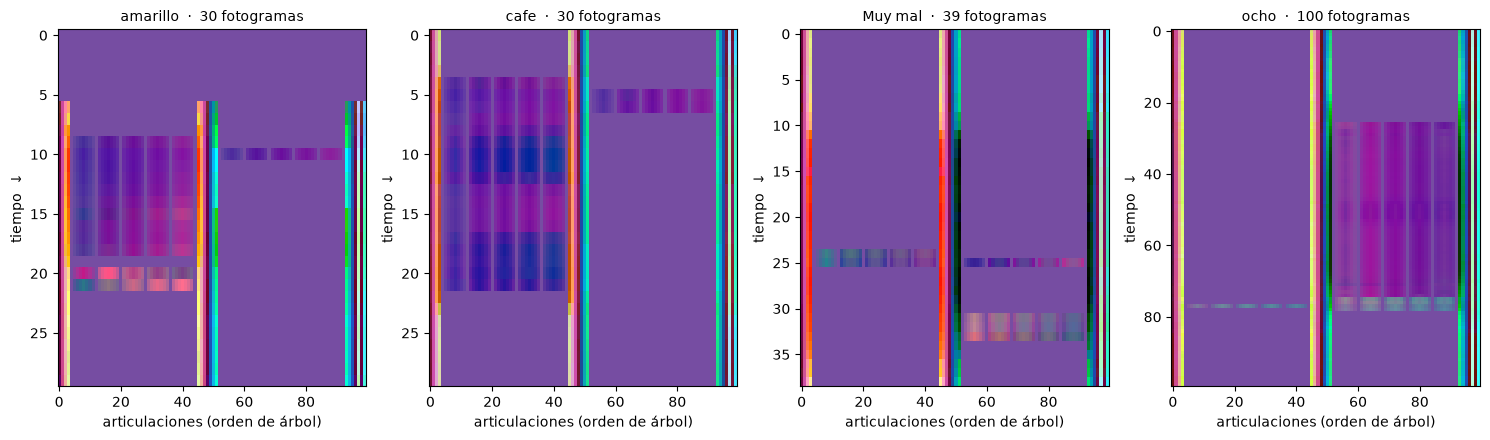

In [30]:
# Ver cómo se ven las imágenes TSSI de cuatro señas distintas.
ejemplos = [train_raw[0], train_raw[400], train_raw[1000], train_raw[1600]]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.5))
for ax, ejemplo in zip(axes, ejemplos):
    imagen = escalar_a_imagen(a_imagen_tssi(ejemplo["sign"]))
    ax.imshow(imagen.permute(1, 2, 0).numpy(), aspect="auto", interpolation="nearest")
    ax.set_title(f"{ejemplo['gloss']}  ·  {imagen.shape[1]} fotogramas", fontsize=10)
    ax.set_xlabel("articulaciones (orden de árbol)")
    ax.set_ylabel("tiempo  ↓")
plt.tight_layout()
plt.show()

## Paso 18 — Entrenar la DenseNet-121

A diferencia del Transformer, que se entrenó desde cero, aquí **sí hay
preentrenamiento**: la DenseNet-121 viene entrenada con ImageNet. Aunque esas
imágenes sean fotos de objetos, la red ya aprendió a detectar bordes, texturas y
patrones repetidos, y eso también aplica a una imagen TSSI. Es una de las
ventajas que el paper reivindica de convertir el problema a imágenes.

Detalles de implementación:

| Decisión | Valor | Por qué |
|---|---|---|
| Tamaño de entrada | 128×128 | Compromiso entre fidelidad y costo en CPU |
| Normalización | Media y desviación de ImageNet | Lo que esperan los pesos preentrenados |
| Capa de salida | 1024 → 54 | Se reemplaza la de ImageNet (1000 clases) |

Las imágenes TSSI pequeñas se construyen **una sola vez** y se guardan en memoria;
el redimensionado se hace por lote. Eso evita recalcular la normalización en cada
época.

In [32]:
import time
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.models import densenet121, DenseNet121_Weights

TAMANO = 128
MEDIA_IMAGENET = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
DESV_IMAGENET  = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)


def precomputar_tssi(datos):
    """Construye las imágenes TSSI pequeñas una sola vez (son livianas)."""
    imagenes = [escalar_a_imagen(a_imagen_tssi(e["sign"])) for e in datos]
    etiquetas = torch.tensor([A_INDICE[e["gloss"]] for e in datos])
    return imagenes, etiquetas


class DatosTSSI(Dataset):
    """Redimensiona y normaliza al vuelo, por lote."""

    def __init__(self, imagenes, etiquetas):
        self.imagenes, self.etiquetas = imagenes, etiquetas

    def __len__(self):
        return len(self.etiquetas)

    def __getitem__(self, i):
        img = self.imagenes[i].unsqueeze(0)
        img = F.interpolate(img, size=(TAMANO, TAMANO),
                            mode="bilinear", align_corners=False).squeeze(0)
        return (img - MEDIA_IMAGENET) / DESV_IMAGENET, self.etiquetas[i]


print("Construyendo imágenes TSSI...")
img_tr, y_tr = precomputar_tssi(train_raw)
img_dv, y_dv = precomputar_tssi(dev_raw)
img_te, y_te = precomputar_tssi(test_raw)

memoria = sum(i.numel() for i in img_tr + img_dv + img_te) * 4 / 1e6
print(f"  train {len(img_tr)} | dev {len(img_dv)} | test {len(img_te)}")
print(f"  memoria ocupada: {memoria:.0f} MB")

datos_tr = DatosTSSI(img_tr, y_tr)
datos_dv = DatosTSSI(img_dv, y_dv)
datos_te = DatosTSSI(img_te, y_te)
print(f"  forma que entra a la red: {tuple(datos_tr[0][0].shape)}")


def construir_densenet(n_clases):
    modelo = densenet121(weights=DenseNet121_Weights.IMAGENET1K_V1)
    modelo.classifier = nn.Linear(1024, n_clases)
    return modelo

Construyendo imágenes TSSI...
  train 1733 | dev 579 | test 568
  memoria ocupada: 180 MB
  forma que entra a la red: (3, 128, 128)


In [33]:
# Medir cuánto tarda UNA época antes de lanzar el entrenamiento completo.
torch.manual_seed(42)
modelo_prueba = construir_densenet(len(CLASES))
optim_prueba = torch.optim.Adam(modelo_prueba.parameters(), lr=1e-4)
criterio = nn.CrossEntropyLoss()
cargador_prueba = DataLoader(datos_tr, batch_size=16, shuffle=True)

inicio = time.perf_counter()
modelo_prueba.train()
for i, (xb, yb) in enumerate(cargador_prueba):
    optim_prueba.zero_grad()
    criterio(modelo_prueba(xb), yb).backward()
    optim_prueba.step()
    if i == 9:           # solo 10 lotes para medir
        break
transcurrido = time.perf_counter() - inicio

lotes_por_epoca = len(cargador_prueba)
segundos_epoca = transcurrido / 10 * lotes_por_epoca
print(f"10 lotes en {transcurrido:.1f} s")
print(f"Lotes por época: {lotes_por_epoca}")
print(f"Estimado por época: {segundos_epoca/60:.1f} min")
print(f"Estimado para 30 épocas: {segundos_epoca*30/3600:.1f} horas")

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to C:\Users\Delga/.cache\torch\hub\checkpoints\densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:01<00:00, 17.4MB/s]


10 lotes en 25.6 s
Lotes por época: 109
Estimado por época: 4.7 min
Estimado para 30 épocas: 2.3 horas


In [34]:
# def entrenar_densenet(epocas=30, lr=1e-4, semilla=42):
#     torch.manual_seed(semilla)
#     modelo = construir_densenet(len(CLASES))
#     optim = torch.optim.Adam(modelo.parameters(), lr=lr)
#     criterio = nn.CrossEntropyLoss()

#     cargador_tr = DataLoader(datos_tr, batch_size=16, shuffle=True)
#     cargador_dv = DataLoader(datos_dv, batch_size=32)
#     cargador_te = DataLoader(datos_te, batch_size=32)

#     def evaluar(cargador):
#         modelo.eval()
#         aciertos = total = 0
#         predichas = []
#         with torch.no_grad():
#             for xb, yb in cargador:
#                 p = modelo(xb).argmax(1)
#                 predichas.append(p)
#                 aciertos += (p == yb).sum().item()
#                 total += yb.numel()
#         return aciertos / total, torch.cat(predichas)

#     mejor_dev, mejores_pesos, epoca_mejor = 0.0, None, 0
#     for epoca in range(1, epocas + 1):
#         inicio = time.perf_counter()
#         modelo.train()
#         perdida_total = 0.0
#         for xb, yb in cargador_tr:
#             optim.zero_grad()
#             perdida = criterio(modelo(xb), yb)
#             perdida.backward()
#             optim.step()
#             perdida_total += perdida.item()

#         acc_dev, _ = evaluar(cargador_dv)
#         marca = ""
#         if acc_dev > mejor_dev:
#             mejor_dev, epoca_mejor = acc_dev, epoca
#             mejores_pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
#             marca = "  *"
#         print(f"época {epoca:2d}/{epocas}  "
#               f"pérdida {perdida_total/len(cargador_tr):.3f}  "
#               f"dev {acc_dev:.1%}  "
#               f"({(time.perf_counter()-inicio)/60:.1f} min){marca}")

#     modelo.load_state_dict(mejores_pesos)
#     acc_test, pred_test = evaluar(cargador_te)

#     destino = ROOT / "modelos" / "sl_tssi"
#     destino.mkdir(parents=True, exist_ok=True)
#     torch.save({"model_state": mejores_pesos, "clases": CLASES,
#                 "tamano": TAMANO, "orden_tssi": ORDEN_TSSI,
#                 "acc_dev": mejor_dev, "acc_test": acc_test},
#                destino / "best.pt")

#     print(f"\nMejor dev: {mejor_dev:.1%} (época {epoca_mejor})")
#     print(f"Test:      {acc_test:.1%}")
#     print(f"Guardado en: {destino / 'best.pt'}")
#     return modelo, pred_test, acc_test


# modelo_tssi, pred_tssi, acc_tssi = entrenar_densenet(epocas=30)







def entrenar_densenet(epocas=30, lr=1e-4, semilla=42):
    torch.manual_seed(semilla)
    modelo = construir_densenet(len(CLASES))
    optim = torch.optim.Adam(modelo.parameters(), lr=lr)
    criterio = nn.CrossEntropyLoss()

    cargador_tr = DataLoader(datos_tr, batch_size=16, shuffle=True)
    cargador_dv = DataLoader(datos_dv, batch_size=32)
    cargador_te = DataLoader(datos_te, batch_size=32)

    def evaluar(cargador):
        modelo.eval()
        aciertos = total = 0
        predichas = []
        with torch.no_grad():
            for xb, yb in cargador:
                p = modelo(xb).argmax(1)
                predichas.append(p)
                aciertos += (p == yb).sum().item()
                total += yb.numel()
        return aciertos / total, torch.cat(predichas)

    mejor_dev, mejores_pesos, epoca_mejor = 0.0, None, 0
    for epoca in range(1, epocas + 1):
        inicio = time.perf_counter()
        modelo.train()
        perdida_total = 0.0
        for xb, yb in cargador_tr:
            optim.zero_grad()
            perdida = criterio(modelo(xb), yb)
            perdida.backward()
            optim.step()
            perdida_total += perdida.item()

        acc_dev, _ = evaluar(cargador_dv)
        marca = ""
        if acc_dev > mejor_dev:
            mejor_dev, epoca_mejor = acc_dev, epoca
            mejores_pesos = {k: v.clone() for k, v in modelo.state_dict().items()}
            marca = "  *"
        print(f"época {epoca:2d}/{epocas}  "
              f"pérdida {perdida_total/len(cargador_tr):.3f}  "
              f"dev {acc_dev:.1%}  "
              f"({(time.perf_counter()-inicio)/60:.1f} min){marca}")

    modelo.load_state_dict(mejores_pesos)
    acc_test, pred_test = evaluar(cargador_te)

    destino = ROOT / "modelos" / "sl_tssi"
    destino.mkdir(parents=True, exist_ok=True)
    torch.save({"model_state": mejores_pesos, "clases": CLASES,
                "tamano": TAMANO, "orden_tssi": ORDEN_TSSI,
                "acc_dev": mejor_dev, "acc_test": acc_test},
               destino / "best.pt")

    print(f"\nMejor dev: {mejor_dev:.1%} (época {epoca_mejor})")
    print(f"Test:      {acc_test:.1%}")
    print(f"Guardado en: {destino / 'best.pt'}")
    return modelo, pred_test, acc_test


RUTA_TSSI = ROOT / "modelos" / "sl_tssi" / "best.pt"

if RUTA_TSSI.is_file():
    # Ya hay un modelo entrenado: se carga en lugar de reentrenar (~3 horas).
    import json

    guardado = torch.load(RUTA_TSSI, map_location="cpu")
    assert guardado["clases"] == CLASES, "Las clases del modelo guardado no coinciden"

    modelo_tssi = construir_densenet(len(CLASES))
    modelo_tssi.load_state_dict(guardado["model_state"])
    modelo_tssi.eval()

    # Mismas predicciones de test que devolvía entrenar_densenet.
    predichas = []
    with torch.no_grad():
        for xb, _ in DataLoader(datos_te, batch_size=32):
            predichas.append(modelo_tssi(xb).argmax(1))
    pred_tssi = torch.cat(predichas)
    acc_tssi = (pred_tssi == y_te).sum().item() / len(y_te)

    print(f"Modelo ya entrenado, no se reentrena: {RUTA_TSSI}\n")

    # Historial de épocas registrado durante el entrenamiento (curva.json).
    ruta_curva = RUTA_TSSI.parent / "curva.json"
    epoca_mejor = "?"
    if ruta_curva.is_file():
        curva = json.loads(ruta_curva.read_text(encoding="utf-8"))
        mejor = 0.0
        for epoca, perdida, dev in curva:
            marca = ""
            if dev > mejor:
                mejor, epoca_mejor, marca = dev, epoca, "  *"
            print(f"época {epoca:2d}/{len(curva)}  pérdida {perdida:.3f}  dev {dev:.1%}{marca}")

    print(f"\nMejor dev: {guardado['acc_dev']:.1%} (época {epoca_mejor})")
    print(f"Test:      {acc_tssi:.1%}")
    print(f"Cargado desde: {RUTA_TSSI}")
else:
    modelo_tssi, pred_tssi, acc_tssi = entrenar_densenet(epocas=30)


época  1/30  pérdida 2.898  dev 47.8%  (6.6 min)  *
época  2/30  pérdida 1.460  dev 68.2%  (6.8 min)  *
época  3/30  pérdida 0.745  dev 80.8%  (6.8 min)  *
época  4/30  pérdida 0.388  dev 86.7%  (6.6 min)  *
época  5/30  pérdida 0.208  dev 88.4%  (6.1 min)  *
época  6/30  pérdida 0.138  dev 87.6%  (5.7 min)
época  7/30  pérdida 0.105  dev 89.5%  (4.6 min)  *
época  8/30  pérdida 0.075  dev 89.5%  (4.5 min)
época  9/30  pérdida 0.037  dev 90.0%  (6.2 min)  *
época 10/30  pérdida 0.053  dev 84.6%  (6.3 min)
época 11/30  pérdida 0.071  dev 88.9%  (6.3 min)
época 12/30  pérdida 0.055  dev 90.5%  (7.3 min)  *
época 13/30  pérdida 0.038  dev 91.4%  (6.5 min)  *
época 14/30  pérdida 0.043  dev 91.0%  (6.6 min)
época 15/30  pérdida 0.017  dev 92.2%  (6.5 min)  *
época 16/30  pérdida 0.021  dev 90.7%  (6.6 min)
época 17/30  pérdida 0.013  dev 91.2%  (7.2 min)
época 18/30  pérdida 0.014  dev 91.0%  (6.9 min)
época 19/30  pérdida 0.077  dev 87.7%  (5.2 min)
época 20/30  pérdida 0.117  dev 88.1%  

In [38]:
# Curva de SL-TSSI, copiada de la salida del Paso 18.
CURVA_TSSI = [
    (1, 2.898, 0.478), (2, 1.460, 0.682), (3, 0.745, 0.808), (4, 0.388, 0.867),
    (5, 0.208, 0.884), (6, 0.138, 0.876), (7, 0.105, 0.895), (8, 0.075, 0.895),
    (9, 0.037, 0.900), (10, 0.053, 0.846), (11, 0.071, 0.889), (12, 0.055, 0.905),
    (13, 0.038, 0.914), (14, 0.043, 0.910), (15, 0.017, 0.922), (16, 0.021, 0.907),
    (17, 0.013, 0.912), (18, 0.014, 0.910), (19, 0.077, 0.877), (20, 0.117, 0.881),
    (21, 0.096, 0.862), (22, 0.050, 0.893), (23, 0.046, 0.921), (24, 0.049, 0.903),
    (25, 0.014, 0.919), (26, 0.011, 0.907), (27, 0.007, 0.924), (28, 0.005, 0.917),
    (29, 0.004, 0.917), (30, 0.020, 0.908),
]
import json
(ROOT / "modelos" / "sl_tssi" / "curva.json").write_text(json.dumps(CURVA_TSSI))
print("Curva guardada.")

Curva guardada.


## Paso 19 — Comparación de los tres modelos

Los tres modelos se entrenaron sobre el mismo conjunto de datos, con la misma
división por señante, y se evaluaron sobre el mismo conjunto de prueba, que
nunca participó en la selección de ningún modelo.

| Modelo | Entrada | Parámetros | Preentrenado |
|---|---|---|---|
| LSTM (réplica de Mora-Zarate et al.) | Secuencia de coordenadas | 682 K | No |
| Transformer (signjoey) | Secuencia de coordenadas | 22,3 M | No |
| SL-TSSI-DenseNet (Laines et al.) | Imagen TSSI | 8,0 M | Sí, ImageNet |

In [35]:
# Desglose de SL-TSSI por categoría y por seña.
pred_tssi_lista = pred_tssi.tolist()
reales_tssi = [A_INDICE[e["gloss"]] for e in test_raw]

cat_t = defaultdict(lambda: [0, 0])
glo_t = defaultdict(lambda: [0, 0])
confusiones_t = Counter()
for ejemplo, real, pred in zip(test_raw, reales_tssi, pred_tssi_lista):
    glosa = ejemplo["gloss"]
    c = "/".join(sorted(categorias_por_glosa[glosa]))
    acierto = int(real == pred)
    cat_t[c][0] += acierto; cat_t[c][1] += 1
    glo_t[glosa][0] += acierto; glo_t[glosa][1] += 1
    if not acierto:
        confusiones_t[(glosa, CLASES[pred])] += 1

print(f"{'CATEGORÍA':<24} {'LSTM':>8} {'Transf.':>9} {'SL-TSSI':>9}")
print("-" * 54)
for c in sorted(cat_t):
    lstm = cat_n[c] if False else None          # placeholder, ver nota abajo
    tr = cat_n[c][0] / cat_n[c][1]              # Transformer normalizado
    ts = cat_t[c][0] / cat_t[c][1]
    print(f"{c:<24} {'—':>8} {tr:>8.1%} {ts:>8.1%}")

print(f"\n{'NÚMERO':<12} {'Transf.':>9} {'SL-TSSI':>9} {'cambio':>9}")
print("-" * 42)
for g in numeros:
    tr = glo_n[g][0] / glo_n[g][1] if glo_n[g][1] else 0
    ts = glo_t[g][0] / glo_t[g][1] if glo_t[g][1] else 0
    print(f"{g:<12} {tr:>8.1%} {ts:>8.1%} {ts-tr:>+8.1%}")

print("\nSEÑAS QUE SL-TSSI AÚN FALLA (peores 10)")
for exactitud, glosa, ok, tot in sorted(
        (ok / tot, g, ok, tot) for g, (ok, tot) in glo_t.items())[:10]:
    print(f"  {glosa:<20} {exactitud:6.1%}  ({ok}/{tot})")

print("\nCONFUSIONES MÁS FRECUENTES DE SL-TSSI")
for (real, predicha), veces in confusiones_t.most_common(10):
    print(f"  {real:<20} -> {predicha:<20} {veces}x")

CATEGORÍA                    LSTM   Transf.   SL-TSSI
------------------------------------------------------
Colors                          —    90.0%    96.7%
Courtesy                        —    70.7%    79.1%
Courtesy/Numbers                —    34.4%    86.8%

NÚMERO         Transf.   SL-TSSI    cambio
------------------------------------------
cinco           20.0%   100.0%   +80.0%
cuatro          26.7%    93.3%   +66.7%
dies            50.0%    68.8%   +18.8%
dos             53.3%   100.0%   +46.7%
nueve           40.0%    80.0%   +40.0%
ocho            20.0%    80.0%   +60.0%
seis            26.7%   100.0%   +73.3%
siete            0.0%    80.0%   +80.0%
tres            46.7%    86.7%   +40.0%
uno             60.0%    80.0%   +20.0%

SEÑAS QUE SL-TSSI AÚN FALLA (peores 10)
  Gracias               33.3%  (2/6)
  Si                    33.3%  (2/6)
  Tranquilo             33.3%  (2/6)
  Baño                  50.0%  (3/6)
  Maso Menos            50.0%  (3/6)
  Necesitar           

## Paso 20 — Métricas y figuras

Las métricas que dependen solo de las predicciones se pueden recalcular en
cualquier momento a partir de los modelos guardados. Las curvas de entrenamiento,
en cambio, solo existen mientras se entrena: las de los Transformers están en
`validations.txt`, y la de SL-TSSI quedó registrada en `curva.json`.

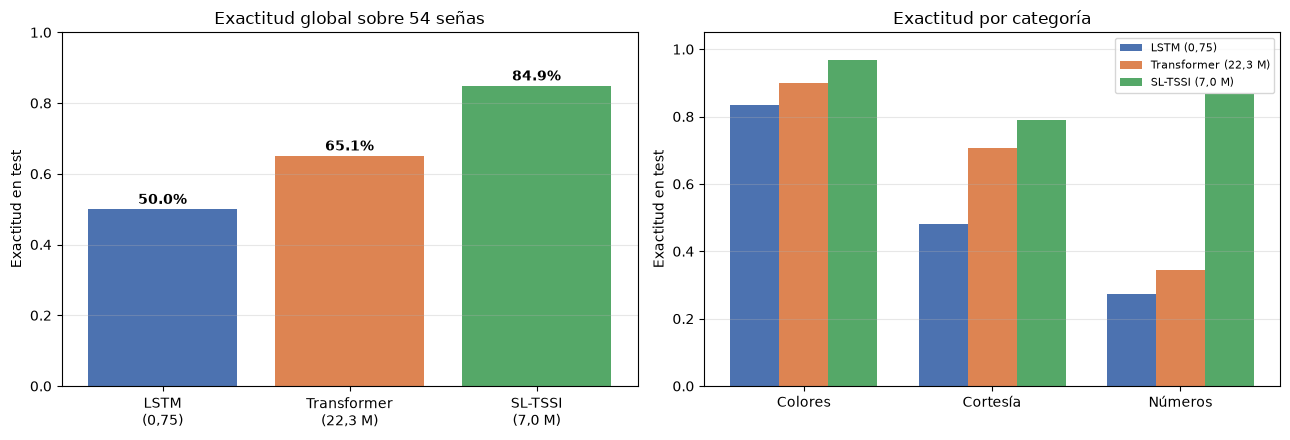

In [51]:
import matplotlib.pyplot as plt

AZUL, NARANJA, VERDE = "#4C72B0", "#DD8452", "#55A868"

# Resultados de las tres corridas (test).
RESULTADOS = {
    "LSTM\n(0,75)":          {"global": 0.500, "Colors": 0.833, "Courtesy": 0.481, "Números": 0.272},
    "Transformer\n(22,3 M)":  {"global": 0.651, "Colors": 0.900, "Courtesy": 0.707, "Números": 0.344},
    "SL-TSSI\n(7,0 M)":       {"global": 0.849, "Colors": 0.967, "Courtesy": 0.791, "Números": 0.868},
}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Exactitud global ---
nombres = list(RESULTADOS)
valores = [RESULTADOS[n]["global"] for n in nombres]
barras = ax1.bar(nombres, valores, color=[AZUL, NARANJA, VERDE])
for barra, v in zip(barras, valores):
    ax1.text(barra.get_x() + barra.get_width()/2, v + 0.015, f"{v:.1%}",
             ha="center", fontweight="bold")
ax1.set_ylim(0, 1.0)
ax1.set_ylabel("Exactitud en test")
ax1.set_title("Exactitud global sobre 54 señas")
ax1.grid(axis="y", alpha=0.3)

# --- Por categoría ---
categorias = ["Colors", "Courtesy", "Números"]
x = range(len(categorias))
ancho = 0.26
for i, (nombre, color) in enumerate(zip(nombres, [AZUL, NARANJA, VERDE])):
    pos = [p + (i - 1) * ancho for p in x]
    ax2.bar(pos, [RESULTADOS[nombre][c] for c in categorias],
            ancho, label=nombre.replace("\n", " "), color=color)
ax2.set_xticks(list(x)); ax2.set_xticklabels(["Colores", "Cortesía", "Números"])
ax2.set_ylim(0, 1.05)
ax2.set_ylabel("Exactitud en test")
ax2.set_title("Exactitud por categoría")
ax2.legend(fontsize=8); ax2.grid(axis="y", alpha=0.3)

plt.tight_layout(); plt.show()

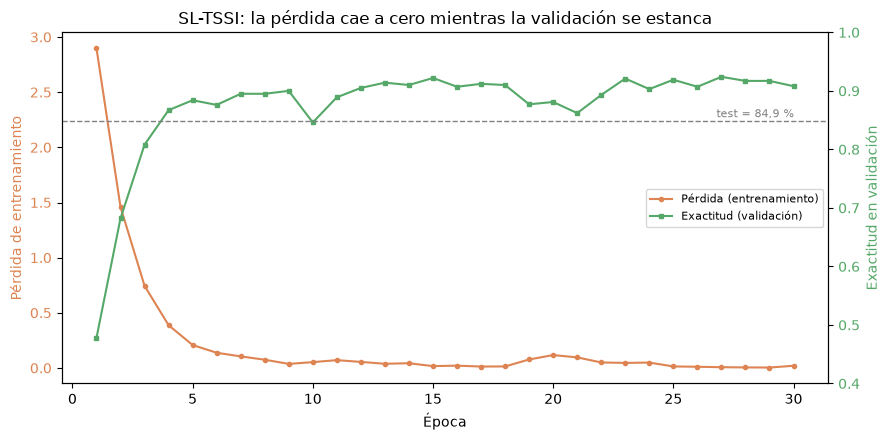

Interpretación: desde la época 9 la validación oscila en torno al 90 %
mientras la pérdida de entrenamiento sigue bajando hasta 0,004.
El modelo memoriza el entrenamiento sin ganar generalización.


In [40]:
# Evolución del entrenamiento de SL-TSSI: sobreajuste a la vista.
epocas  = [e for e, _, _ in CURVA_TSSI]
perdida = [p for _, p, _ in CURVA_TSSI]
dev     = [d for _, _, d in CURVA_TSSI]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(epocas, perdida, color=NARANJA, marker="o", ms=3, label="Pérdida (entrenamiento)")
ax.set_xlabel("Época"); ax.set_ylabel("Pérdida de entrenamiento", color=NARANJA)
ax.tick_params(axis="y", labelcolor=NARANJA)

ax2 = ax.twinx()
ax2.plot(epocas, dev, color=VERDE, marker="s", ms=3, label="Exactitud (validación)")
ax2.axhline(0.849, color="gray", ls="--", lw=1)
ax2.text(30, 0.855, "test = 84,9 %", ha="right", fontsize=8, color="gray")
ax2.set_ylabel("Exactitud en validación", color=VERDE)
ax2.tick_params(axis="y", labelcolor=VERDE)
ax2.set_ylim(0.4, 1.0)

ax.set_title("SL-TSSI: la pérdida cae a cero mientras la validación se estanca")
lineas = ax.get_lines() + ax2.get_lines()[:1]
ax.legend(lineas, [l.get_label() for l in lineas], loc="center right", fontsize=8)
plt.tight_layout(); plt.show()

print("Interpretación: desde la época 9 la validación oscila en torno al 90 %")
print("mientras la pérdida de entrenamiento sigue bajando hasta 0,004.")
print("El modelo memoriza el entrenamiento sin ganar generalización.")

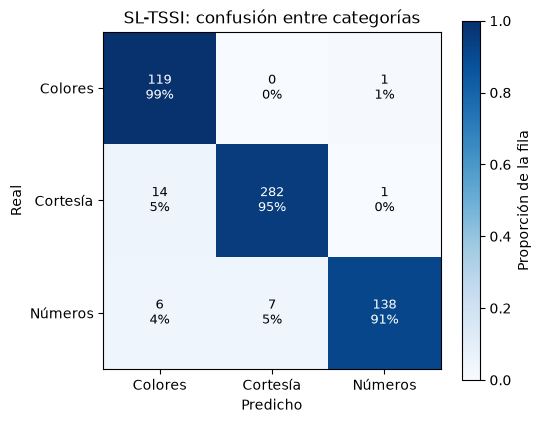

In [41]:
# Matriz de confusión de SL-TSSI, agrupada por categoría.
import numpy as np

grupo = {g: ("Números" if len(c) > 1 else
             "Colores" if "Colors" in c else "Cortesía")
         for g, c in categorias_por_glosa.items()}
GRUPOS = ["Colores", "Cortesía", "Números"]

matriz = np.zeros((3, 3), dtype=int)
for ejemplo, pred in zip(test_raw, pred_tssi_lista):
    i = GRUPOS.index(grupo[ejemplo["gloss"]])
    j = GRUPOS.index(grupo[CLASES[pred]])
    matriz[i, j] += 1

fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(matriz / matriz.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(3)); ax.set_xticklabels(GRUPOS)
ax.set_yticks(range(3)); ax.set_yticklabels(GRUPOS)
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title("SL-TSSI: confusión entre categorías")
for i in range(3):
    for j in range(3):
        pct = matriz[i, j] / matriz[i].sum()
        ax.text(j, i, f"{matriz[i,j]}\n{pct:.0%}", ha="center", va="center",
                color="white" if pct > 0.5 else "black", fontsize=9)
plt.colorbar(im, ax=ax, label="Proporción de la fila")
plt.tight_layout(); plt.show()

## Paso 21 — Métricas detalladas

La exactitud global promedia todas las clases por igual, y con un conjunto tan
desbalanceado (unos 100 videos por color frente a 26 por seña de cortesía) eso
favorece a las clases grandes. El **F1 macro** corrige ese sesgo: calcula el F1
de cada clase por separado y promedia, dándoles el mismo peso.

| Métrica | Qué mide |
|---|---|
| Precisión | De lo que el modelo predijo como X, cuánto era realmente X |
| Recall | De todos los X que había, cuántos encontró |
| F1 | Media armónica de las dos; penaliza si alguna es baja |
| F1 macro | Promedio del F1 de las 54 clases, sin ponderar por tamaño |

In [47]:
def metricas_por_clase(reales, predichas, clases=None):
    """Precisión, recall y F1 por clase, más el F1 macro."""
    clases = clases if clases is not None else sorted(set(reales) | set(predichas))
    tp, fp, fn = Counter(), Counter(), Counter()
    for r, p in zip(reales, predichas):
        if r == p:
            tp[r] += 1
        else:
            fp[p] += 1
            fn[r] += 1

    filas = {}
    for c in clases:
        prec = tp[c] / (tp[c] + fp[c]) if (tp[c] + fp[c]) else 0.0
        rec = tp[c] / (tp[c] + fn[c]) if (tp[c] + fn[c]) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        filas[c] = {"precision": prec, "recall": rec, "f1": f1,
                    "soporte": tp[c] + fn[c]}

    presentes = [c for c in clases if filas[c]["soporte"] > 0]
    return filas, sum(filas[c]["f1"] for c in presentes) / len(presentes)


# Predicciones de los tres modelos, todas como cadenas de texto.
reales_tssi_str = [e["gloss"] for e in test_raw]
pred_tssi_str = [CLASES[p] for p in pred_tssi_lista]

modelos = {
    "Transformer original":   (original["ref"], original["hyp"]),
    "Transformer normalizado": (normalizado["ref"], normalizado["hyp"]),
    "SL-TSSI-DenseNet":        (reales_tssi_str, pred_tssi_str),
}

# La LSTM del Paso 15, si sus predicciones siguen en memoria.
try:
    modelos["LSTM normalizada"] = (
        reales_tssi_str, [CLASES[p] for p in pred_norm.tolist()]
    )
except NameError:
    print("(La LSTM del Paso 15 no está en memoria; se omite.)\n")

print(f"{'MODELO':<26} {'exactitud':>10} {'F1 macro':>10} {'brecha':>9}")
print("-" * 58)
resumen_f1 = {}
for nombre, (ref, hyp) in modelos.items():
    exactitud = sum(r == h for r, h in zip(ref, hyp)) / len(ref)
    filas, f1_macro = metricas_por_clase(ref, hyp, CLASES)
    resumen_f1[nombre] = (filas, f1_macro)
    print(f"{nombre:<26} {exactitud:>9.1%} {f1_macro:>9.1%} {f1_macro-exactitud:>+8.1%}")

print("\nLa brecha negativa indica que el modelo acierta mejor en las clases")
print("con más datos que en las pequeñas.")

MODELO                      exactitud   F1 macro    brecha
----------------------------------------------------------
Transformer original           51.2%     51.4%    +0.2%
Transformer normalizado        65.1%     65.1%    -0.1%
SL-TSSI-DenseNet               84.9%     82.2%    -2.7%
LSTM normalizada               50.0%     50.8%    +0.8%

La brecha negativa indica que el modelo acierta mejor en las clases
con más datos que en las pequeñas.


In [46]:
# ---------- Métricas por clase ----------
def metricas_por_clase(reales, predichas, clases):
    """Precisión, recall y F1 de cada clase."""
    tp, fp, fn = Counter(), Counter(), Counter()
    for r, p in zip(reales, predichas):
        if r == p:
            tp[r] += 1
        else:
            fp[p] += 1
            fn[r] += 1

    filas = {}
    for c in clases:
        prec = tp[c] / (tp[c] + fp[c]) if (tp[c] + fp[c]) else 0.0
        rec = tp[c] / (tp[c] + fn[c]) if (tp[c] + fn[c]) else 0.0
        f1 = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
        filas[c] = {"precision": prec, "recall": rec, "f1": f1,
                    "soporte": tp[c] + fn[c]}
    return filas


# Cada seña pertenece a una de tres categorías.
grupo = {g: ("Números" if len(c) > 1 else
             "Colores" if "Colors" in c else "Cortesía")
         for g, c in categorias_por_glosa.items()}


def evaluar_modelo(reales, predichas):
    filas = metricas_por_clase(reales, predichas, CLASES)
    presentes = [c for c in CLASES if filas[c]["soporte"] > 0]

    por_categoria = defaultdict(lambda: [0, 0])
    for r, h in zip(reales, predichas):
        cat = grupo.get(r, "?")
        por_categoria[cat][0] += int(r == h)
        por_categoria[cat][1] += 1

    n = len(presentes)
    return {
        "exactitud":       sum(r == h for r, h in zip(reales, predichas)) / len(reales),
        "recall_macro":    sum(filas[c]["recall"] for c in presentes) / n,
        "precision_macro": sum(filas[c]["precision"] for c in presentes) / n,
        "f1_macro":        sum(filas[c]["f1"] for c in presentes) / n,
        "Colores":         por_categoria["Colores"][0] / por_categoria["Colores"][1],
        "Cortesía":        por_categoria["Cortesía"][0] / por_categoria["Cortesía"][1],
        "Números":         por_categoria["Números"][0] / por_categoria["Números"][1],
        "filas":           filas,
    }


# ---------- Predicciones de cada modelo ----------
reales_str = [e["gloss"] for e in test_raw]
pred_tssi_str = [CLASES[p] for p in pred_tssi_lista]

MODELOS = {}
try:
    MODELOS["LSTM normalizada"] = (reales_str, [CLASES[p] for p in pred_norm.tolist()])
except NameError:
    print("(La LSTM del Paso 15 no está en memoria; se omite de la tabla.)\n")
MODELOS["Transformer original"] = (original["ref"], original["hyp"])
MODELOS["Transformer normalizado"] = (normalizado["ref"], normalizado["hyp"])
MODELOS["SL-TSSI-DenseNet"] = (reales_str, pred_tssi_str)


# ---------- Parámetros de cada arquitectura ----------
def contar(constructor):
    try:
        return sum(p.numel() for p in constructor().parameters())
    except Exception:
        return None

PARAMETROS = {
    "LSTM normalizada":        contar(lambda: ClasificadorLSTM(len(CLASES))),
    "Transformer original":    22_287_424,
    "Transformer normalizado": 22_287_424,
    "SL-TSSI-DenseNet":        contar(lambda: construir_densenet(len(CLASES))),
}
PREENTRENADO = {
    "LSTM normalizada": "No",
    "Transformer original": "No",
    "Transformer normalizado": "No",
    "SL-TSSI-DenseNet": "Sí (ImageNet)",
}
ENTRADA = {
    "LSTM normalizada": "coordenadas",
    "Transformer original": "coordenadas",
    "Transformer normalizado": "coordenadas",
    "SL-TSSI-DenseNet": "imagen TSSI",
}


# ---------- Tabla ----------
resultados = {n: evaluar_modelo(ref, hyp) for n, (ref, hyp) in MODELOS.items()}

enc = (f"{'MODELO':<25} {'params':>9} {'pre':>14} "
       f"{'exact.':>8} {'rec.M':>7} {'prec.M':>7} {'F1 M':>7} "
       f"{'Col.':>7} {'Cort.':>7} {'Núm.':>7}")
print(enc)
print("-" * len(enc))
for nombre, r in resultados.items():
    p = PARAMETROS.get(nombre)
    p_txt = f"{p/1e6:.2f} M" if p else "—"
    print(f"{nombre:<25} {p_txt:>9} {PREENTRENADO[nombre]:>14} "
          f"{r['exactitud']:>7.1%} {r['recall_macro']:>6.1%} "
          f"{r['precision_macro']:>6.1%} {r['f1_macro']:>6.1%} "
          f"{r['Colores']:>6.1%} {r['Cortesía']:>6.1%} {r['Números']:>6.1%}")

print("\nexact. = exactitud global   ·   rec.M / prec.M / F1 M = promedios macro")
print("Los promedios macro dan el mismo peso a las 54 señas; la exactitud")
print("global favorece a las clases con más ejemplos de prueba.")

MODELO                       params            pre   exact.   rec.M  prec.M    F1 M    Col.   Cort.    Núm.
-----------------------------------------------------------------------------------------------------------
LSTM normalizada             0.75 M             No   50.0%  53.2%  54.9%  50.8%  83.3%  48.1%  27.2%
Transformer original        22.29 M             No   51.2%  53.2%  56.5%  51.4%  87.5%  56.6%  11.9%
Transformer normalizado     22.29 M             No   65.1%  66.2%  69.5%  65.1%  90.0%  70.7%  34.4%
SL-TSSI-DenseNet             7.01 M  Sí (ImageNet)   84.9%  82.8%  84.8%  82.2%  96.7%  79.1%  86.8%

exact. = exactitud global   ·   rec.M / prec.M / F1 M = promedios macro
Los promedios macro dan el mismo peso a las 54 señas; la exactitud
global favorece a las clases con más ejemplos de prueba.


In [43]:
filas_tssi, f1_macro_tssi = resumen_f1["SL-TSSI-DenseNet"]
videos_train = Counter(e["gloss"] for e in train_raw)

grupo = {g: ("Números" if len(c) > 1 else
             "Colores" if "Colors" in c else "Cortesía")
         for g, c in categorias_por_glosa.items()}

print(f"SL-TSSI-DenseNet — F1 macro: {f1_macro_tssi:.1%}\n")
print(f"{'seña':<18} {'cat.':<9} {'train':>6} {'prec':>7} {'recall':>7} {'F1':>7}")
print("-" * 60)
for glosa in sorted(CLASES, key=lambda g: filas_tssi[g]["f1"]):
    f = filas_tssi[glosa]
    if f["soporte"] == 0:
        continue
    print(f"{glosa:<18} {grupo[glosa]:<9} {videos_train[glosa]:>6} "
          f"{f['precision']:>6.1%} {f['recall']:>6.1%} {f['f1']:>6.1%}")

print("\nPROMEDIO DE F1 POR CATEGORÍA")
for cat in ["Colores", "Cortesía", "Números"]:
    valores = [filas_tssi[g]["f1"] for g in CLASES
               if grupo.get(g) == cat and filas_tssi[g]["soporte"] > 0]
    print(f"  {cat:<10} {sum(valores)/len(valores):6.1%}  ({len(valores)} señas)")

SL-TSSI-DenseNet — F1 macro: 82.2%

seña               cat.       train    prec  recall      F1
------------------------------------------------------------
Si                 Cortesía      14  33.3%  33.3%  33.3%
Necesitar          Cortesía      14  37.5%  50.0%  42.9%
Gracias            Cortesía      14 100.0%  33.3%  50.0%
Tranquilo          Cortesía      14 100.0%  33.3%  50.0%
No                 Cortesía      16  50.0%  66.7%  57.1%
Excelente          Cortesía      15  57.1%  66.7%  61.5%
Invitar            Cortesía      15  50.0%  83.3%  62.5%
Baño               Cortesía      14 100.0%  50.0%  66.7%
Con gusto          Cortesía      16  66.7%  66.7%  66.7%
Maso Menos         Cortesía      16 100.0%  50.0%  66.7%
Lo siento          Cortesía      16  55.6%  83.3%  66.7%
Bienvenido         Cortesía      16  80.0%  66.7%  72.7%
Muchas Gracias     Cortesía      16  80.0%  66.7%  72.7%
Hola               Cortesía      26  83.3%  66.7%  74.1%
Mal                Cortesía      24  78.6%  7

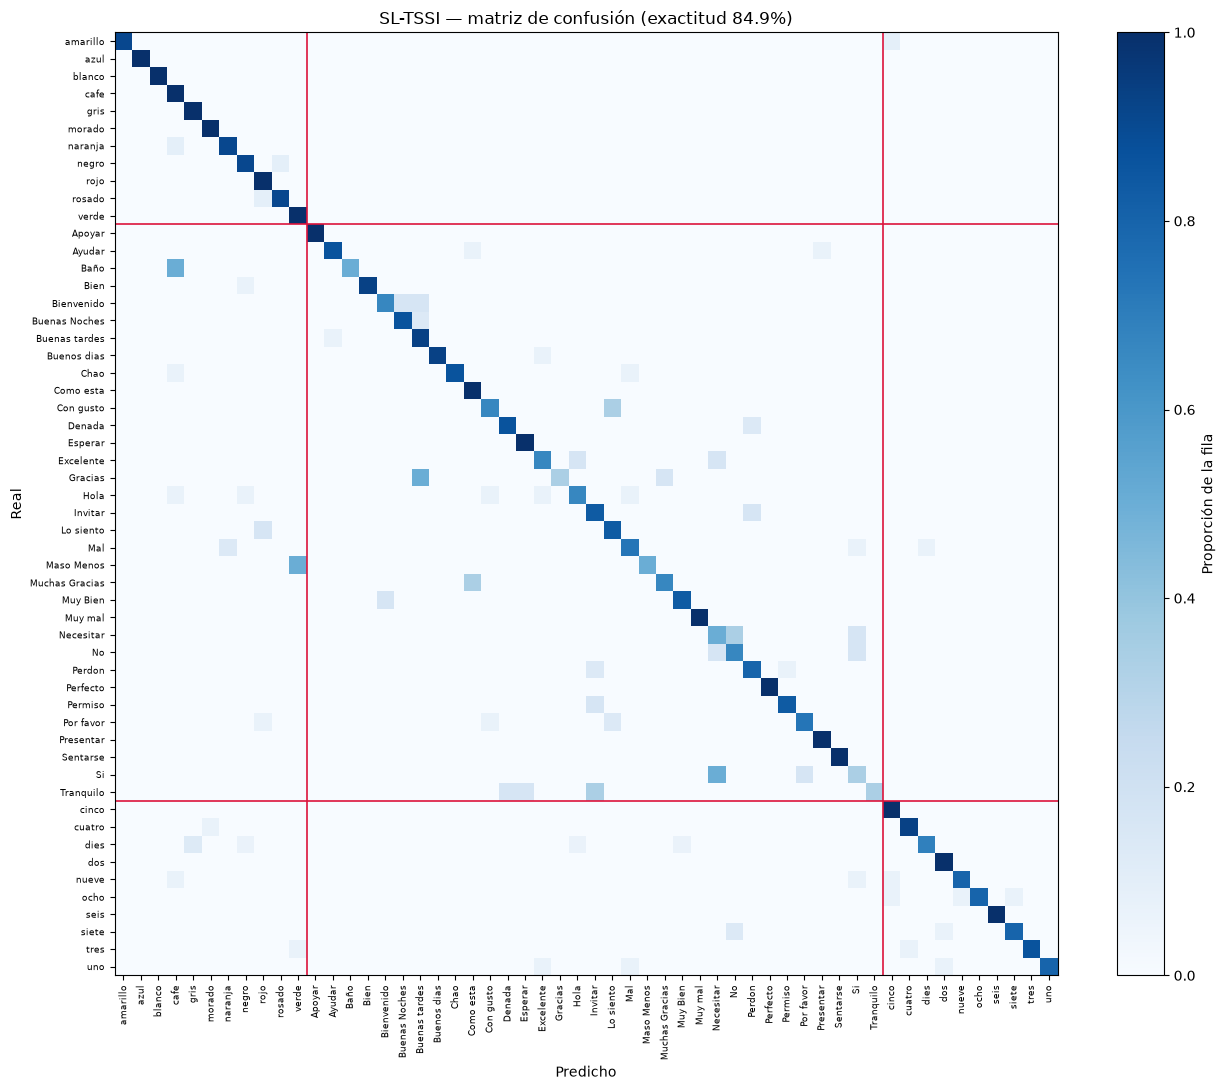

Los bloques rojos separan colores, cortesía y números.
Una diagonal fuerte significa buen desempeño; las manchas fuera
de la diagonal son las confusiones sistemáticas.


In [44]:
import numpy as np

# Las clases se ordenan por categoría para que las confusiones formen bloques.
ORDEN_CAT = ["Colores", "Cortesía", "Números"]
clases_ord = sorted(CLASES, key=lambda g: (ORDEN_CAT.index(grupo[g]), g))
pos = {g: i for i, g in enumerate(clases_ord)}

M = np.zeros((len(clases_ord), len(clases_ord)))
for real, pred in zip(reales_tssi_str, pred_tssi_str):
    M[pos[real], pos[pred]] += 1
M_norm = M / np.maximum(M.sum(axis=1, keepdims=True), 1)

fig, ax = plt.subplots(figsize=(13, 11))
im = ax.imshow(M_norm, cmap="Blues", vmin=0, vmax=1)

ax.set_xticks(range(len(clases_ord)))
ax.set_yticks(range(len(clases_ord)))
ax.set_xticklabels(clases_ord, rotation=90, fontsize=6.5)
ax.set_yticklabels(clases_ord, fontsize=6.5)
ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
ax.set_title(f"SL-TSSI — matriz de confusión (exactitud {sum(M.diagonal())/M.sum():.1%})")

# Líneas que separan las tres categorías.
limites, acumulado = [], 0
for cat in ORDEN_CAT[:-1]:
    acumulado += sum(1 for g in clases_ord if grupo[g] == cat)
    limites.append(acumulado - 0.5)
for lim in limites:
    ax.axhline(lim, color="crimson", lw=1.2)
    ax.axvline(lim, color="crimson", lw=1.2)

plt.colorbar(im, ax=ax, fraction=0.046, label="Proporción de la fila")
plt.tight_layout(); plt.show()

print("Los bloques rojos separan colores, cortesía y números.")
print("Una diagonal fuerte significa buen desempeño; las manchas fuera")
print("de la diagonal son las confusiones sistemáticas.")

---
# Conclusiones

## Qué se hizo

Se construyó un sistema que reconoce **54 señas aisladas de Lengua de Señas
Colombiana** (colores, números y expresiones de cortesía) a partir de video.
Cada video se convierte con MediaPipe en una secuencia de coordenadas del cuerpo
y las manos (225 números por fotograma), y un modelo aprende a asignarle la seña
correcta.

Se usaron **2.880 videos de 34 personas**, divididos 60/20/20 **por persona**
(1.733 / 579 / 568 videos). Así, el modelo se evalúa siempre con personas que
nunca vio durante el entrenamiento, que es la situación real de uso.

## Resultados (conjunto de prueba)

| Modelo | Parámetros | Preentrenado | Exactitud | F1 macro |
|---|---|---|---|---|
| LSTM (coordenadas normalizadas) | 0,75 M | No | 50,0 % | 50,8 % |
| Transformer signjoey (original) | 22,3 M | No | 51,2 % | 51,4 % |
| Transformer signjoey (normalizado) | 22,3 M | No | 65,1 % | 65,1 % |
| **SL-TSSI-DenseNet** | **7,0 M** | Sí (ImageNet) | **84,9 %** | **82,2 %** |

## Hallazgos principales

1. **Normalizar las coordenadas fue la mejora más importante.** Centrar el
   cuerpo en los hombros y cada mano en su muñeca hace que el modelo vea la
   *forma* de la mano y no dónde está la persona en la imagen. Con el mismo
   modelo y los mismos datos, la LSTM pasó de 25,4 % a 50,0 % y el Transformer
   de 51,2 % a 65,1 %.

2. **El problema es de clasificación, no de traducción.** signjoey fue diseñado
   para traducir oraciones continuas. Aquí cada video es una sola seña y el
   texto de referencia es la misma glosa en minúsculas, así que su parte de
   traducción (el *decoder*) no aporta información nueva.

3. **SL-TSSI-DenseNet es el mejor modelo, con amplia diferencia.** Convertir la
   secuencia en una imagen (tiempo × articulaciones, ordenadas con un recorrido
   en profundidad del esqueleto) permite usar una red convolucional
   preentrenada. Supera al Transformer por casi 20 puntos con unas 3 veces menos
   parámetros. Su F1 macro (82,2 %) es cercano a su exactitud, lo que indica que
   no gana solo por acertar las señas con más videos.

4. **Los números dejaron de ser el punto débil.** Pasaron de 11,9 % (Transformer
   original) a 86,8 % con SL-TSSI, lo que confirma que la información clave
   estaba en la configuración de los dedos.

5. **Los errores que quedan se concentran en cortesía** (F1 77,2 %), la
   categoría con menos ejemplos por seña (14–30 videos de entrenamiento frente a
   75 por color). El modelo tiende a responder un color cuando duda, como en
   *Baño → café* o *Maso Menos → verde*.


## Limitaciones

- **Cada modelo se entrenó una sola vez** (una semilla). Las conclusiones
  generales son sólidas, pero las cifras exactas pueden variar algunos puntos.
- **El conjunto de prueba es pequeño:** 568 videos de 7 personas, con un margen
  aproximado de ±3–4 puntos. Los resultados por seña se basan en muy pocos
  videos (muchas tienen solo 6) y deben leerse como tendencias.
- **La validación es optimista:** el mejor modelo se elige mirando dev, por eso
  dev siempre supera a test (92,4 % frente a 84,9 % en SL-TSSI). Los resultados
  que se reportan son los de test.
- **La comparación no es del todo pareja:** SL-TSSI parte de pesos preentrenados
  en ImageNet y los demás modelos se entrenaron desde cero.
- **Sobre los datos:** los números del señalante 34 están duplicados en dos
  carpetas (afecta solo a dev, no a test), y la división supone que el número de
  cada señalante identifica a la misma persona en todas las categorías.
  MediaPipe no siempre detecta las manos; esos fotogramas se rellenan con ceros.
- **No hay traducción real:** el texto de referencia es la glosa en minúsculas,
  así que las métricas de traducción (BLEU, CHRF, ROUGE) no miden calidad
  lingüística.

## Trabajo futuro

- **Compensar el desbalance** con pesos por clase o muestreo balanceado, para
  mejorar las señas de cortesía y reducir la tendencia a predecir colores.
- **Repetir los entrenamientos con varias semillas** y reportar promedio y
  desviación.
- **Usar parada temprana y reducción del learning rate:** SL-TSSI dejó de mejorar
  hacia la época 9–15, y en el Transformer el learning rate nunca bajó.
- **Mejorar las características de entrada:** rellenar los fotogramas sin mano
  con el último valor conocido y aplicar aumento de datos (rotaciones, escalas,
  cambios de velocidad).
- **Extender a frases** con traducciones reales al español. En ese escenario la
  arquitectura de traducción de signjoey sí tendría sentido.


---
# Parte 5 — SL-TSSI-DenseNet con aumento de datos

El modelo SL-TSSI v2 (`modelos/sl_tssi_v2`) llega a **100 % en entrenamiento**, pero se
queda en **92,2 % en validación** y **84,7 % en prueba**: memoriza los 1.733 videos de
entrenamiento. El aumento de datos ataca justo eso. En cada época el modelo recibe una
versión ligeramente distinta de cada video (girada, estirada, con otro ritmo, con ruido o
sin una mano en algunos fotogramas), así que ya no hay un conjunto fijo que memorizar.

**Esta parte es autónoma.** No hace falta ejecutar las celdas anteriores: basta con
ejecutar estas en orden. El código está en `tssi_aumento.py`; los datos se leen de
`dataset_completo/` y los resultados de los demás modelos, de `modelos/`.

| Qué | Dónde |
|---|---|
| Código (aumento, pipeline TSSI, entrenamiento, métricas) | `tssi_aumento.py` |
| Modelo con aumento | `modelos/sl_tssi_aug/best.pt` |
| Historial por época | `modelos/sl_tssi_aug/historial.json` |
| Predicciones de prueba | `modelos/sl_tssi_aug/predicciones_test.json` |
| Métricas de prueba | `modelos/sl_tssi_aug/resumen.json` |

**No se repite nada que ya esté guardado.** Si `best.pt` existe, el modelo se carga y no
se reentrena. Si el entrenamiento se interrumpe, al ejecutar de nuevo la celda continúa
desde la última época terminada (queda guardada en `ultimo.pt`). Nada de lo anterior
(datos, modelos, celdas) se modifica.

In [1]:
import sys, importlib
from collections import Counter
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "tssi_aumento.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import tssi_aumento as ta
importlib.reload(ta)        # por si el módulo cambió con el kernel abierto

AZUL, NARANJA, VERDE, ROJO = "#4C72B0", "#DD8452", "#55A868", "#C44E52"

DA = ta.cargar_datos()
print(f"train {len(DA.train)} | dev {len(DA.dev)} | test {len(DA.test)} | {len(DA.clases)} señas")
print(f"Hilos de CPU para PyTorch: {torch.get_num_threads()}\n")

for ruta in (ta.DIR_V2 / "best.pt", ta.DIR_V2 / "historial.json",
             ta.DIR_V2 / "predicciones_test.json", ta.DIR_AUG / "best.pt"):
    marca = "OK    " if ruta.is_file() else "FALTA "
    print(f"{marca} {ruta.relative_to(ROOT).as_posix()}")
if (ta.DIR_AUG / "ultimo.pt").is_file():
    print("\nHay un entrenamiento interrumpido: el Paso 24 lo continuará.")
elif not (ta.DIR_AUG / "best.pt").is_file():
    print("\nEl modelo con aumento todavía no existe: el Paso 24 lo entrenará.")

train 1733 | dev 579 | test 568 | 54 señas
Hilos de CPU para PyTorch: 4

OK     modelos/sl_tssi_v2/best.pt
OK     modelos/sl_tssi_v2/historial.json
OK     modelos/sl_tssi_v2/predicciones_test.json
FALTA  modelos/sl_tssi_aug/best.pt

El modelo con aumento todavía no existe: el Paso 24 lo entrenará.


## Paso 22 — Comprobar que el pipeline es el mismo del v2

Para que esta parte no dependa de las celdas anteriores, `tssi_aumento.py` trae su propia
copia de la normalización, del orden TSSI y del escalado. Una copia puede quedar distinta
del original sin que se note, así que lo comprobamos: cargamos el modelo v2 guardado,
predecimos el conjunto de prueba **con el código del módulo** y comparamos con las
predicciones que el v2 guardó al entrenarse. Si coinciden todas, cualquier diferencia
posterior entre el v2 y el modelo nuevo se debe solo al aumento.

In [2]:
coincidencia = ta.verificar_fidelidad_v2(DA)
assert coincidencia >= 0.99, "El pipeline del módulo no reproduce el del v2"
print("\nEl pipeline del módulo es el mismo que el del v2.")

Percentiles de escalado: diferencia máxima con los del v2 = 0.00e+00
Exactitud del v2 recalculada con este módulo: 84.7%
Predicciones que coinciden con las guardadas del v2: 100.0%

El pipeline del módulo es el mismo que el del v2.


## Paso 23 — Qué se aumenta, y qué no

Las transformaciones se aplican a la **matriz cruda de MediaPipe** `(fotogramas, 225)`,
antes de normalizar y de construir la imagen TSSI. No se tocan los videos: volver a pasar
MediaPipe por cada variante costaría horas y el modelo nunca ve píxeles.

Al revisar el pipeline aparecen dos cosas que deciden qué transformaciones sirven:

1. **La normalización anula la traslación y la escala.** Centra el cuerpo en los hombros
   y lo divide por su ancho, y hace lo mismo con cada mano respecto a su muñeca. Mover a la
   persona o acercarla a la cámara no cambia nada después de normalizar. La rotación y un
   estiramiento distinto en x y en y sí sobreviven.
2. **El redimensionado a 128×128 anula el cambio de velocidad uniforme.** Todas las
   imágenes terminan con 128 filas de tiempo, así que un video acelerado de forma pareja
   queda casi igual. Solo tienen efecto los cambios *desiguales*: recortar el inicio o el
   final, o que una parte de la seña vaya más rápida que la otra.

| Transformación | Qué simula | Valores | Probabilidad |
|---|---|---|---|
| Recorte temporal | Grabación que empieza o termina antes | hasta 10 % de los fotogramas | 0,5 |
| Deformación temporal | Una parte de la seña más rápida que la otra | factor 0,8 a 1,2 | 0,5 |
| Rotación | Cámara o persona algo inclinada | ±12° | 0,5 |
| Estiramiento | Otra proporción de cuerpo o de cámara | x e y entre 0,9 y 1,1, por separado | 0,5 |
| Ruido | Temblor de MediaPipe | σ = 0,002 en x, y | 0,5 |
| Quitar una mano | MediaPipe pierde la mano unos fotogramas | bloque del 10 % del video | 0,3 |

Se respetan tres reglas: un punto no detectado (cero) **sigue en cero**, solo se aumenta
**train** (dev y test quedan intactos), y el azar usa una semilla fija.

No se usa el espejo horizontal: cambia la mano dominante, y en lengua de señas eso puede
cambiar la seña.

La celda siguiente mide estas afirmaciones en lugar de suponerlas.

In [3]:
def cambio_relativo(a, b):
    return ((a - b).abs().mean() / b.abs().mean()).item()


# 1) ¿Qué transformaciones sobreviven a la normalización?
espaciales = {
    "Trasladar (5 % en x, 3 % en y)": lambda s: ta.trasladar(s, 0.05, -0.03),
    "Escalar ×1,1 (cámara más cerca)": lambda s: ta.escalar(s, 1.1),
    "Rotar 10°": lambda s: ta.rotar(s, 10),
    "Estirar x×1,1 · y×0,9": lambda s: ta.estirar(s, 1.1, 0.9),
}
print("CAMBIO EN LAS COORDENADAS NORMALIZADAS (200 videos de train)")
for nombre, f in espaciales.items():
    v = [cambio_relativo(ta.normalizar(f(e["sign"].float())), ta.normalizar(e["sign"].float()))
         for e in DA.train[:200]]
    print(f"  {nombre:<34} {np.mean(v):8.2%}")

# 2) ¿Qué cambios de tiempo sobreviven al redimensionado a 128x128?
bajo, alto = ta.calcular_percentiles(DA.train)
entrada = lambda s: ta.a_entrada_red(ta.escalar_a_imagen(ta.a_imagen_tssi(s), bajo, alto))
uniforme = lambda s, f: ta._interpolar(s, torch.linspace(0, s.shape[0] - 1, round(s.shape[0] * f)))
temporales = {
    "Velocidad uniforme ×1,2": lambda s: uniforme(s, 1.2),
    "Velocidad uniforme ×0,8": lambda s: uniforme(s, 0.8),
    "Deformación no uniforme (1,2)": lambda s: ta.deformar_tiempo(s, 1.2, 0.5),
    "Recorte del 10 %": lambda s: ta.recortar_tiempo(s, s.shape[0] // 20,
                                                     s.shape[0] // 10 - s.shape[0] // 20),
}
print("\nCAMBIO EN LA IMAGEN QUE ENTRA A LA RED (200 videos de train)")
for nombre, f in temporales.items():
    v = [cambio_relativo(entrada(f(e["sign"].float())), entrada(e["sign"].float()))
         for e in DA.train[:200]]
    print(f"  {nombre:<34} {np.mean(v):8.2%}")

# 3) Reglas de seguridad.
g = torch.Generator().manual_seed(0)
for e in DA.train[:300]:
    s = e["sign"].float()
    ausentes = s.reshape(-1, 75, 3).abs().sum(-1) == 0
    for f in (lambda x: ta.rotar(x, 10), lambda x: ta.estirar(x, 1.1, 0.9),
              lambda x: ta.ruido(x, 0.002, g)):
        assert torch.equal(f(s).reshape(-1, 75, 3).abs().sum(-1) == 0, ausentes)
    assert torch.equal(ta.aumentar(s, g, ta.SIN_AUMENTO), s)
    for _ in range(5):
        a = ta.aumentar(s, g)
        assert a.shape[1] == 225 and 8 <= a.shape[0] <= s.shape[0] and torch.isfinite(a).all()
print("\nComprobado en 300 videos: los puntos ausentes siguen en cero, sin aumento la")
print("salida es idéntica a la entrada y todas las salidas tienen la forma correcta.")

CAMBIO EN LAS COORDENADAS NORMALIZADAS (200 videos de train)
  Trasladar (5 % en x, 3 % en y)        0.00%
  Escalar ×1,1 (cámara más cerca)       0.00%
  Rotar 10°                            11.61%
  Estirar x×1,1 · y×0,9                12.69%

CAMBIO EN LA IMAGEN QUE ENTRA A LA RED (200 videos de train)
  Velocidad uniforme ×1,2               2.10%
  Velocidad uniforme ×0,8               3.08%
  Deformación no uniforme (1,2)         6.47%
  Recorte del 10 %                      7.70%

Comprobado en 300 videos: los puntos ausentes siguen en cero, sin aumento la
salida es idéntica a la entrada y todas las salidas tienen la forma correcta.


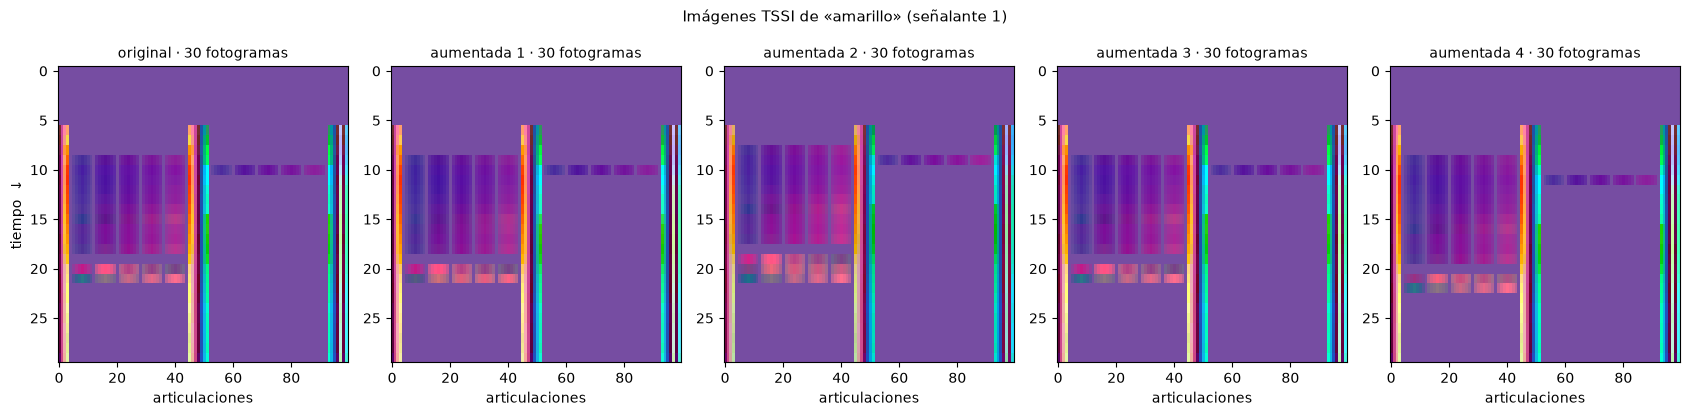

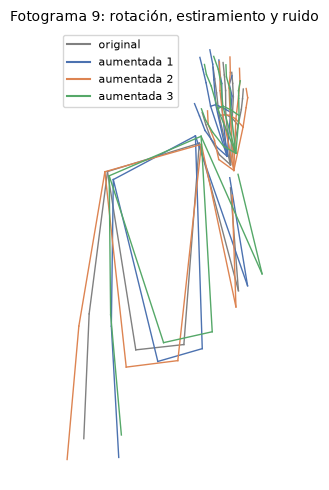

In [4]:
# Cómo se ve el aumento: la misma seña, original y cuatro versiones aumentadas.
ejemplo = next(e for e in DA.train if e["gloss"] == "amarillo")
g = torch.Generator().manual_seed(7)
versiones = [("original", ejemplo["sign"].float())] + [
    (f"aumentada {i}", ta.aumentar(ejemplo["sign"], g)) for i in range(1, 5)]

fig, axes = plt.subplots(1, 5, figsize=(17, 4.2))
for ax, (titulo, s) in zip(axes, versiones):
    imagen = ta.escalar_a_imagen(ta.a_imagen_tssi(s), bajo, alto)
    ax.imshow(imagen.permute(1, 2, 0).numpy(), aspect="auto", interpolation="nearest")
    ax.set_title(f"{titulo} · {s.shape[0]} fotogramas", fontsize=10)
    ax.set_xlabel("articulaciones")
axes[0].set_ylabel("tiempo  ↓")
fig.suptitle(f"Imágenes TSSI de «{ejemplo['gloss']}» (señalante {ejemplo['signer']})", fontsize=11)
plt.tight_layout()
plt.show()

# El esqueleto de un fotograma, con las transformaciones espaciales.
CONEX_MANO = [(0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8), (0, 9),
              (9, 10), (10, 11), (11, 12), (0, 13), (13, 14), (14, 15), (15, 16), (0, 17),
              (17, 18), (18, 19), (19, 20), (5, 9), (9, 13), (13, 17)]
CONEX_POSE = [(11, 12), (11, 13), (13, 15), (12, 14), (14, 16), (11, 23), (12, 24), (23, 24)]
espacial = dict(ta.SIN_AUMENTO, p_rotar=1.0, p_estirar=1.0, p_ruido=1.0)
s = ejemplo["sign"].float()
t = max(range(s.shape[0]), key=lambda i: (s[i, 99:].abs().sum() > 0).int().item())


def dibujar(ax, fila, color, etiqueta):
    partes = ((fila[0:99].reshape(33, 3), CONEX_POSE), (fila[99:162].reshape(21, 3), CONEX_MANO),
              (fila[162:225].reshape(21, 3), CONEX_MANO))
    for puntos, conexiones in partes:
        if not puntos.abs().sum():
            continue
        for a, b in conexiones:
            ax.plot([puntos[a, 0], puntos[b, 0]], [puntos[a, 1], puntos[b, 1]], color=color, lw=1)
    ax.plot([], [], color=color, label=etiqueta)


fig, ax = plt.subplots(figsize=(5, 5))
dibujar(ax, s[t], "gray", "original")
for i, color in enumerate((AZUL, NARANJA, VERDE)):
    dibujar(ax, ta.aumentar(s, g, espacial)[t], color, f"aumentada {i + 1}")
ax.invert_yaxis(); ax.set_aspect("equal"); ax.axis("off"); ax.legend(fontsize=8)
ax.set_title(f"Fotograma {t}: rotación, estiramiento y ruido", fontsize=10)
plt.tight_layout()
plt.show()

## Paso 24 — Entrenar la DenseNet con aumento

Todo es igual al v2 salvo el aumento y el número máximo de épocas, así que la diferencia
entre los dos modelos se puede atribuir al aumento.

| | v2 | Con aumento |
|---|---|---|
| Red | DenseNet-121 preentrenada en ImageNet | igual |
| Entrada | TSSI normalizada, 128×128 | igual |
| Optimizador | Adam, LR 1e-4 | igual |
| Lote | 16 | igual |
| LR adaptativo | `ReduceLROnPlateau`, LR ÷ 2 tras 2 épocas sin mejorar | igual |
| Parada temprana | 6 épocas sin mejorar en dev | igual |
| Semilla | 42 | igual |
| Épocas máximas | 25 | **40**: con aumento el modelo tarda más en converger, y la parada temprana decide cuándo parar |
| Datos de train | los mismos en cada época | **una versión aumentada distinta en cada época** |

**Una métrica nueva.** Con aumento, la exactitud que se mide durante el entrenamiento es
sobre datos aumentados, que son más difíciles que los originales. Para medir de verdad
cuánto memoriza el modelo, al final de cada época se evalúa también un subconjunto fijo de
**300 videos de train sin aumento** (`acc_train_limpio`).

**Duración.** Cada época toma unos 7 minutos en CPU, así que el entrenamiento completo puede
tardar entre 3 y 5 horas, según cuándo se active la parada temprana. Si se interrumpe (se
apaga el equipo o se reinicia el kernel), basta con ejecutar de nuevo la celda de
preparación y esta: el entrenamiento continúa desde la última época terminada.

In [5]:
modelo_aug, historial_aug = ta.entrenar_o_cargar(
    DA.train, DA.dev, DA.clases, ta.DIR_AUG,
    epocas=40, lr=1e-4, paciencia=6, semilla=42, aumento=ta.AUMENTO)

pred_aug, resumen_aug = ta.predicciones_test(modelo_aug, DA, ta.DIR_AUG)
N_PARAMS_TSSI = sum(p.numel() for p in modelo_aug.parameters())

print(f"\nExactitud en prueba: {resumen_aug['exactitud']:.1%} ± {resumen_aug['margen_95']:.1%} "
      f"({len(DA.test)} videos de {len({e['signer'] for e in DA.test})} personas nunca vistas)")
print(f"F1 macro en prueba:  {resumen_aug['f1_macro']:.1%}")
print(f"Parámetros: {N_PARAMS_TSSI:,}")

Entrenando desde cero: hasta 40 épocas, parada temprana tras 6 sin mejorar.
  train 1733 (aumentado) | dev 579 | train sin aumento para control: 300

época  1/40  pérdida 2.944  train aum. 31.6%  train limpio 62.7%  dev 50.1%  lr 1e-04  (7.2 min)  *
época  2/40  pérdida 1.563  train aum. 65.2%  train limpio 83.0%  dev 67.2%  lr 1e-04  (7.3 min)  *
época  3/40  pérdida 0.909  train aum. 81.7%  train limpio 92.3%  dev 79.4%  lr 1e-04  (7.3 min)  *
época  4/40  pérdida 0.545  train aum. 89.7%  train limpio 96.0%  dev 87.6%  lr 1e-04  (7.2 min)  *
época  5/40  pérdida 0.379  train aum. 93.4%  train limpio 98.3%  dev 87.7%  lr 1e-04  (7.3 min)  *
época  6/40  pérdida 0.257  train aum. 95.5%  train limpio 99.3%  dev 86.7%  lr 1e-04  (8.3 min)
época  7/40  pérdida 0.187  train aum. 97.3%  train limpio 99.0%  dev 88.4%  lr 1e-04  (7.8 min)  *
época  8/40  pérdida 0.141  train aum. 97.7%  train limpio 99.3%  dev 88.8%  lr 1e-04  (7.9 min)  *
época  9/40  pérdida 0.118  train aum. 98.0%  train l

## Paso 25 — Curvas de aprendizaje: v2 frente a aumento

Si el aumento funciona, la curva de entrenamiento ya no debería pegarse al 100 % tan
pronto, y la distancia entre entrenamiento y validación debería ser menor.

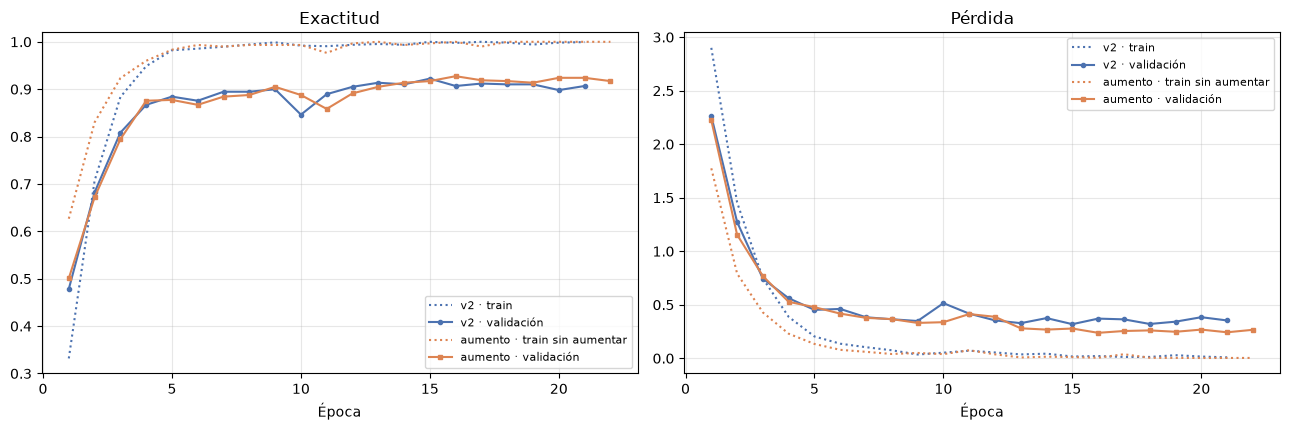

                            train  validación   brecha   época
--------------------------------------------------------------
v2                        100.0%      92.2%   +7.8%      15
con aumento               100.0%      92.7%   +7.3%      16

Valores en la mejor época de cada modelo (la que se guarda).
En el v2, 'train' se mide en la misma pasada del entrenamiento; con aumento, sobre
300 videos de train sin aumentar al final de la época.


In [6]:
hist_v2 = ta.leer_historial(ta.DIR_V2)
hist_aug = ta.leer_historial(ta.DIR_AUG)
col = lambda h, k: [f[k] for f in h]
mejor_v2 = max(hist_v2, key=lambda f: f["acc_dev"])
mejor_aug = max(hist_aug, key=lambda f: f["acc_dev"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4))
ax1.plot(col(hist_v2, "epoca"), col(hist_v2, "acc_train"), color=AZUL, ls=":", label="v2 · train")
ax1.plot(col(hist_v2, "epoca"), col(hist_v2, "acc_dev"), color=AZUL, marker="o", ms=3,
         label="v2 · validación")
ax1.plot(col(hist_aug, "epoca"), col(hist_aug, "acc_train_limpio"), color=NARANJA, ls=":",
         label="aumento · train sin aumentar")
ax1.plot(col(hist_aug, "epoca"), col(hist_aug, "acc_dev"), color=NARANJA, marker="s", ms=3,
         label="aumento · validación")
ax1.set_ylim(0.3, 1.02)
ax1.set_title("Exactitud")

ax2.plot(col(hist_v2, "epoca"), col(hist_v2, "loss_train"), color=AZUL, ls=":", label="v2 · train")
ax2.plot(col(hist_v2, "epoca"), col(hist_v2, "loss_dev"), color=AZUL, marker="o", ms=3,
         label="v2 · validación")
ax2.plot(col(hist_aug, "epoca"), col(hist_aug, "loss_train_limpio"), color=NARANJA, ls=":",
         label="aumento · train sin aumentar")
ax2.plot(col(hist_aug, "epoca"), col(hist_aug, "loss_dev"), color=NARANJA, marker="s", ms=3,
         label="aumento · validación")
ax2.set_title("Pérdida")
for ax in (ax1, ax2):
    ax.set_xlabel("Época"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"{'':<24} {'train':>8} {'validación':>11} {'brecha':>8} {'época':>7}")
print("-" * 62)
for nombre, f, clave in (("v2", mejor_v2, "acc_train"), ("con aumento", mejor_aug, "acc_train_limpio")):
    print(f"{nombre:<24} {f[clave]:>7.1%} {f['acc_dev']:>10.1%} "
          f"{f[clave] - f['acc_dev']:>+7.1%} {f['epoca']:>7}")
print("\nValores en la mejor época de cada modelo (la que se guarda).")
print("En el v2, 'train' se mide en la misma pasada del entrenamiento; con aumento, sobre")
print("300 videos de train sin aumentar al final de la época.")

## Paso 26 — Comparación de los modelos

Los modelos se entrenaron con los mismos datos y la misma división por señalante, y se
evalúan sobre el mismo conjunto de prueba, que nunca se usó para elegir ningún modelo.
Las predicciones de los Transformers y del v2 se leen de los archivos que dejó cada
entrenamiento, sin volver a ejecutar nada.

MODELO                     params            pre   exact.   ±95%   rec.M  prec.M    F1 M    Col.   Cort.    Núm.
----------------------------------------------------------------------------------------------------------------
Transformer original      22.29 M             No   51.2%  4.1%  53.2%  56.5%  51.4%  87.5%  56.6%  11.9%
Transformer normalizado   22.29 M             No   65.1%  3.9%  66.2%  69.5%  65.1%  90.0%  70.7%  34.4%
SL-TSSI v2                 7.01 M  Sí (ImageNet)   84.7%  3.0%  83.8%  82.3%  82.0%  98.3%  80.5%  82.1%
SL-TSSI + aumento          7.01 M  Sí (ImageNet)   87.1%  2.8%  85.8%  85.7%  85.2%  96.7%  82.5%  88.7%

exact. = exactitud global · ±95% = margen de error · rec.M / prec.M / F1 M = promedios macro


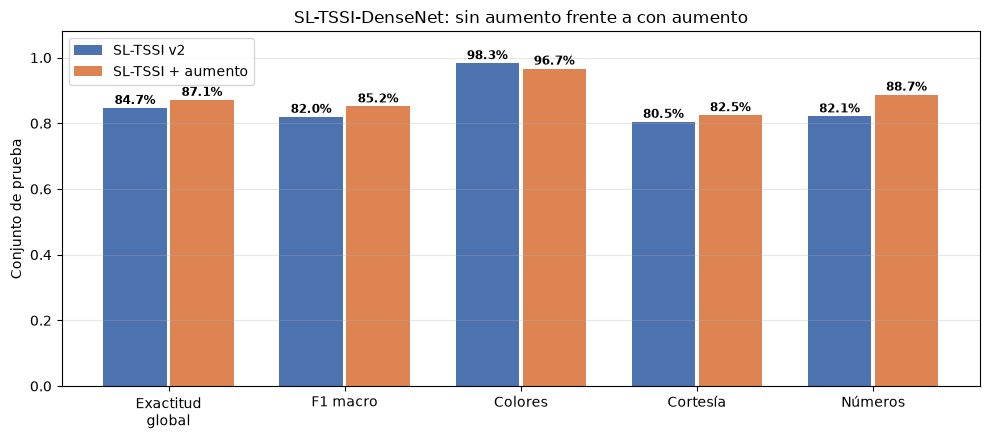

In [7]:
N_PARAMS_SLT = 22_287_424          # Transformer de signjoey, contado sobre su checkpoint

reales = [e["gloss"] for e in DA.test]
MODELOS_CMP = {}
for nombre, carpeta in (("Transformer original", "lsc_full"),
                        ("Transformer normalizado", "lsc_norm")):
    leido = ta.leer_transformer(carpeta)
    if leido is not None:
        assert leido[0] == reales, f"El test de {carpeta} no coincide"
        MODELOS_CMP[nombre] = (leido[1], N_PARAMS_SLT, "No")
MODELOS_CMP["SL-TSSI v2"] = (ta.leer_predicciones(ta.DIR_V2)[1], N_PARAMS_TSSI, "Sí (ImageNet)")
MODELOS_CMP["SL-TSSI + aumento"] = (pred_aug, N_PARAMS_TSSI, "Sí (ImageNet)")

res_cmp = {n: ta.metricas(reales, p, DA.clases, DA.grupo) for n, (p, _, _) in MODELOS_CMP.items()}

enc = (f"{'MODELO':<24} {'params':>8} {'pre':>14} {'exact.':>8} {'±95%':>6} {'rec.M':>7} "
       f"{'prec.M':>7} {'F1 M':>7} {'Col.':>7} {'Cort.':>7} {'Núm.':>7}")
print(enc)
print("-" * len(enc))
for nombre, r in res_cmp.items():
    _, params, pre = MODELOS_CMP[nombre]
    c = r["por_categoria"]
    print(f"{nombre:<24} {params / 1e6:>6.2f} M {pre:>14} {r['exactitud']:>7.1%} "
          f"{r['margen_95']:>5.1%} {r['recall_macro']:>6.1%} {r['precision_macro']:>6.1%} "
          f"{r['f1_macro']:>6.1%} {c['Colores']:>6.1%} {c['Cortesía']:>6.1%} {c['Números']:>6.1%}")
print("\nexact. = exactitud global · ±95% = margen de error · rec.M / prec.M / F1 M = promedios macro")

# Gráfico: v2 frente a aumento.
v2, aug = res_cmp["SL-TSSI v2"], res_cmp["SL-TSSI + aumento"]
etiquetas = ["Exactitud\nglobal", "F1 macro", "Colores", "Cortesía", "Números"]
valores_v2 = [v2["exactitud"], v2["f1_macro"]] + [v2["por_categoria"][k] for k in ta.CATEGORIAS]
valores_aug = [aug["exactitud"], aug["f1_macro"]] + [aug["por_categoria"][k] for k in ta.CATEGORIAS]
x = np.arange(len(etiquetas))
fig, ax = plt.subplots(figsize=(10, 4.5))
for desplazamiento, valores, nombre, color in ((-0.19, valores_v2, "SL-TSSI v2", AZUL),
                                              (0.19, valores_aug, "SL-TSSI + aumento", NARANJA)):
    barras = ax.bar(x + desplazamiento, valores, 0.36, label=nombre, color=color)
    for barra in barras:
        ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 0.012,
                f"{barra.get_height():.1%}", ha="center", fontsize=8.5, fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels(etiquetas)
ax.set_ylim(0, 1.08); ax.set_ylabel("Conjunto de prueba")
ax.set_title("SL-TSSI-DenseNet: sin aumento frente a con aumento")
ax.legend(); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# ¿La diferencia es real o puede ser azar? Prueba de McNemar sobre los mismos 568 videos.
pred_v2 = MODELOS_CMP["SL-TSSI v2"][0]
solo_v2, solo_aug, p_valor = ta.mcnemar(reales, pred_v2, pred_aug)
print("PRUEBA DE McNEMAR (v2 frente a aumento, mismos videos de prueba)")
print(f"  videos que solo acierta el v2:        {solo_v2}")
print(f"  videos que solo acierta con aumento:  {solo_aug}")
print(f"  valor p: {p_valor:.3f}  ->  "
      + ("diferencia significativa (p < 0,05)" if p_valor < 0.05
         else "la diferencia puede deberse al azar (p ≥ 0,05)"))

# Cambios por seña.
filas_v2, filas_aug = v2["por_clase"], aug["por_clase"]
videos_train = Counter(e["gloss"] for e in DA.train)
print(f"\nLAS 10 SEÑAS MÁS DÉBILES DEL v2 (F1 en prueba)")
print(f"{'seña':<16} {'cat.':<9} {'train':>6} {'F1 v2':>8} {'F1 aum.':>8} {'cambio':>8}")
print("-" * 60)
for glosa in sorted(DA.clases, key=lambda g: filas_v2[g]["f1"])[:10]:
    a, b = filas_v2[glosa]["f1"], filas_aug[glosa]["f1"]
    print(f"{glosa:<16} {DA.grupo[glosa]:<9} {videos_train[glosa]:>6} {a:>7.1%} {b:>7.1%} {b - a:>+7.1%}")

cambios = sorted(DA.clases, key=lambda g: filas_aug[g]["f1"] - filas_v2[g]["f1"])
print("\nSEÑAS QUE MÁS GANAN Y MÁS PIERDEN CON EL AUMENTO (F1)")
for glosa in cambios[::-1][:5] + cambios[:5]:
    a, b = filas_v2[glosa]["f1"], filas_aug[glosa]["f1"]
    print(f"  {glosa:<16} {DA.grupo[glosa]:<9} {a:>7.1%} -> {b:>6.1%}  ({b - a:+.1%})")

confusiones = Counter((r, p) for r, p in zip(reales, pred_aug) if r != p)
print("\nCONFUSIONES MÁS FRECUENTES CON AUMENTO")
for (real, predicha), veces in confusiones.most_common(8):
    print(f"  {real:<20} -> {predicha:<20} {veces}x")

PRUEBA DE McNEMAR (v2 frente a aumento, mismos videos de prueba)
  videos que solo acierta el v2:        20
  videos que solo acierta con aumento:  34
  valor p: 0.076  ->  la diferencia puede deberse al azar (p ≥ 0,05)

LAS 10 SEÑAS MÁS DÉBILES DEL v2 (F1 en prueba)
seña             cat.       train    F1 v2  F1 aum.   cambio
------------------------------------------------------------
Maso Menos       Cortesía      16    0.0%   83.3%  +83.3%
Si               Cortesía      14   36.4%   36.4%   +0.0%
Gracias          Cortesía      14   40.0%   60.0%  +20.0%
Necesitar        Cortesía      14   47.1%   57.1%  +10.1%
Tranquilo        Cortesía      14   50.0%   40.0%  -10.0%
Excelente        Cortesía      15   57.1%   66.7%   +9.5%
Baño             Cortesía      14   66.7%   83.3%  +16.7%
Invitar          Cortesía      15   70.6%  100.0%  +29.4%
Con gusto        Cortesía      16   71.4%   90.9%  +19.5%
dies             Números       29   73.3%   83.9%  +10.5%

SEÑAS QUE MÁS GANAN Y MÁS PIE

## Conclusiones del aumento de datos

**El aumento mejoró el modelo en casi todas las métricas.** Mismo modelo, mismos datos,
misma semilla y misma receta de entrenamiento; lo único que cambió es el aumento.

| Conjunto de prueba (568 videos) | v2 | Con aumento | Cambio |
|---|---|---|---|
| Exactitud | 84,7 % | **87,1 %** | +2,5 |
| Videos mal clasificados | 87 | **73** | −14 |
| F1 macro | 82,0 % | **85,2 %** | +3,2 |
| Recall macro | 83,8 % | **85,8 %** | +2,0 |
| Precisión macro | 82,3 % | **85,7 %** | +3,4 |
| Colores | **98,3 %** | 96,7 % | −1,7 |
| Cortesía | 80,5 % | **82,5 %** | +2,0 |
| Números | 82,1 % | **88,7 %** | +6,6 |
| Errores entre categorías | 28 | **23** | −5 |

**Dónde se ganó.** Lo que más mejora son los **números** (+6,6 puntos), que se distinguen
solo por la forma de la mano, y las **señas de cortesía más débiles**, que tienen apenas
14 a 16 videos de entrenamiento: «Maso Menos» pasa de 0 % a 83 % de F1, «Invitar» de
71 % a 100 %, «Gracias» de 40 % a 60 % y «Con gusto» de 71 % a 91 %. En total mejoran
29 señas, empeoran 15 y 10 quedan igual. La caída en colores son 2 videos de 120, y la de
señas como «No» o «negro» se basa en 6 a 12 videos por seña; deben leerse como ruido
mientras no se repita el entrenamiento.

**Generaliza mejor a personas nuevas.** La diferencia entre validación y prueba bajó de
7,5 a 5,6 puntos, la pérdida mínima en validación bajó de 0,32 a 0,24, y desde la época 14
la exactitud en validación se mantiene estable entre 91,4 % y 92,7 %, mientras que el v2
oscilaba más. Una pérdida menor con exactitud parecida significa que el modelo se equivoca
con menos confianza.

**Pero no eliminó la memorización.** Con aumento, la exactitud en train sin aumentar
llega igual al 100 % (desde la época 13), y la brecha entre train y validación en la mejor
época apenas cambia (7,3 frente a 7,8 puntos). Las transformaciones elegidas son suaves:
ayudan con la variación entre personas, pero no impiden que la red aprenda de memoria los
1.733 videos.

**Hay que ser cautos con la significancia.** La prueba de McNemar compara los dos modelos
video por video: 34 videos solo los acierta el modelo con aumento y 20 solo el v2, con un
valor p de 0,076. No alcanza el umbral habitual de 0,05, así que con una sola corrida **no
se puede descartar que parte de la mejora sea azar**. Lo que sí pesa a favor es que todas
las señales apuntan en la misma dirección: exactitud, F1, precisión, recall, pérdida de
validación y distancia entre validación y prueba.

**Costo.** El entrenamiento tomó 22 épocas y 2,8 horas, frente a 21 épocas y 2,2 horas del
v2. El modelo tiene los mismos 7,0 millones de parámetros, así que predecir cuesta lo mismo.

**Decisión.** SL-TSSI-DenseNet con aumento pasa a ser el mejor modelo del proyecto: es igual
o mejor en casi todo y no tiene costo extra al usarlo. Se reporta 87,1 % ± 2,8 % de
exactitud en prueba, con la advertencia de que la diferencia con el v2 no es concluyente
estadísticamente.

### Qué seguiría

- **Repetir los dos entrenamientos con varias semillas** (por ejemplo, 3 a 5) y comparar
  promedios. Es la forma de saber si los +2,5 puntos son reales.
- **Aumento más fuerte**, ya que el modelo todavía memoriza train: rangos más amplios de
  rotación y estiramiento, o técnicas como *mixup* entre videos.
- **Pesos por clase** en la función de pérdida, para compensar las señas de cortesía con
  14 videos frente a los 75 de cada color.